# DSA80003: Data Mining
**Group:** 4 

**Members:**

**Submission Date:** 26th November, 2026

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotnine
from pathlib import Path
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

## Data Collection

In [2]:
# 1. Define root path
data_dir = Path("UCI HAR Dataset")
dataset_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# 2. Check if dataset exists; if not, provide instructions or auto-download
if not data_dir.exists():
    print(f"Dataset folder '{data_dir}' not found locally.")
    print("Attempting to automatically download the UCI HAR dataset...")
    
    try:
        zip_path = Path("uci_har.zip")
        urllib.request.urlretrieve(dataset_url, zip_path)
        
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            
        # The UCI zip contains a nested zip or folder structure sometimes, 
        # let's clean up the zip file
        zip_path.unlink()
        print("Dataset downloaded and extracted successfully!")
        
    except Exception as e:
        raise FileNotFoundError(
            f"Could not automatically download the dataset: {e}\n\n"
            f"Please download 'Human Activity Recognition Using Smartphones' manually from:\n"
            f"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n"
            f"Extract the 'UCI HAR Dataset' folder into your project root directory."
        )

# 3. Load features safely
features_file = data_dir / "features.txt"
if not features_file.exists():
    raise FileNotFoundError(f"Required file missing: {features_file}. Check your folder structure.")

features_df = pd.read_csv(features_file, sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique. The 42 bandsEnergy names each appear three times, once per
# X, Y, Z axis in that order, so append the axis (same scheme as Task 1).
name_counts = pd.Series(raw_feature_names).value_counts()
seen = {}
feature_names = []
for name in raw_feature_names:
    if name_counts[name] > 1:
        k = seen.get(name, 0)
        seen[name] = k + 1
        feature_names.append(f"{name}-{'XYZ'[k]}")
    else:
        feature_names.append(name)
assert len(set(feature_names)) == len(feature_names) == 561

print(f"Successfully loaded {len(feature_names)} unique feature names.")

Successfully loaded 561 unique feature names.


### Split Dataset

In [3]:
import pandas as pd
from pathlib import Path

# 1. Define root path and load features ONCE (since they are shared between train and test)
data_dir = Path("UCI HAR Dataset")

# feature_names comes from the Data Collection cell above


# 2. Create a reusable function for loading any split ('train' or 'test')
def load_har_split(split_name: str, data_dir: Path, feature_names: list) -> pd.DataFrame:
    """
    Loads and combines subject IDs, activity labels, and features 
    for a given dataset split ('train' or 'test').
    """
    split_dir = data_dir / split_name
    
    # Load individual components dynamically based on the split name
    X = pd.read_csv(split_dir / f"X_{split_name}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(split_dir / f"y_{split_name}.txt", sep=r"\s+", header=None, names=["activity_id"])
    subject = pd.read_csv(split_dir / f"subject_{split_name}.txt", sep=r"\s+", header=None, names=["subject_id"])
    
    # Combine everything into a single DataFrame
    df = pd.concat([subject, y, X], axis=1)
    
    return df


# 3. Load both train and test sets easily using the function
train_df = load_har_split("train", data_dir, feature_names)
test_df = load_har_split("test", data_dir, feature_names)

# Preview results
print(f"Train shape: {train_df.shape}")  # Should show (7352, 563)
print(f"Test shape:  {test_df.shape}")   # Should show (2947, 563)

Train shape: (7352, 563)
Test shape:  (2947, 563)


## Dataset Preprocessing

### Missingness Analysis

In [4]:
# 1. Check for missing values
train_missing = train_df.isnull().sum().sum()
test_missing = test_df.isnull().sum().sum()
print(f"Missing values -> Train: {train_missing} | Test: {test_missing}")

# 2. Check for duplicate rows
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows -> Train: {train_dups} | Test: {test_dups}")

# 3. Inspect shapes and target distributions
print(f"\nTrain shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Missing values -> Train: 0 | Test: 0


Duplicate rows -> Train: 0 | Test: 0

Train shape: (7352, 563)
Test shape:  (2947, 563)


Retrieve Feature Columns

### Apply standard scaling

Retain both the scaled and unscaled version

In [5]:
train_df

,subject_id,activity_id,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7347,30,2,0.299665,-0.057193,-0.181233,-0.195387,0.039905,0.077078,-0.282301,0.043616,...,-0.070157,-0.588433,-0.880324,-0.190437,0.829718,0.206972,-0.425619,-0.791883,0.238604,0.049819
7348,30,2,0.273853,-0.007749,-0.147468,-0.235309,0.004816,0.059280,-0.322552,-0.029456,...,0.165259,-0.390738,-0.680744,0.064907,0.875679,-0.879033,0.400219,-0.771840,0.252676,0.050053
7349,30,2,0.273387,-0.017011,-0.045022,-0.218218,-0.103822,0.274533,-0.304515,-0.098913,...,0.195034,0.025145,-0.304029,0.052806,-0.266724,0.864404,0.701169,-0.779133,0.249145,0.040811
7350,30,2,0.289654,-0.018843,-0.158281,-0.219139,-0.111412,0.268893,-0.310487,-0.068200,...,0.013865,0.063907,-0.344314,-0.101360,0.700740,0.936674,-0.589479,-0.785181,0.246432,0.025339


In [6]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate features from metadata
meta_cols = ["subject_id", "activity_id"]

X_train = train_df.drop(columns=meta_cols)
X_test = test_df.drop(columns=meta_cols)

# Preserve metadata separately
meta_train = train_df[meta_cols].copy()
# Preserve metadata separately for test
meta_test = test_df[meta_cols].copy()

# Readable activity names in the metadata (used for interpretation only, never as model input)
activity_labels = pd.read_csv(data_dir / "activity_labels.txt", sep=r"\s+", header=None,
                              names=["activity_id", "activity_name"])
ACTIVITY_NAMES = dict(zip(activity_labels["activity_id"], activity_labels["activity_name"]))
ACTIVITY_ORDER = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]
meta_train["activity_name"] = meta_train["activity_id"].map(ACTIVITY_NAMES)
meta_test["activity_name"] = meta_test["activity_id"].map(ACTIVITY_NAMES)

# Initialize the scaler
scaler = StandardScaler()

# Fit on the training features and transform both train and test sets
# (Fitting strictly on train to prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve original 561 feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print(f"Scaled Training Shape: {X_train_scaled_df.shape}")
print(f"Scaled Testing Shape:  {X_test_scaled_df.shape}")

Scaled Training Shape: (7352, 561)
Scaled Testing Shape:  (2947, 561)


### Items to use for EDA

In [7]:
print(f"Unscaled Dataset: ", X_train.shape)
print(f"Scaled dataset: ", X_train_scaled.shape)
print(f"Metadata (subject, activity id/name) for training set: ", meta_train.shape)
print(f"Metadata (subject, activity id/name) for test set: ", meta_test.shape)

Unscaled Dataset:  (7352, 561)
Scaled dataset:  (7352, 561)
Metadata (subject, activity id/name) for training set:  (7352, 3)
Metadata (subject, activity id/name) for test set:  (2947, 3)


## Exploratory Data Analysis
Models and scores use the sensor features only. Activity labels and subject IDs are used afterwards, to interpret what the sensor data show.

### Task 1 — Data quality and feature characteristics
Objective: Understand the quality and structure of the sensor measurements.

**Member**: Atharva

What needs to be done:

1. Check missing values, duplicates, constant features and extreme values.
2. Examine feature distributions and variance.
3. Identify highly correlated and redundant features.
4. Group features by their physical meaning: acceleration, gyroscope, gravity, jerk, time-domain and frequency-domain.
5. Examine how standardisation and duplicate-feature removal change feature distributions and relative weighting.

Expected output: A summary of data quality, feature redundancy and recommended preprocessing decisions.

*Code merged from Task1_EDA/Task1_EDA_Data_Quality.ipynb.*

**Member:** Atharva

**Objective.** Understand the quality and structure of the 561 pre-computed sensor features before any modelling, and turn that into concrete preprocessing decisions.

**Dataset in brief.** 30 volunteers performed six activities (walking, walking upstairs, walking downstairs, sitting, standing, laying) with a Samsung Galaxy S II on the waist. The accelerometer and gyroscope were sampled at 50 Hz and cut into 2.56 s windows with 50 % overlap. Each window was summarised into 561 time- and frequency-domain features, which the dataset authors normalised to the range [−1, 1]. Subjects are split 70/30 into train (21 people) and test (9 people).

| Section | Task item |
|---|---|
| 1. Setup, loading and feature metadata | — |
| 2. Data quality: missing values, duplicates, constant features, extreme values | 1 |
| 3. Feature distributions and variance | 2 |
| 4. Correlation and redundancy | 3 |
| 5. Features grouped by physical meaning | 4 |
| 6. Effect of standardisation and duplicate-feature removal | 5 |
| 7. Summary and recommended preprocessing | Expected output |

> **Leakage note.** Every statistic that feeds a preprocessing decision (scaling parameters, correlation filter, outlier thresholds) is computed on the **training split only**. The test split is used only for checks that must cover it (missing values, duplicates, value range) and to see how train-fitted scaling transfers to unseen subjects.

##### 1. Setup, loading and feature metadata

In [8]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})

SAVE_OUTPUTS = True                  # section 7 writes a per-feature audit CSV
OUTPUT_DIR = Path("task1_outputs")

In [9]:
# Reuse the dataset folder found by the shared Data Collection cell
DATA_DIR = Path(data_dir)
print("Data folder:", DATA_DIR)

Data folder: UCI HAR Dataset


In [10]:
# Task 1 reloads the raw splits with its own helpers. Feature names use the same scheme as the
# shared setup, so X_train / X_test here are identical to the shared ones.
def read_table(path, **kwargs):
    return pd.read_csv(path, sep=r"\s+", header=None, **kwargs)


features_raw = read_table(DATA_DIR / "features.txt", names=["idx", "raw_name"])
activity_map = read_table(DATA_DIR / "activity_labels.txt", names=["id", "activity"]).set_index("id")["activity"]


def make_unique(names: pd.Series) -> list:
    """The 42 bandsEnergy names each appear three times - once per X, Y, Z axis, in that order.
    Append the axis so every column name is unique and still meaningful."""
    counts, seen, out = names.value_counts(), {}, []
    for n in names:
        if counts[n] > 1:
            k = seen.get(n, 0)
            seen[n] = k + 1
            out.append(f"{n}-{'XYZ'[k]}")
        else:
            out.append(n)
    return out


feature_names = make_unique(features_raw["raw_name"])
assert len(set(feature_names)) == len(feature_names) == 561


def load_split(split):
    X = read_table(DATA_DIR / split / f"X_{split}.txt")
    X.columns = feature_names
    y = read_table(DATA_DIR / split / f"y_{split}.txt")[0].map(activity_map).rename("activity")
    s = read_table(DATA_DIR / split / f"subject_{split}.txt")[0].rename("subject")
    assert len(X) == len(y) == len(s), f"row mismatch in {split}"
    return X, y, s


X_train, y_train, subj_train = load_split("train")
X_test, y_test, subj_test = load_split("test")

ACTIVITY_ORDER = list(activity_map.values)
STATIC = {"SITTING", "STANDING", "LAYING"}
motion_train = y_train.map(lambda a: "static" if a in STATIC else "dynamic").rename("motion")
MOTION_COLORS = {"static": "#1f77b4", "dynamic": "#d62728"}

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
X_train.iloc[:5, :8]

Train: (7352, 561)   Test: (2947, 561)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y
0,0.2886,-0.0203,-0.1329,-0.9953,-0.9831,-0.9135,-0.9951,-0.9832
1,0.2784,-0.0164,-0.1235,-0.9982,-0.9753,-0.9603,-0.9988,-0.9749
2,0.2797,-0.0195,-0.1135,-0.9954,-0.9672,-0.9789,-0.9965,-0.9637
3,0.2792,-0.0262,-0.1233,-0.9961,-0.9834,-0.9907,-0.9971,-0.9827
4,0.2766,-0.0166,-0.1154,-0.9981,-0.9808,-0.9905,-0.9983,-0.9797


###### 1.1 Decoding the feature names
Every feature name encodes its physical meaning, e.g. `tBodyAccJerk-std()-X` = **t**ime domain, **Body** component, **Acc**elerometer, **Jerk** (time derivative), standard deviation, X axis. The parser below turns the 561 names into a metadata table that the rest of the notebook uses for grouping. Two quirks of the original files are handled here:
* `fBodyBody…` is a known typo for `fBody…`.
* The 126 `bandsEnergy` columns only have 42 distinct names; the axis suffix added above fixes that.

Features are assigned to ten physical groups: domain (time `t`, frequency `f`) × signal (body acceleration, body-acceleration jerk, gravity acceleration, body angular velocity, angular-velocity jerk), plus the seven `angle()` features. Magnitude (`Mag`) features stay in their parent group and are flagged separately.

In [11]:
def parse_feature(name: str) -> dict:
    """Decode a UCI HAR feature name into its physical components."""
    if name.startswith("angle("):
        inner = name[len("angle("):-1]
        return dict(domain="Angle", signal="angle", sensor="acc+gyro" if "Gyro" in inner else "accelerometer",
                    component="angle vs gravity", jerk="Jerk" in inner, magnitude=False,
                    axis=inner[0] if inner[0] in "XYZ" else None, statistic="angle", group="Angle vs gravity")

    prefix, rest = name.split("-", 1)
    domain = "Time" if prefix[0] == "t" else "Frequency"
    signal = prefix[0] + prefix[1:].replace("BodyBody", "Body")      # fix the 'BodyBody' typo
    magnitude = signal.endswith("Mag")
    base = signal[1:-3] if magnitude else signal[1:]
    sensor = "gyroscope" if "Gyro" in base else "accelerometer"
    component = "gravity" if base.startswith("Gravity") else "body"
    jerk = "Jerk" in base
    statistic = re.match(r"[A-Za-z]+", rest).group(0)

    axis = None
    for tok in rest.split("-")[1:]:
        if statistic == "correlation":                 # e.g. correlation()-X,Y
            axis = tok
            break
        if tok and tok[0] in "XYZ" and (len(tok) == 1 or tok[1] == ","):
            axis = tok[0]
            break

    if component == "gravity":
        phys = "Gravity acc"
    else:
        phys = ("Body gyro" if sensor == "gyroscope" else "Body acc") + (" jerk" if jerk else "")
    return dict(domain=domain, signal=signal, sensor=sensor, component=component, jerk=jerk,
                magnitude=magnitude, axis=axis, statistic=statistic, group=f"{prefix[0]} · {phys}")


GROUP_ORDER = ["t · Body acc", "t · Body acc jerk", "t · Gravity acc", "t · Body gyro", "t · Body gyro jerk",
               "f · Body acc", "f · Body acc jerk", "f · Body gyro", "f · Body gyro jerk", "Angle vs gravity"]
GROUP_COLORS = dict(zip(GROUP_ORDER, sns.color_palette("tab10", len(GROUP_ORDER))))

meta = pd.DataFrame([parse_feature(n) for n in feature_names], index=feature_names)
meta.insert(0, "raw_name", features_raw["raw_name"].values)
meta.insert(0, "col", np.arange(len(meta)))
assert set(meta["group"]) == set(GROUP_ORDER), set(meta["group"]) ^ set(GROUP_ORDER)
meta["group"] = pd.Categorical(meta["group"], categories=GROUP_ORDER, ordered=True)
group_of = meta["group"].astype(str)

meta.sample(8, random_state=3)

,col,raw_name,domain,signal,sensor,component,jerk,magnitude,axis,statistic,group
tBodyGyro-mean()-Y,121,tBodyGyro-mean()-Y,Time,tBodyGyro,gyroscope,body,False,False,Y,mean,t · Body gyro
fBodyGyro-energy()-X,439,fBodyGyro-energy()-X,Frequency,fBodyGyro,gyroscope,body,False,False,X,energy,f · Body gyro
"fBodyAcc-bandsEnergy()-33,40-Z",334,"fBodyAcc-bandsEnergy()-33,40",Frequency,fBodyAcc,accelerometer,body,False,False,Z,bandsEnergy,f · Body acc
fBodyAcc-std()-Z,270,fBodyAcc-std()-Z,Frequency,fBodyAcc,accelerometer,body,False,False,Z,std,f · Body acc
fBodyAccJerk-max()-Z,355,fBodyAccJerk-max()-Z,Frequency,fBodyAccJerk,accelerometer,body,True,False,Z,max,f · Body acc jerk
"angle(Z,gravityMean)",560,"angle(Z,gravityMean)",Angle,angle,accelerometer,angle vs gravity,False,False,Z,angle,Angle vs gravity
tGravityAcc-mad()-Z,48,tGravityAcc-mad()-Z,Time,tGravityAcc,accelerometer,gravity,False,False,Z,mad,t · Gravity acc
fBodyAcc-entropy()-X,287,fBodyAcc-entropy()-X,Frequency,fBodyAcc,accelerometer,body,False,False,X,entropy,f · Body acc


##### 2. Data quality
###### 2.1 Overview and class balance

In [12]:
overview = pd.DataFrame({
    "windows (rows)": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
    "subjects": [subj_train.nunique(), subj_test.nunique()],
    "dtypes": [", ".join(map(str, X_train.dtypes.unique())), ", ".join(map(str, X_test.dtypes.unique()))],
    "min value": [X_train.to_numpy().min(), X_test.to_numpy().min()],
    "max value": [X_train.to_numpy().max(), X_test.to_numpy().max()],
}, index=["train", "test"])
display(overview)
print("Subjects in both train and test:", sorted(set(subj_train) & set(subj_test)) or "none")

class_balance = (pd.concat([y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)],
                           axis=1, keys=["train %", "test %"])
                 .reindex(ACTIVITY_ORDER).mul(100).round(1))
class_balance

,windows (rows),features,subjects,dtypes,min value,max value
train,7352,561,21,float64,-1.0,1.0
test,2947,561,9,float64,-1.0,1.0


Subjects in both train and test: none


,train %,test %
activity,,
WALKING,16.7,16.8
WALKING_UPSTAIRS,14.6,16.0
WALKING_DOWNSTAIRS,13.4,14.3
SITTING,17.5,16.7
STANDING,18.7,18.1
LAYING,19.1,18.2


###### 2.2 Missing and non-finite values

In [13]:
def non_finite_report(X, y, s, name):
    arr = X.to_numpy()
    return pd.Series({
        "NaN cells in X": int(np.isnan(arr).sum()),
        "±inf cells in X": int(np.isinf(arr).sum()),
        "rows with any NaN": int(X.isna().any(axis=1).sum()),
        "missing labels": int(y.isna().sum()),
        "missing subject ids": int(s.isna().sum()),
    }, name=name)


pd.concat([non_finite_report(X_train, y_train, subj_train, "train"),
           non_finite_report(X_test, y_test, subj_test, "test")], axis=1)

,train,test
NaN cells in X,0,0
±inf cells in X,0,0
rows with any NaN,0,0
missing labels,0,0
missing subject ids,0,0


###### 2.3 Duplicates
Three different kinds of duplication are checked:
1. **Duplicate rows** — the same window recorded twice, within or across splits.
2. **Duplicate feature names** — columns sharing a name in `features.txt`.
3. **Duplicate feature values** — differently named columns that hold identical numbers.

In [14]:
h_train = pd.util.hash_pandas_object(X_train, index=False)
h_test = pd.util.hash_pandas_object(X_test, index=False)
pd.Series({
    "duplicate rows within train": int(h_train.duplicated().sum()),
    "duplicate rows within test": int(h_test.duplicated().sum()),
    "test rows identical to a train row": int(h_test.isin(set(h_train)).sum()),
}).to_frame("count")

,count
duplicate rows within train,0
duplicate rows within test,0
test rows identical to a train row,0


In [15]:
dup_names = features_raw["raw_name"].value_counts().loc[lambda s: s > 1]
print(f"{len(dup_names)} names occur more than once -> {int(dup_names.sum())} columns affected "
      f"({int((dup_names - 1).sum())} 'extra' columns)")
print("All of them are bandsEnergy features:", bool(dup_names.index.str.contains("bandsEnergy").all()))

# Are the three same-named columns numerically identical? If not, they are different features (X/Y/Z).
arr_train = X_train.to_numpy()
gaps = []
for name in dup_names.index:
    cols = np.flatnonzero(features_raw["raw_name"].to_numpy() == name)
    gaps += [np.abs(arr_train[:, cols[a]] - arr_train[:, cols[b]]).max() for a, b in [(0, 1), (0, 2), (1, 2)]]
min_gap = min(gaps)
print(f"Smallest max-absolute-difference between two same-named columns: {min_gap:.3f}  (0 would mean identical)")

example = dup_names.index[0]
X_train[[c for c in feature_names if c.startswith(example)]].describe().loc[["mean", "std", "min", "max"]]

42 names occur more than once -> 126 columns affected (84 'extra' columns)
All of them are bandsEnergy features: True
Smallest max-absolute-difference between two same-named columns: 0.870  (0 would mean identical)


,"fBodyAcc-bandsEnergy()-1,8-X","fBodyAcc-bandsEnergy()-1,8-Y","fBodyAcc-bandsEnergy()-1,8-Z"
mean,-0.8102,-0.7873,-0.8480
std,0.2833,0.2713,0.2336
min,-1.0000,-1.0000,-1.0000
max,1.0000,1.0000,1.0000


In [16]:
# Exact duplicate *values*: hash every column over train + test together.
X_all = pd.concat([X_train, X_test], ignore_index=True)
arr_all = X_all.to_numpy()
buckets = {}
for j, col in enumerate(feature_names):
    buckets.setdefault(arr_all[:, j].tobytes(), []).append(col)
dup_groups = [g for g in buckets.values() if len(g) > 1]

exact_dup_of = {}                    # dropped column -> column kept (first in file order)
for g in dup_groups:
    assert all(np.array_equal(X_all[g[0]], X_all[c]) for c in g[1:])
    for c in g[1:]:
        exact_dup_of[c] = g[0]
exact_drop = list(exact_dup_of)
keep_dedup = [c for c in feature_names if c not in exact_dup_of]

print(f"{len(dup_groups)} groups of value-identical columns -> {len(exact_drop)} redundant columns "
      f"({len(keep_dedup)} remain)")
pd.DataFrame({"kept": [g[0] for g in dup_groups],
              "identical copies (dropped)": [", ".join(g[1:]) for g in dup_groups]})

19 groups of value-identical columns -> 21 redundant columns (540 remain)


,kept,identical copies (dropped)
0,tBodyAccMag-mean(),"tBodyAccMag-sma(), tGravityAccMag-mean(), tGravityAccMag-sma()"
1,tBodyAccMag-std(),tGravityAccMag-std()
2,tBodyAccMag-mad(),tGravityAccMag-mad()
3,tBodyAccMag-max(),tGravityAccMag-max()
4,tBodyAccMag-min(),tGravityAccMag-min()
5,tBodyAccMag-energy(),tGravityAccMag-energy()
6,tBodyAccMag-iqr(),tGravityAccMag-iqr()
7,tBodyAccMag-entropy(),tGravityAccMag-entropy()
8,tBodyAccMag-arCoeff()1,tGravityAccMag-arCoeff()1
9,tBodyAccMag-arCoeff()2,tGravityAccMag-arCoeff()2


**What the duplicate checks show**
* **Rows:** no duplicate windows within train, within test, or across the two splits. Rows are still *not* independent, though: consecutive windows overlap by 50 %, so neighbouring rows share half their raw samples. Any validation split must keep a subject's windows together (see §7).
* **Names:** 42 `bandsEnergy` names appear three times each (126 columns). The copies are *different* features (every pair of same-named columns differs by at least 0.87 somewhere), namely the X, Y and Z axes, which the original `features.txt` does not label. Renaming them is needed; dropping them would be wrong.
* **Values:** 19 groups of columns are numerically identical, giving **21 redundant columns**:
  * all 13 `tGravityAccMag-*` features equal the matching `tBodyAccMag-*` features. Physically, gravity magnitude should be close to a constant 1 g, so this is almost certainly a bug in the original feature-extraction code. The `tBodyAccMag` name is the one kept.
  * `Mag-sma()` equals `Mag-mean()` for all 8 magnitude signals. This is expected: the signal magnitude area of a one-dimensional, non-negative signal *is* its mean.

  Removing these 21 columns loses no information, leaving **540 features**.

###### 2.4 Constant and near-constant features

In [17]:
const = pd.DataFrame({
    "variance": X_train.var(),
    "n_unique": X_train.nunique(),
    "top_value_share": X_train.apply(lambda c: c.value_counts(normalize=True).iloc[0]),
}).join(meta[["group", "statistic"]])

pd.Series({
    "zero variance": int((const["variance"] == 0).sum()),
    "variance < 0.001": int((const["variance"] < 1e-3).sum()),
    "variance < 0.005": int((const["variance"] < 5e-3).sum()),
    "≤ 50 distinct values": int((const["n_unique"] <= 50).sum()),
    "one value covers > 50% of rows": int((const["top_value_share"] > 0.5).sum()),
    "one value covers > 25% of rows": int((const["top_value_share"] > 0.25).sum()),
}).to_frame("features (train)")

,features (train)
zero variance,0
variance < 0.001,0
variance < 0.005,7
≤ 50 distinct values,11
one value covers > 50% of rows,1
one value covers > 25% of rows,16


In [18]:
print("Fewest distinct values:")
display(const.sort_values("n_unique").head(8))
print("Most dominated by a single value:")
display(const.sort_values("top_value_share", ascending=False).head(8))
print("Statistic type of the features with <= 50 distinct values:",
      const.loc[const["n_unique"] <= 50, "statistic"].value_counts().to_dict())

Fewest distinct values:


,variance,n_unique,top_value_share,group,statistic
fBodyGyro-maxInds-Z,0.0575,25,0.3300,f · Body gyro,maxInds
fBodyAcc-maxInds-Y,0.0607,26,0.3551,f · Body acc,maxInds
fBodyAcc-maxInds-Z,0.0586,26,0.4139,f · Body acc,maxInds
fBodyGyro-maxInds-X,0.0393,27,0.4169,f · Body gyro,maxInds
fBodyBodyGyroMag-maxInds,0.0249,27,0.4110,f · Body gyro,maxInds
fBodyGyro-maxInds-Y,0.0797,29,0.3414,f · Body gyro,maxInds
fBodyAcc-maxInds-X,0.0672,29,0.2990,f · Body acc,maxInds
fBodyAccMag-maxInds,0.0722,29,0.2825,f · Body acc,maxInds


Most dominated by a single value:


,variance,n_unique,top_value_share,group,statistic
tGravityAcc-entropy()-Y,0.0792,1179,0.7346,t · Gravity acc,entropy
tGravityAcc-entropy()-Z,0.1572,2710,0.4831,t · Gravity acc,entropy
tGravityAcc-entropy()-X,0.1333,3168,0.4241,t · Gravity acc,entropy
fBodyAccJerk-entropy()-X,0.5651,3313,0.4226,f · Body acc jerk,entropy
fBodyGyro-maxInds-X,0.0393,27,0.4169,f · Body gyro,maxInds
fBodyAcc-maxInds-Z,0.0586,26,0.4139,f · Body acc,maxInds
fBodyBodyGyroMag-maxInds,0.0249,27,0.4110,f · Body gyro,maxInds
fBodyAccJerk-entropy()-Y,0.5425,3359,0.3874,f · Body acc jerk,entropy


Statistic type of the features with <= 50 distinct values: {'maxInds': 11}


**Constant and near-constant features**
* No feature is constant, and none has variance below 0.001, so a zero-variance filter removes nothing.
* The 11 features with ≤ 50 distinct values are all `maxInds`: the index of the dominant FFT frequency bin, a **discrete** quantity with 25–49 levels. They are usable as numeric/ordinal features but should not be read as continuous distributions.
* Sixteen features have a single value covering more than 25 % of rows. All 16 are `entropy` or `maxInds` features, and in 15 of them the dominant value is the lower bound −1 (the other is a `maxInds` feature whose most common value is its second-lowest level). Section 2.5 shows this is driven by activity, not by a fault.

###### 2.5 Extreme values
All values already sit in [−1, 1], so there are no impossible readings. Two things are still worth checking:
* **Saturation at the bounds** — a large share of rows sitting exactly on −1 or +1 means the min–max normalisation compressed or clipped a tail.
* **Statistical outliers** — values outside the 1.5 × IQR fences of their feature (train only). If outliers are concentrated in particular activities, they are genuine movement rather than sensor faults.

In [19]:
at_min, at_max = X_train.eq(-1).mean(), X_train.eq(1).mean()

Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
out_mask = X_train.lt(lo, axis=1) | X_train.gt(hi, axis=1)
out_mask.loc[:, IQR == 0] = False          # the IQR rule is undefined when IQR is zero
out_rate = out_mask.mean()
row_out_share = out_mask.mean(axis=1)
z = (X_train - X_train.mean()) / X_train.std()
z3_rate = (z.abs() > 3).mean()

extreme = pd.DataFrame({"% at -1": at_min * 100, "% at +1": at_max * 100,
                        "% IQR outliers": out_rate * 100, "% |z|>3": z3_rate * 100}).join(meta["group"])

pd.Series(dtype=object, data={
    "features with IQR = 0": int((IQR == 0).sum()),
    "features with > 5% of rows at -1 or +1": int(((at_min + at_max) > 0.05).sum()),
    "features with > 25% of rows at -1 or +1": int(((at_min + at_max) > 0.25).sum()),
    "median % IQR outliers per feature": round(float(out_rate.median() * 100), 2),
    "features with > 10% IQR outliers": int((out_rate > 0.10).sum()),
    "overall % of cells outside IQR fences": round(float(out_mask.to_numpy().mean() * 100), 2),
    "overall % of cells with |z| > 3": round(float((z.abs() > 3).to_numpy().mean() * 100), 2),
}).to_frame("value")

,value
features with IQR = 0,0
features with > 5% of rows at -1 or +1,21
features with > 25% of rows at -1 or +1,15
median % IQR outliers per feature,1.16
features with > 10% IQR outliers,52
overall % of cells outside IQR fences,3.97
overall % of cells with |z| > 3,0.98


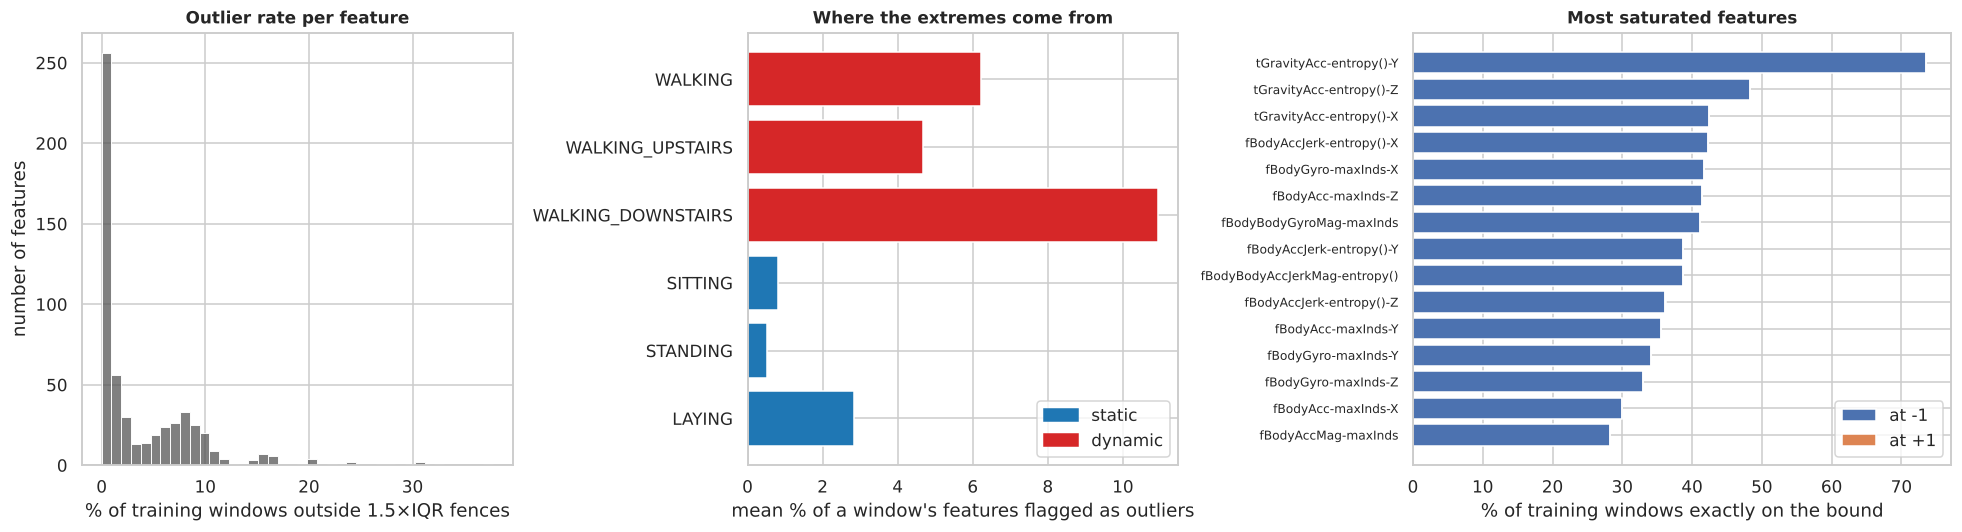

Features with the highest IQR-outlier rate:


,% at -1,% at +1,% IQR outliers,% |z|>3,group
tBodyAccJerk-mean()-X,0.01,0.01,37.79,2.42,t · Body acc jerk
tBodyGyro-mean()-X,0.00,0.00,32.22,2.11,t · Body gyro
tBodyGyroJerk-mean()-X,0.01,0.01,30.55,2.14,t · Body gyro jerk
tBodyAccJerk-mean()-Y,0.01,0.01,30.41,2.27,t · Body acc jerk
tBodyGyroJerk-mean()-Y,0.01,0.00,29.75,2.15,t · Body gyro jerk
tBodyAccJerk-mean()-Z,0.01,0.01,27.50,2.26,t · Body acc jerk
tBodyGyroJerk-mean()-Z,0.01,0.01,27.12,2.23,t · Body gyro jerk
tBodyGyro-mean()-Y,0.00,0.01,24.50,2.24,t · Body gyro


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1, 1.25]})

sns.histplot(out_rate * 100, bins=40, ax=axes[0], color="#555")
axes[0].set(xlabel="% of training windows outside 1.5×IQR fences", ylabel="number of features",
            title="Outlier rate per feature")

act_share = row_out_share.groupby(y_train).mean().reindex(ACTIVITY_ORDER) * 100
axes[1].barh(ACTIVITY_ORDER, act_share.values,
             color=[MOTION_COLORS["static" if a in STATIC else "dynamic"] for a in ACTIVITY_ORDER])
axes[1].invert_yaxis()
axes[1].set(xlabel="mean % of a window's features flagged as outliers", title="Where the extremes come from")
axes[1].legend(handles=[Patch(color=c, label=k) for k, c in MOTION_COLORS.items()], loc="lower right")

sat = extreme.assign(total=lambda d: d["% at -1"] + d["% at +1"]).nlargest(15, "total")
axes[2].barh(sat.index, sat["% at -1"], color="#4c72b0", label="at -1")
axes[2].barh(sat.index, sat["% at +1"], left=sat["% at -1"], color="#dd8452", label="at +1")
axes[2].invert_yaxis()
axes[2].tick_params(axis="y", labelsize=8)
axes[2].set(xlabel="% of training windows exactly on the bound", title="Most saturated features")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Features with the highest IQR-outlier rate:")
extreme.sort_values("% IQR outliers", ascending=False).head(8).round(2)

**Extreme values are real movement, not sensor errors**
* Every value lies in [−1, 1] and no feature has a zero IQR. 4 % of training cells fall outside the 1.5 × IQR fences, but only about 1 % have |z| > 3.
* **80 % of outlier cells come from dynamic windows**, even though they are only 45 % of the rows. Walking downstairs, the most vigorous activity, has about 11 % of a window's features flagged, against under 1 % for sitting or standing. The extremes are the movement signal itself, so removing or clipping them would delete information.
* The highest outlier rates (25–38 %) belong to the `mean()` of the jerk and gyroscope signals. These sit in a very narrow peak around a fixed value with long tails, so the IQR fences are tight. Section 6.2 shows these same features carry almost no activity information.
* **Saturation at −1** affects 21 features by more than 5 %, all of them `entropy` or `maxInds`. It is a floor effect with a physical cause. Example: `fBodyAcc-maxInds-X` is at −1 for 54 % of static windows and 0 % of dynamic ones, because with no movement the dominant frequency is the DC bin. Example: `fBodyAccJerk-entropy()-X` is at −1 for 76 % of static windows and 0 % of dynamic ones, because a still phone produces minimal spectral entropy. The pile-up at −1 is informative and should be kept.

##### 3. Feature distributions and variance
###### 3.1 Shape of the 561 distributions
For each feature (train split): mean, standard deviation, skewness, excess kurtosis and Sarle's bimodality coefficient, BC = (skew² + 1) / (excess kurtosis + 3(n−1)²/((n−2)(n−3))). BC above 5/9 ≈ 0.555 suggests a bimodal or multimodal distribution (strong skew can also push it up).

In [21]:
n = len(X_train)
shape = pd.DataFrame({"mean": X_train.mean(), "std": X_train.std(), "variance": X_train.var(),
                      "skewness": X_train.skew(), "excess kurtosis": X_train.kurt()})
shape["bimodality coef"] = (shape["skewness"] ** 2 + 1) / (
    shape["excess kurtosis"] + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3)))
shape = shape.join(meta[["group", "domain", "statistic"]])

pd.Series({
    "|skewness| > 1": int((shape["skewness"].abs() > 1).sum()),
    "|skewness| > 2": int((shape["skewness"].abs() > 2).sum()),
    "right-skewed (skew > 1)": int((shape["skewness"] > 1).sum()),
    "left-skewed (skew < -1)": int((shape["skewness"] < -1).sum()),
    "excess kurtosis > 3 (heavy tails)": int((shape["excess kurtosis"] > 3).sum()),
    "bimodality coef > 0.555": int((shape["bimodality coef"] > 5 / 9).sum()),
}).to_frame("features (of 561)")

,features (of 561)
|skewness| > 1,277
|skewness| > 2,166
right-skewed (skew > 1),264
left-skewed (skew < -1),13
excess kurtosis > 3 (heavy tails),210
bimodality coef > 0.555,356


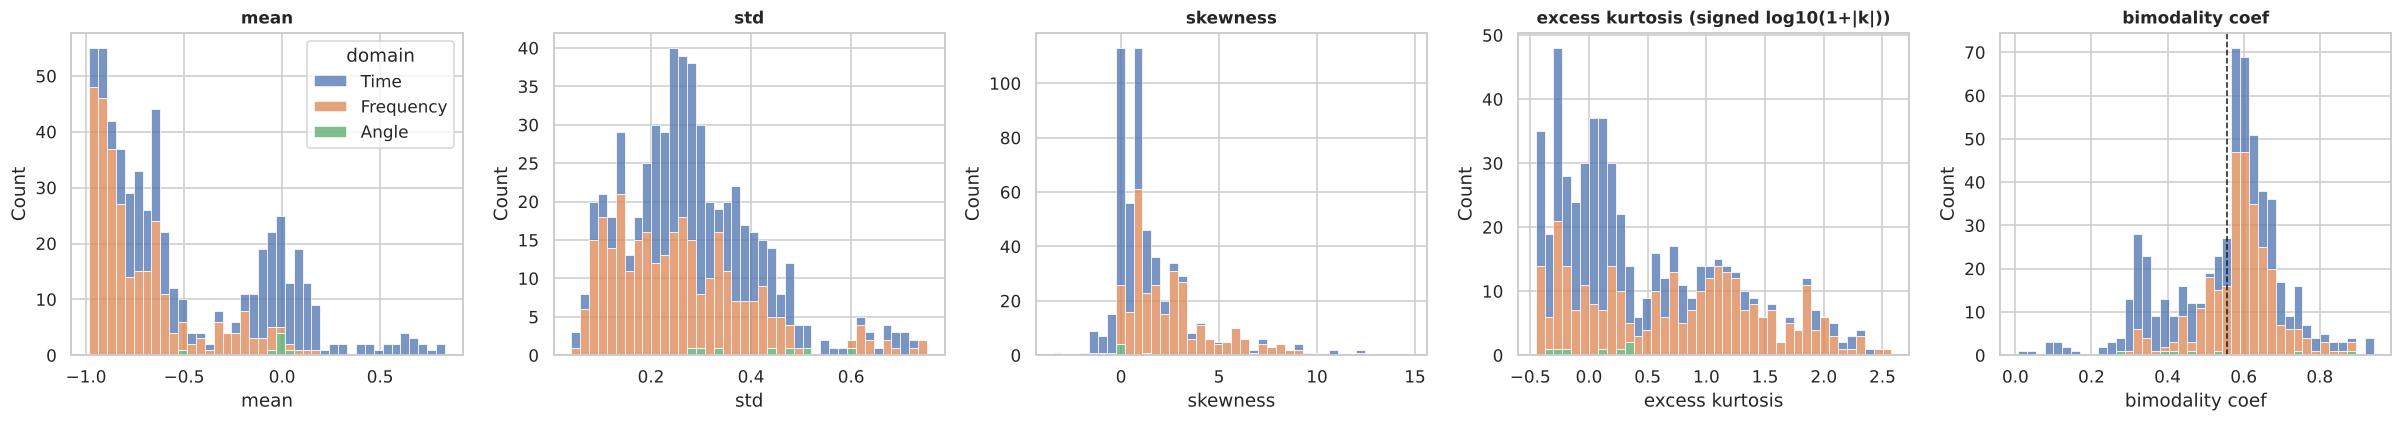

statistic,angle,arCoeff,meanFreq,correlation,entropy,mean,sma,skewness,mad,std,iqr,max,min,kurtosis,maxInds,energy,bandsEnergy
skewness,-0.02,-0.01,0.00,0.07,0.09,0.62,0.65,0.74,0.76,0.82,0.93,0.97,1.19,1.40,1.97,2.20,3.34
excess kurtosis,0.35,0.10,-0.07,-0.18,-1.68,0.66,-0.87,0.31,-0.42,-0.11,0.16,0.30,2.08,1.85,4.57,6.33,18.84
bimodality coef,0.47,0.34,0.35,0.37,0.76,0.58,0.66,0.50,0.63,0.62,0.61,0.61,0.60,0.61,0.60,0.58,0.58


In [22]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, ["mean", "std", "skewness", "excess kurtosis", "bimodality coef"]):
    data = shape.copy()
    if col == "excess kurtosis":
        data[col] = np.sign(data[col]) * np.log10(1 + data[col].abs())
    sns.histplot(data=data, x=col, hue="domain", multiple="stack", bins=40, ax=ax,
                 hue_order=["Time", "Frequency", "Angle"], legend=(col == "mean"))
    ax.set_title(col if col != "excess kurtosis" else "excess kurtosis (signed log10(1+|k|))")
axes[4].axvline(5 / 9, color="k", ls="--", lw=1)
plt.tight_layout()
plt.show()

shape.groupby("statistic")[["skewness", "excess kurtosis", "bimodality coef"]].median().sort_values("skewness").round(2).T

###### 3.2 What typical features look like
Eight representative features, split by static (sitting, standing, laying) vs dynamic (walking variants) windows.

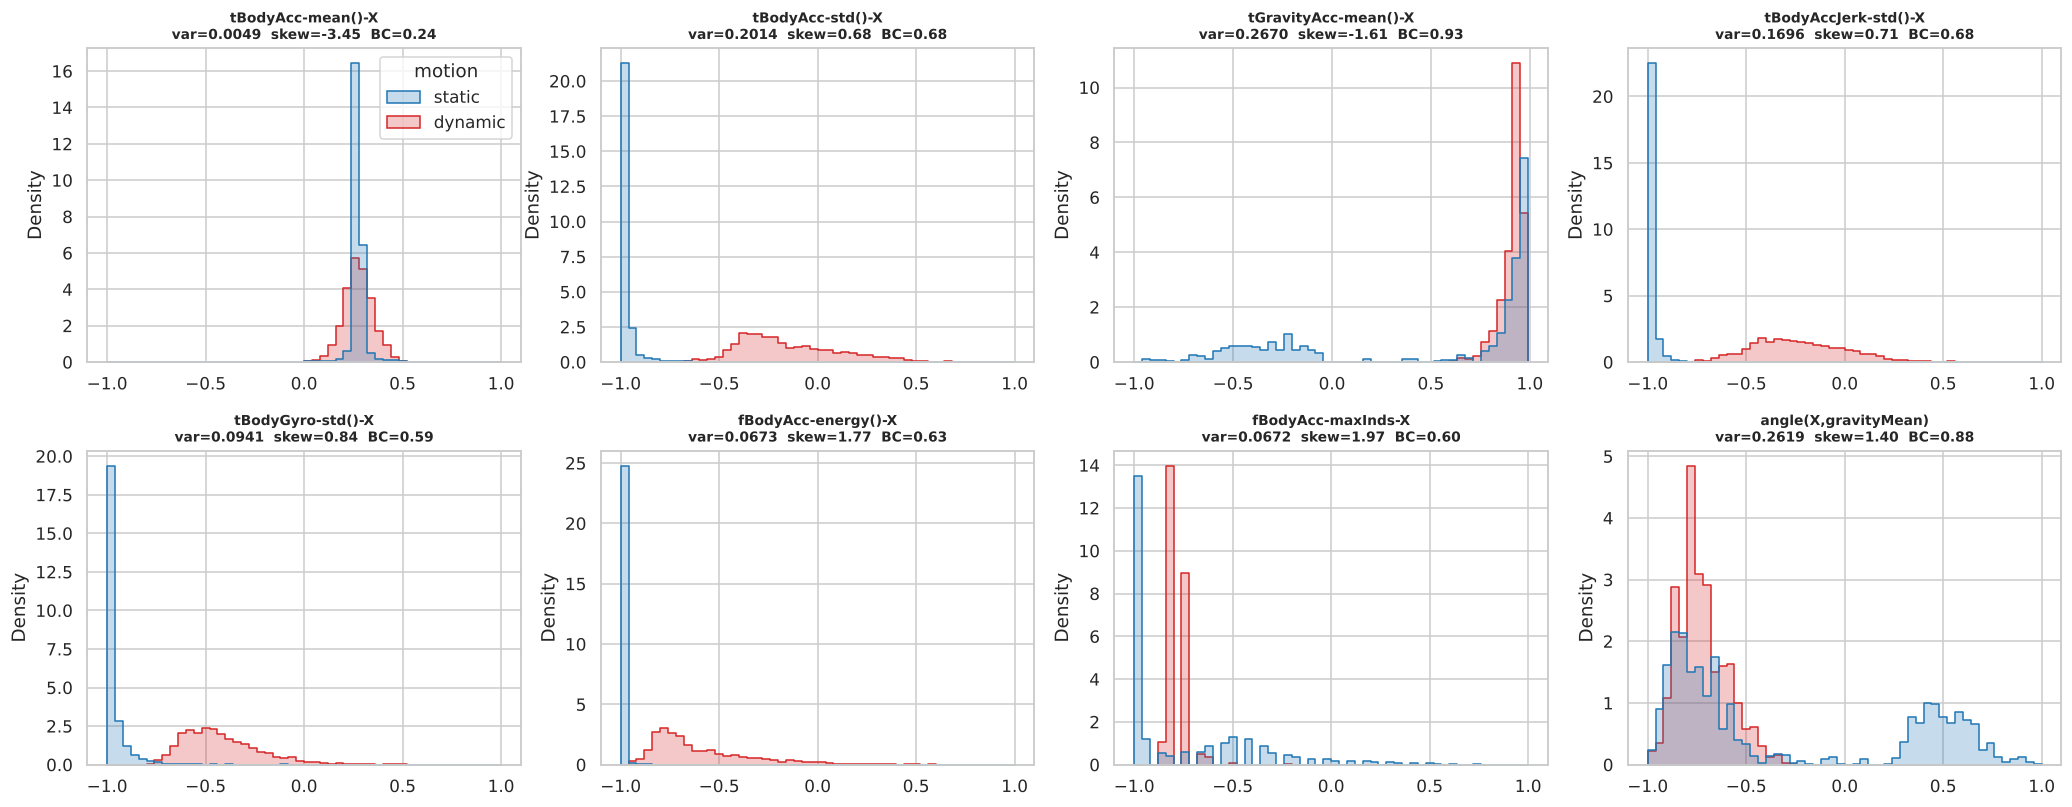

In [23]:
showcase = ["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tGravityAcc-mean()-X", "tBodyAccJerk-std()-X",
            "tBodyGyro-std()-X", "fBodyAcc-energy()-X", "fBodyAcc-maxInds-X", "angle(X,gravityMean)"]
fig, axes = plt.subplots(2, 4, figsize=(19, 7.5))
for ax, f in zip(axes.flat, showcase):
    sns.histplot(x=X_train[f], hue=motion_train, bins=50, stat="density", common_norm=False,
                 element="step", palette=MOTION_COLORS, ax=ax, legend=(f == showcase[0]))
    ax.set_title(f"{f}\nvar={shape.loc[f, 'variance']:.4f}  skew={shape.loc[f, 'skewness']:.2f}  "
                 f"BC={shape.loc[f, 'bimodality coef']:.2f}", fontsize=9)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Distributions are skewed and mostly bimodal**
* **Skew:** 277 of 561 features have |skew| > 1, and almost all of them (264) are skewed to the right. This is concentrated in the frequency domain (69 % of frequency features, against 28 % of time-domain features). `bandsEnergy` features are the most extreme, with median skew 3.3 and excess kurtosis 19; `energy` (2.2) and `maxInds` (2.0) follow.
* **Bimodality:** 356 features have a bimodality coefficient above 0.555. The panels above show why: most intensity-type features (`std`, `energy`, jerk, gyro) have a spike near −1 from static windows and a broad hump from dynamic windows. Orientation features such as `tGravityAcc-mean()-X` and `angle(X,gravityMean)` split along a different line, separating **laying** from upright postures.
* **Implication:** the features are mixtures rather than Gaussian. Models that assume within-class Gaussian inputs (LDA, Gaussian naive Bayes) may benefit from a power transform; tree ensembles, SVMs and k-NN do not need one.

###### 3.3 Variance
The authors min–max scaled every feature into [−1, 1], so features share a **range** but not a **spread**. Variance is what decides how much each feature counts in distance-based and variance-based methods (k-NN, SVM with RBF kernel, k-means, PCA) if the data is used as delivered.

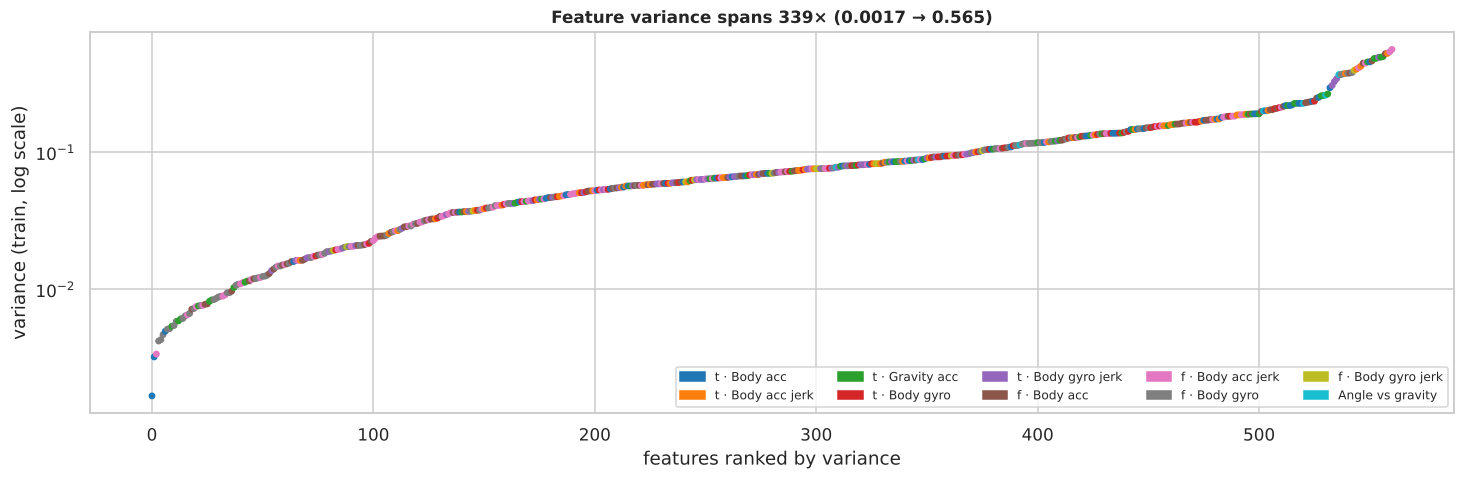

,lowest variance,variance,group,statistic,highest variance,variance,group,statistic
0,tBodyAcc-mean()-Y,0.0017,t · Body acc,mean,fBodyAccJerk-entropy()-X,0.5651,f · Body acc jerk,entropy
1,tBodyAcc-mean()-Z,0.0032,t · Body acc,mean,fBodyAccJerk-entropy()-Y,0.5425,f · Body acc jerk,entropy
2,"fBodyAccJerk-bandsEnergy()-57,64-X",0.0034,f · Body acc jerk,bandsEnergy,tBodyAccJerkMag-entropy(),0.5289,t · Body acc jerk,entropy
3,"fBodyGyro-bandsEnergy()-33,40-Y",0.0042,f · Body gyro,bandsEnergy,fBodyAcc-entropy()-X,0.5257,f · Body acc,entropy
4,"fBodyGyro-bandsEnergy()-33,40-Z",0.0043,f · Body gyro,bandsEnergy,"tGravityAcc-correlation()-X,Z",0.5009,t · Gravity acc,correlation
5,"fBodyGyro-bandsEnergy()-33,48-Z",0.0047,f · Body gyro,bandsEnergy,"tGravityAcc-correlation()-Y,Z",0.4958,t · Gravity acc,correlation
6,tBodyAcc-mean()-X,0.0049,t · Body acc,mean,tBodyGyroJerkMag-entropy(),0.4952,t · Body gyro jerk,entropy
7,"fBodyGyro-bandsEnergy()-33,48-Y",0.0051,f · Body gyro,bandsEnergy,tGravityAcc-energy()-X,0.4871,t · Gravity acc,energy


statistic,bandsEnergy,energy,arCoeff,maxInds,min,meanFreq,max,iqr,skewness,kurtosis,mean,correlation,std,mad,sma,angle,entropy
median variance by statistic,0.0209,0.0481,0.0591,0.0607,0.0632,0.0714,0.0959,0.1057,0.108,0.1161,0.1206,0.1319,0.1379,0.1468,0.1663,0.201,0.3781


In [24]:
var_sorted = shape["variance"].sort_values()
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.scatter(np.arange(len(var_sorted)), var_sorted.values, s=12,
           c=[GROUP_COLORS[g] for g in group_of[var_sorted.index]])
ax.set_yscale("log")
ax.set(xlabel="features ranked by variance", ylabel="variance (train, log scale)",
       title=f"Feature variance spans {var_sorted.iloc[-1] / var_sorted.iloc[0]:.0f}× "
             f"({var_sorted.iloc[0]:.4f} → {var_sorted.iloc[-1]:.3f})")
ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_ORDER], ncol=5, fontsize=8, loc="lower right")
plt.show()

low_high = pd.concat([shape.nsmallest(8, "variance")[["variance", "group", "statistic"]].reset_index(names="lowest variance"),
                      shape.nlargest(8, "variance")[["variance", "group", "statistic"]].reset_index(names="highest variance")],
                     axis=1)
display(low_high)
shape.groupby("statistic")["variance"].median().sort_values().round(4).to_frame("median variance by statistic").T

**Variance differs by a factor of 339 even though the range is fixed**
* The **lowest-variance** features are `tBodyAcc-mean()` X/Y/Z (σ ≈ 0.04–0.07) and the highest-frequency `bandsEnergy` bins (57–64 and 33–48). Both are close to constant by construction. Body acceleration is gravity-filtered, so its window mean is ≈ 0, and the energy above about 12 Hz (FFT bins 33–64) is tiny for human movement.
* The **highest-variance** features are `entropy` features plus the gravity `correlation`/`energy` features (σ ≈ 0.7–0.75), all of which flip between static and dynamic levels.
* Ordered by statistic, median variance rises from `bandsEnergy` (0.021) to `entropy` (0.378). On the raw scale, a Euclidean distance is therefore weighted toward entropy-type features and away from band energies. Section 6 quantifies this.

##### 4. Correlation and redundancy
Pearson correlations between all 561 features on the training split (157,080 distinct pairs).

In [25]:
corr = X_train.corr()
abs_corr = corr.abs()
A = abs_corr.to_numpy().copy()
np.fill_diagonal(A, np.nan)
max_abs_r = pd.Series(np.nanmax(A, axis=1), index=feature_names)
pair_r = abs_corr.to_numpy()[np.triu_indices(len(feature_names), k=1)]

thresholds = [0.8, 0.9, 0.95, 0.99, 0.999]
pd.DataFrame({
    "pairs with |r| ≥ t": [int((pair_r >= t).sum()) for t in thresholds],
    "% of all pairs": [round((pair_r >= t).mean() * 100, 2) for t in thresholds],
    "features with ≥1 such partner": [int((max_abs_r >= t).sum()) for t in thresholds],
}, index=pd.Index(thresholds, name="threshold t"))

,pairs with |r| ≥ t,% of all pairs,features with ≥1 such partner
threshold t,,,
0.800,23058,14.68,456
0.900,8206,5.22,431
0.950,2281,1.45,391
0.990,207,0.13,183
0.999,42,0.03,60


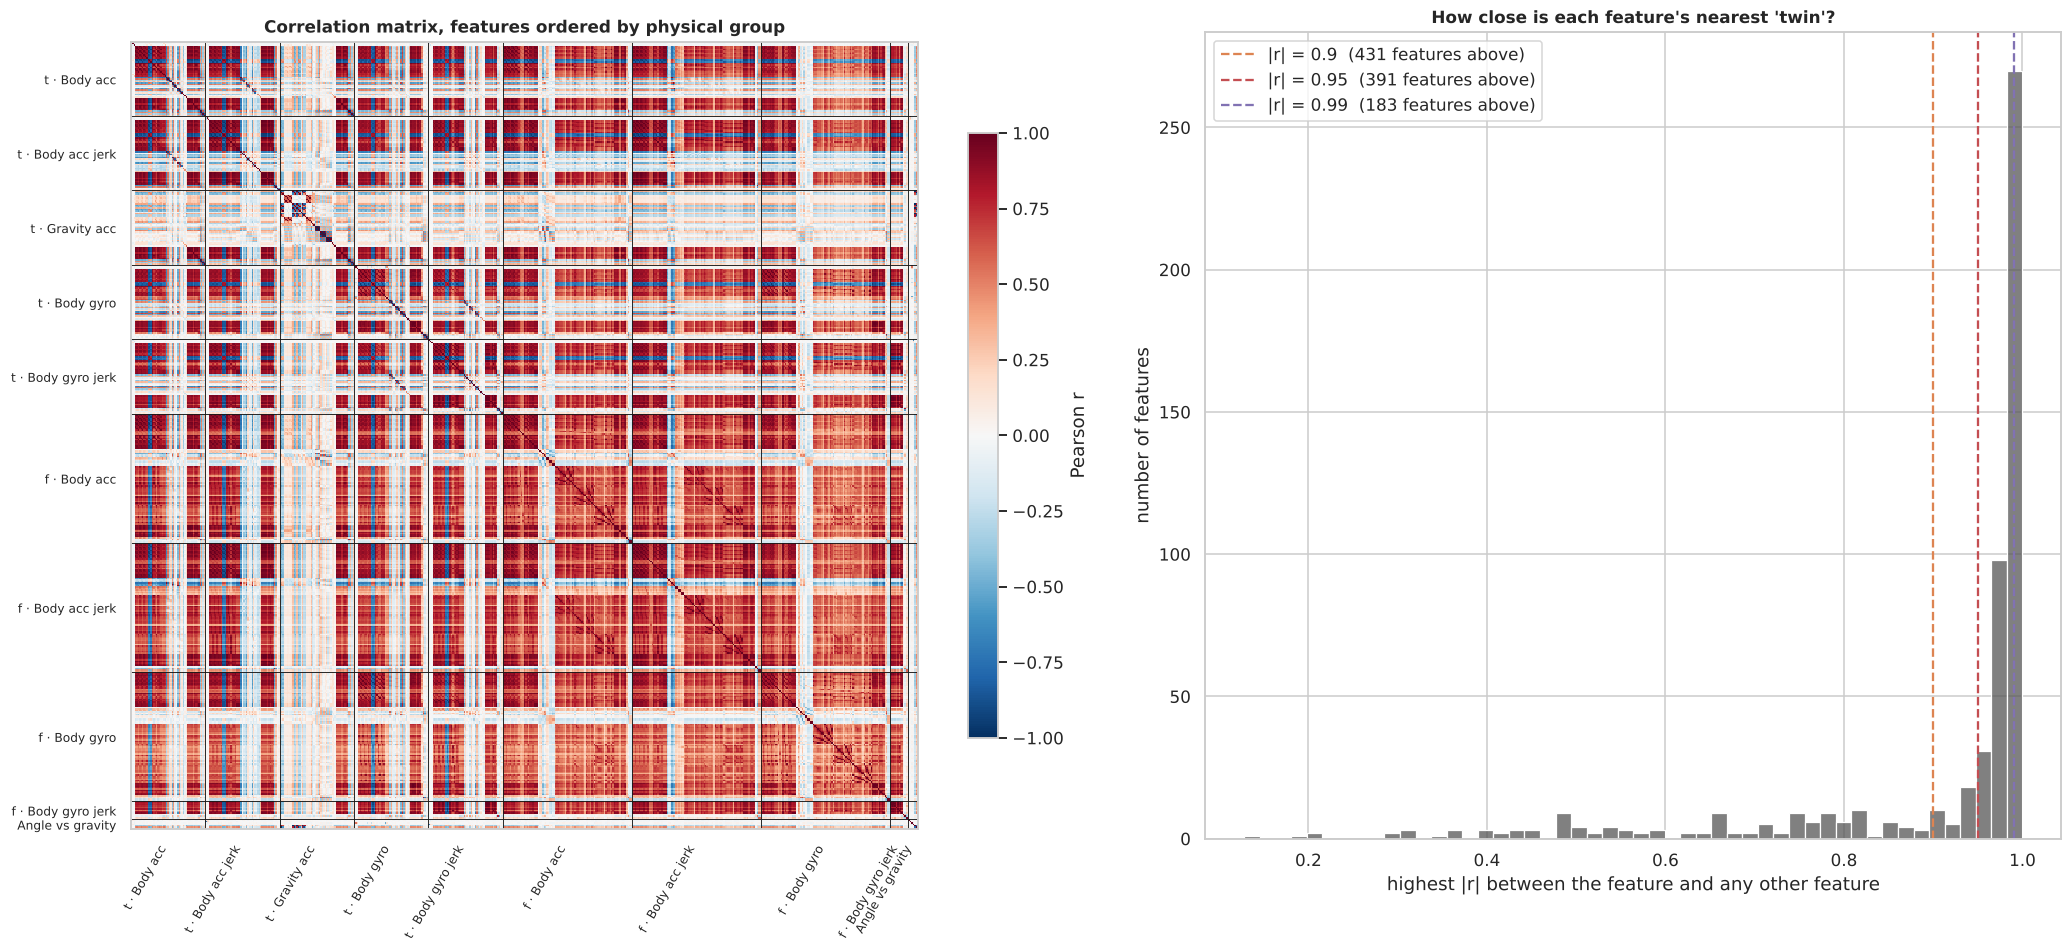

In [26]:
order = meta.sort_values(["group", "col"]).index
C = corr.loc[order, order].to_numpy()
ends = meta["group"].value_counts(sort=False).reindex(GROUP_ORDER).cumsum().to_numpy()
starts = np.r_[0, ends[:-1]]

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
for b in ends[:-1]:
    axes[0].axhline(b - 0.5, color="k", lw=0.6)
    axes[0].axvline(b - 0.5, color="k", lw=0.6)
mids = (starts + ends) / 2
axes[0].set_xticks(mids, GROUP_ORDER, rotation=60, ha="right", fontsize=8)
axes[0].set_yticks(mids, GROUP_ORDER, fontsize=8)
axes[0].grid(False)
axes[0].set_title("Correlation matrix, features ordered by physical group")
fig.colorbar(im, ax=axes[0], shrink=0.75, label="Pearson r")

sns.histplot(max_abs_r, bins=50, ax=axes[1], color="#555")
for t, c in [(0.9, "#dd8452"), (0.95, "#c44e52"), (0.99, "#8172b3")]:
    axes[1].axvline(t, ls="--", color=c, label=f"|r| = {t}  ({(max_abs_r >= t).sum()} features above)")
axes[1].set(xlabel="highest |r| between the feature and any other feature", ylabel="number of features",
            title="How close is each feature's nearest 'twin'?")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

###### 4.1 Where the redundancy sits
Left: mean |r| within and between physical groups. Right: mean |r| between different summary statistics computed on the **same** signal and axis (e.g. `tBodyAcc-std()-X` vs `tBodyAcc-mad()-X`).

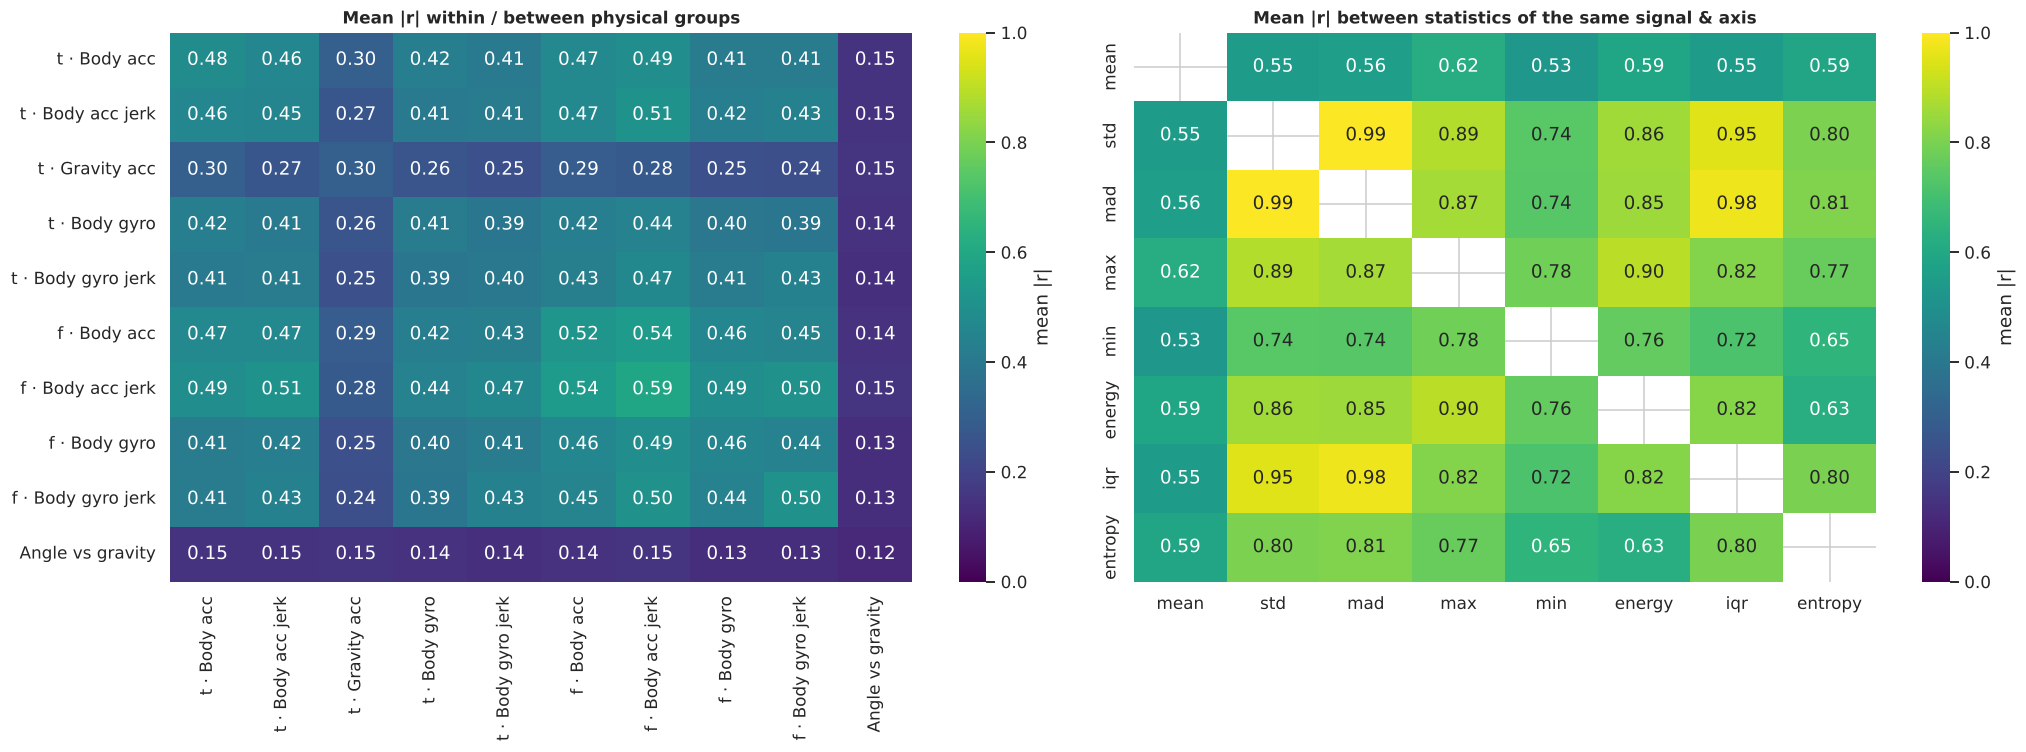

In [27]:
block = pd.DataFrame(index=GROUP_ORDER, columns=GROUP_ORDER, dtype=float)
idx_of = {g: np.where(group_of == g)[0] for g in GROUP_ORDER}
for gi in GROUP_ORDER:
    for gj in GROUP_ORDER:
        block.loc[gi, gj] = np.nanmean(A[np.ix_(idx_of[gi], idx_of[gj])])

STAT_SUBSET = ["mean", "std", "mad", "max", "min", "energy", "iqr", "entropy"]
m = meta[meta["statistic"].isin(STAT_SUBSET)].copy()
m["signal_key"] = m["signal"] + "|" + m["axis"].fillna("")
records = []
for _, idx in m.groupby("signal_key").groups.items():
    idx = list(idx)
    for i, a in enumerate(idx):
        for b in idx[i + 1:]:
            sa, sb = m.at[a, "statistic"], m.at[b, "statistic"]
            records += [(sa, sb, abs_corr.at[a, b]), (sb, sa, abs_corr.at[a, b])]
stat_r = (pd.DataFrame(records, columns=["a", "b", "r"]).pivot_table(index="a", columns="b", values="r", aggfunc="mean")
          .reindex(index=STAT_SUBSET, columns=STAT_SUBSET))

fig, axes = plt.subplots(1, 2, figsize=(19, 7))
sns.heatmap(block, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "mean |r|"})
axes[0].set_title("Mean |r| within / between physical groups")
sns.heatmap(stat_r, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "mean |r|"})
axes[1].set(title="Mean |r| between statistics of the same signal & axis", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

In [28]:
# Strongest pairs once the exact duplicates (r = 1) are set aside
A_dedup = abs_corr.loc[keep_dedup, keep_dedup].to_numpy()
iu = np.triu_indices(len(keep_dedup), k=1)
top = np.argsort(A_dedup[iu])[::-1][:12]
pd.DataFrame({"feature A": [keep_dedup[i] for i in iu[0][top]],
              "feature B": [keep_dedup[j] for j in iu[1][top]],
              "r": [corr.at[keep_dedup[i], keep_dedup[j]] for i, j in zip(iu[0][top], iu[1][top])]})

,feature A,feature B,r
0,tBodyAccJerk-energy()-Z,fBodyAccJerk-energy()-Z,1.0000
1,tBodyAccJerk-energy()-Y,fBodyAccJerk-energy()-Y,1.0000
2,tBodyAccJerk-energy()-X,fBodyAccJerk-energy()-X,1.0000
3,fBodyAcc-energy()-X,"fBodyAcc-bandsEnergy()-1,24-X",0.9999
4,fBodyGyro-energy()-X,"fBodyGyro-bandsEnergy()-1,24-X",0.9998
5,fBodyAcc-energy()-Y,"fBodyAcc-bandsEnergy()-1,24-Y",0.9997
6,tBodyAccJerk-sma(),tBodyAccJerkMag-mean(),0.9997
7,tBodyAcc-energy()-X,fBodyAcc-energy()-X,0.9996
8,fBodyGyro-energy()-Z,"fBodyGyro-bandsEnergy()-1,24-Z",0.9995
9,tBodyAcc-energy()-X,"fBodyAcc-bandsEnergy()-1,24-X",0.9995


###### 4.2 How many features are really distinct?
Two complementary counts at each correlation threshold *t*:
* **Greedy filter** — walk the features in file order and keep one only if its |r| with every feature already kept is ≤ *t*. This is the simple, reproducible filter recommended for preprocessing.
* **Complete-linkage clusters** — cluster on distance 1 − |r| and cut so that every pair inside a cluster has |r| ≥ *t*. The number of clusters is the number of "information units" at that threshold.

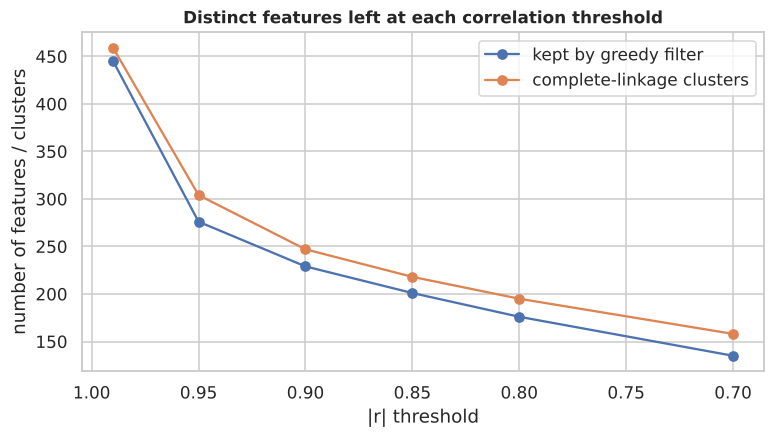

,kept by greedy filter,complete-linkage clusters,% of 561 kept (greedy)
|r| threshold,,,
0.99,445,459,79.3
0.95,276,304,49.2
0.90,229,247,40.8
0.85,201,218,35.8
0.80,176,195,31.4
0.70,135,158,24.1


In [29]:
def correlation_filter(abs_corr: pd.DataFrame, threshold: float) -> list:
    """Keep a feature only if its |r| with every already-kept feature is <= threshold (file order)."""
    M = abs_corr.to_numpy()
    kept = []
    for j in range(M.shape[0]):
        if not kept or M[j, kept].max() <= threshold:
            kept.append(j)
    return list(abs_corr.columns[kept])


D = 1 - abs_corr.to_numpy()
D = np.clip((D + D.T) / 2, 0, None)
np.fill_diagonal(D, 0)
Z_link = linkage(squareform(D, checks=False), method="complete")

grid = [0.99, 0.95, 0.9, 0.85, 0.8, 0.7]
filtered = {t: correlation_filter(abs_corr, t) for t in grid}
redundancy = pd.DataFrame({
    "kept by greedy filter": [len(filtered[t]) for t in grid],
    "complete-linkage clusters": [len(np.unique(fcluster(Z_link, t=1 - t, criterion="distance"))) for t in grid],
}, index=pd.Index(grid, name="|r| threshold"))
redundancy["% of 561 kept (greedy)"] = (redundancy["kept by greedy filter"] / 561 * 100).round(1)
kept_095 = filtered[0.95]
assert not set(kept_095) & set(exact_drop), "exact duplicates should never survive the filter"

fig, ax = plt.subplots(figsize=(8, 4))
redundancy[["kept by greedy filter", "complete-linkage clusters"]].plot(marker="o", ax=ax)
ax.invert_xaxis()
ax.set(ylabel="number of features / clusters", title="Distinct features left at each correlation threshold")
plt.show()
redundancy

**Redundancy is the defining property of this feature set**
* **2,281 pairs** have |r| ≥ 0.95, and **391 of 561 features (70 %)** have at least one near-twin at that level (183 at ≥ 0.99).
* A greedy filter at |r| > 0.95 keeps **276 features (49 %)**. Complete-linkage clustering gives a similar picture (304 clusters in which every pair has |r| ≥ 0.95). Even at 0.8, 176 features remain distinct, so the set compresses heavily but not down to a handful of features.
* **Which statistics overlap:** `std`, `mad` and `iqr` of the same signal and axis correlate at 0.95–0.99. They are three estimates of the same spread. `max` and `energy` follow at 0.86–0.90. `mean` is the most independent statistic (≈ 0.55).
* **Strongest non-identical pairs** have a physical explanation:
  * Time-domain and frequency-domain `energy` of the same signal correlate at r ≈ 1.000. This is **Parseval's theorem**: a signal's energy is the same in both domains.
  * `energy()` and `bandsEnergy()-1,24` agree at r ≈ 0.9999, because almost all movement energy sits in the lowest frequency bins.
  * `tBodyAccJerk-sma()` and `tBodyAccJerkMag-mean()` (r ≈ 0.9997) both measure average jerk magnitude.
* **Between groups:** all body-motion groups (acc, gyro, jerk; time and frequency) inter-correlate at 0.4–0.6 because they all track *how much the person is moving*. Gravity (≈ 0.25–0.30) and angle (≈ 0.15) features are the least correlated with the rest; they carry **orientation/posture** information that the motion groups do not.

##### 5. Features grouped by physical meaning
###### 5.1 Composition
The six physical categories in the brief overlap — one feature can be accelerometer + jerk + frequency domain at once — so the first table counts membership, not a partition. The ten groups used elsewhere in the notebook *are* a partition.

In [30]:
categories = {
    "Acceleration (accelerometer, body + gravity)": meta["sensor"].eq("accelerometer") & ~meta["domain"].eq("Angle"),
    "Gyroscope (angular velocity)": meta["sensor"].eq("gyroscope"),
    "Gravity component": meta["component"].eq("gravity"),
    "Jerk (time derivative)": meta["jerk"] & ~meta["domain"].eq("Angle"),
    "Time domain": meta["domain"].eq("Time"),
    "Frequency domain": meta["domain"].eq("Frequency"),
    "Magnitude (Euclidean norm of X, Y, Z)": meta["magnitude"],
    "Angle between vectors": meta["domain"].eq("Angle"),
}
cat_table = pd.DataFrame({
    "features": {k: int(v.sum()) for k, v in categories.items()},
    "exact duplicates among them": {k: int(v[exact_drop].sum()) for k, v in categories.items()},
    "kept by |r|>0.95 filter": {k: int(v[kept_095].sum()) for k, v in categories.items()},
})
cat_table["% of 561"] = (cat_table["features"] / 561 * 100).round(1)
cat_table

,features,exact duplicates among them,kept by |r|>0.95 filter,% of 561
"Acceleration (accelerometer, body + gravity)",343,17,160,61.1
Gyroscope (angular velocity),211,4,112,37.6
Gravity component,53,13,20,9.4
Jerk (time derivative),211,4,93,37.6
Time domain,265,17,149,47.2
Frequency domain,289,4,123,51.5
"Magnitude (Euclidean norm of X, Y, Z)",117,21,46,20.9
Angle between vectors,7,0,4,1.2


In [31]:
pd.crosstab(meta["group"], meta["statistic"], margins=True, margins_name="total")

statistic,angle,arCoeff,bandsEnergy,correlation,energy,entropy,iqr,kurtosis,mad,max,maxInds,mean,meanFreq,min,skewness,sma,std,total
group,,,,,,,,,,,,,,,,,,
t · Body acc,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Body acc jerk,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Gravity acc,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Body gyro,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Body gyro jerk,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
f · Body acc,0,0,42,0,4,4,4,4,4,4,4,4,4,4,4,2,4,92
f · Body acc jerk,0,0,42,0,4,4,4,4,4,4,4,4,4,4,4,2,4,92
f · Body gyro,0,0,42,0,4,4,4,4,4,4,4,4,4,4,4,2,4,92
f · Body gyro jerk,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,13


###### 5.2 Group profiles
One row per physical group: size, spread, shape, redundancy and how much survives de-duplication and the |r| > 0.95 filter.

In [32]:
g = meta["group"]
profile = pd.DataFrame({
    "features": g.value_counts(sort=False),
    "exact duplicates": pd.Series(meta.index.isin(exact_drop), index=meta.index).groupby(g, observed=True).sum(),
    "median variance": shape["variance"].groupby(g, observed=True).median(),
    "median |skew|": shape["skewness"].abs().groupby(g, observed=True).median(),
    "mean |r| within group": pd.Series(np.diag(block.to_numpy()), index=GROUP_ORDER),
    "% with a |r|>0.95 twin": (max_abs_r > 0.95).groupby(g, observed=True).mean() * 100,
    "kept by |r|>0.95 filter": pd.Series(meta.index.isin(kept_095), index=meta.index).groupby(g, observed=True).sum(),
}).reindex(GROUP_ORDER)
profile["% kept"] = profile["kept by |r|>0.95 filter"] / profile["features"] * 100
profile.loc["All features"] = [561, len(exact_drop), shape["variance"].median(), shape["skewness"].abs().median(),
                               np.nanmean(A), (max_abs_r > 0.95).mean() * 100, len(kept_095), len(kept_095) / 561 * 100]
profile.round(3)

,features,exact duplicates,median variance,median |skew|,mean |r| within group,% with a |r|>0.95 twin,kept by |r|>0.95 filter,% kept
t · Body acc,53.0,1.0,0.094,0.431,0.482,62.264,34.0,64.151
t · Body acc jerk,53.0,1.0,0.076,0.613,0.455,62.264,30.0,56.604
t · Gravity acc,53.0,13.0,0.087,0.676,0.299,83.019,20.0,37.736
t · Body gyro,53.0,1.0,0.093,0.533,0.412,45.283,39.0,73.585
t · Body gyro jerk,53.0,1.0,0.066,0.917,0.401,58.491,26.0,49.057
f · Body acc,92.0,1.0,0.067,1.811,0.520,81.522,44.0,47.826
f · Body acc jerk,92.0,1.0,0.050,1.903,0.591,72.826,32.0,34.783
f · Body gyro,92.0,1.0,0.040,2.923,0.456,77.174,42.0,45.652
f · Body gyro jerk,13.0,1.0,0.076,1.609,0.503,76.923,5.0,38.462
Angle vs gravity,7.0,0.0,0.201,0.082,0.116,42.857,4.0,57.143


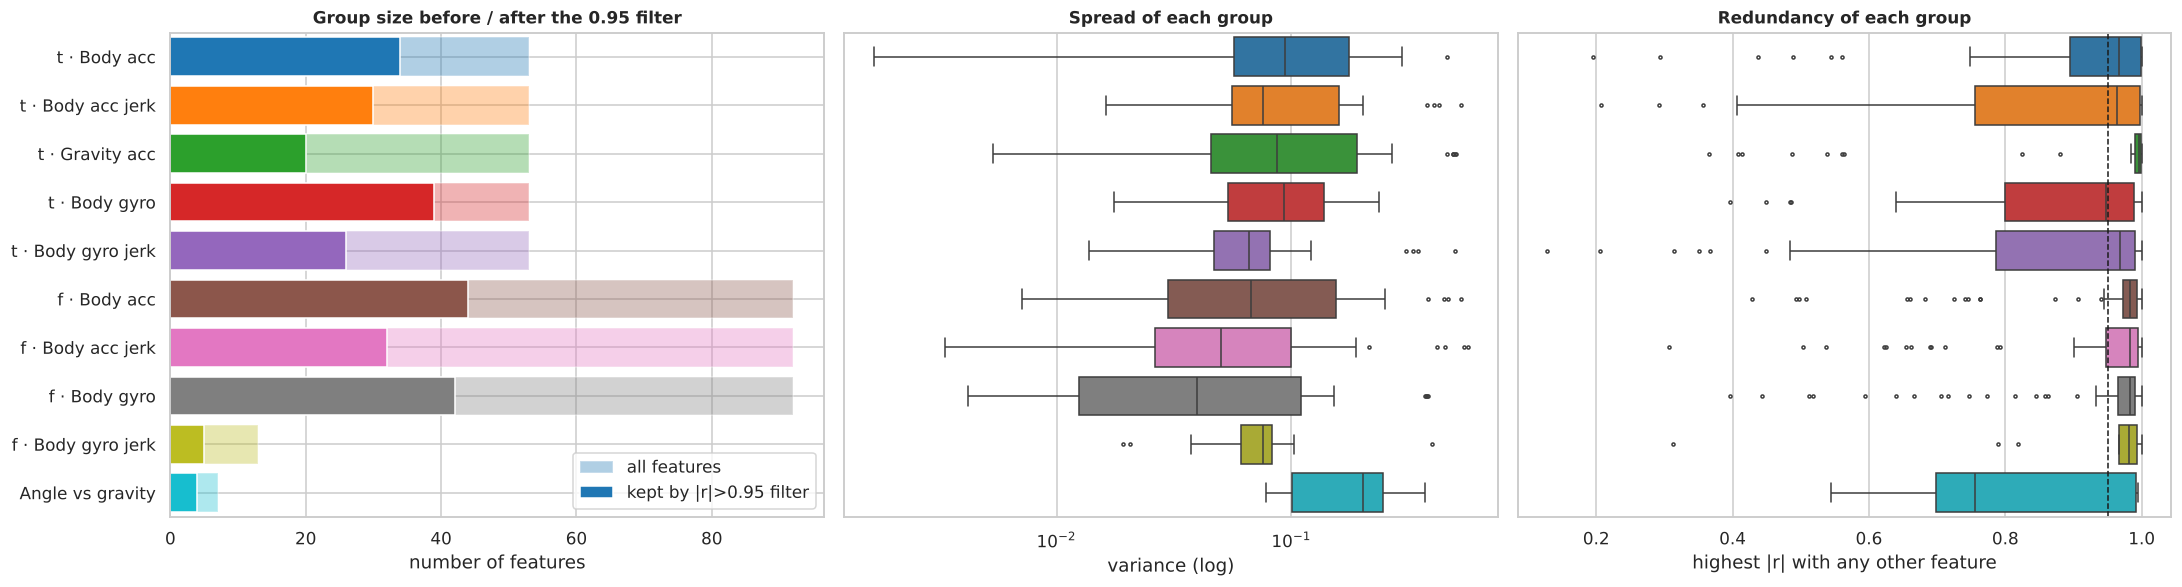

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
y_pos = np.arange(len(GROUP_ORDER))
cols = [GROUP_COLORS[gname] for gname in GROUP_ORDER]

axes[0].barh(y_pos, profile.loc[GROUP_ORDER, "features"], color=cols, alpha=0.35, label="all features")
axes[0].barh(y_pos, profile.loc[GROUP_ORDER, "kept by |r|>0.95 filter"], color=cols, label="kept by |r|>0.95 filter")
axes[0].set_yticks(y_pos, GROUP_ORDER)
axes[0].invert_yaxis()
axes[0].set(xlabel="number of features", title="Group size before / after the 0.95 filter")
axes[0].legend(loc="lower right")

plot_df = shape.assign(group=group_of, max_abs_r=max_abs_r)
sns.boxplot(data=plot_df, y="group", x="variance", order=GROUP_ORDER, palette=GROUP_COLORS, ax=axes[1], fliersize=2)
axes[1].set(xscale="log", xlabel="variance (log)", ylabel="", title="Spread of each group")

sns.boxplot(data=plot_df, y="group", x="max_abs_r", order=GROUP_ORDER, palette=GROUP_COLORS, ax=axes[2], fliersize=2)
axes[2].axvline(0.95, ls="--", color="k", lw=1)
axes[2].set(xlabel="highest |r| with any other feature", ylabel="", title="Redundancy of each group")
plt.tight_layout()
plt.show()

**What the physical grouping shows**
* **Composition:** 61 % of features come from the accelerometer and 38 % from the gyroscope. Time (265) and frequency (289) are roughly balanced, while the angle features are only 7. Only three body signals have full frequency-domain versions (92 features each), and gyro jerk has only a magnitude version (13). The frequency domain therefore leans on body acceleration, acceleration jerk and gyroscope.
* **Gravity is the most redundant group:** 13 of its 53 features are exact copies (the `tGravityAccMag` bug), 83 % have a near-twin, and only 20 (38 %) survive the 0.95 filter. Gravity is a slowly varying 3-D vector, so its many summary statistics say nearly the same thing.
* **Frequency body groups come next:** 73–82 % have a near-twin and 35–48 % are kept. Most of the overlap is between the 42 `bandsEnergy` features and `energy` in each group.
* **Time-domain gyroscope is the least redundant motion group** (74 % kept). The angle features have low within-group correlation (0.12) and high variance, but 4 of the 7 are near-useless (§6.2).
* **Skew follows domain:** frequency groups have median |skew| of 1.6–2.9, against 0.4–0.9 for time groups.

##### 6. Effect of standardisation and duplicate-feature removal
`StandardScaler` is fitted on the training split only and then applied to both splits. Four configurations are compared:

| Configuration | Features | What it does |
|---|---|---|
| Raw | 561 | data as delivered (min–max scaled to [−1, 1] by the authors) |
| Standardised | 561 | every feature centred to mean 0, scaled to standard deviation 1 |
| Standardised + exact duplicates removed | 540 | as above, minus the 21 value-identical copies |
| Standardised + \|r\| > 0.95 filter | see §4.2 | as above, minus near-duplicates |

In [34]:
scaler = StandardScaler().fit(X_train)
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=feature_names, index=X_train.index)
Xs_test = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)

print("Correlation unchanged by standardisation:",
      bool(np.allclose(Xs_train.corr().to_numpy(), corr.to_numpy(), atol=1e-10)))
print("Shape and order unchanged (skewness identical):",
      bool(np.allclose(Xs_train.skew().to_numpy(), shape["skewness"].to_numpy(), atol=1e-8)))

Correlation unchanged by standardisation: True
Shape and order unchanged (skewness identical): True


###### 6.1 Feature distributions before and after
Three of the lowest-variance, three median-variance and three of the highest-variance features. Standardisation is a linear rescaling, so each distribution keeps its shape but every feature now occupies the same spread.

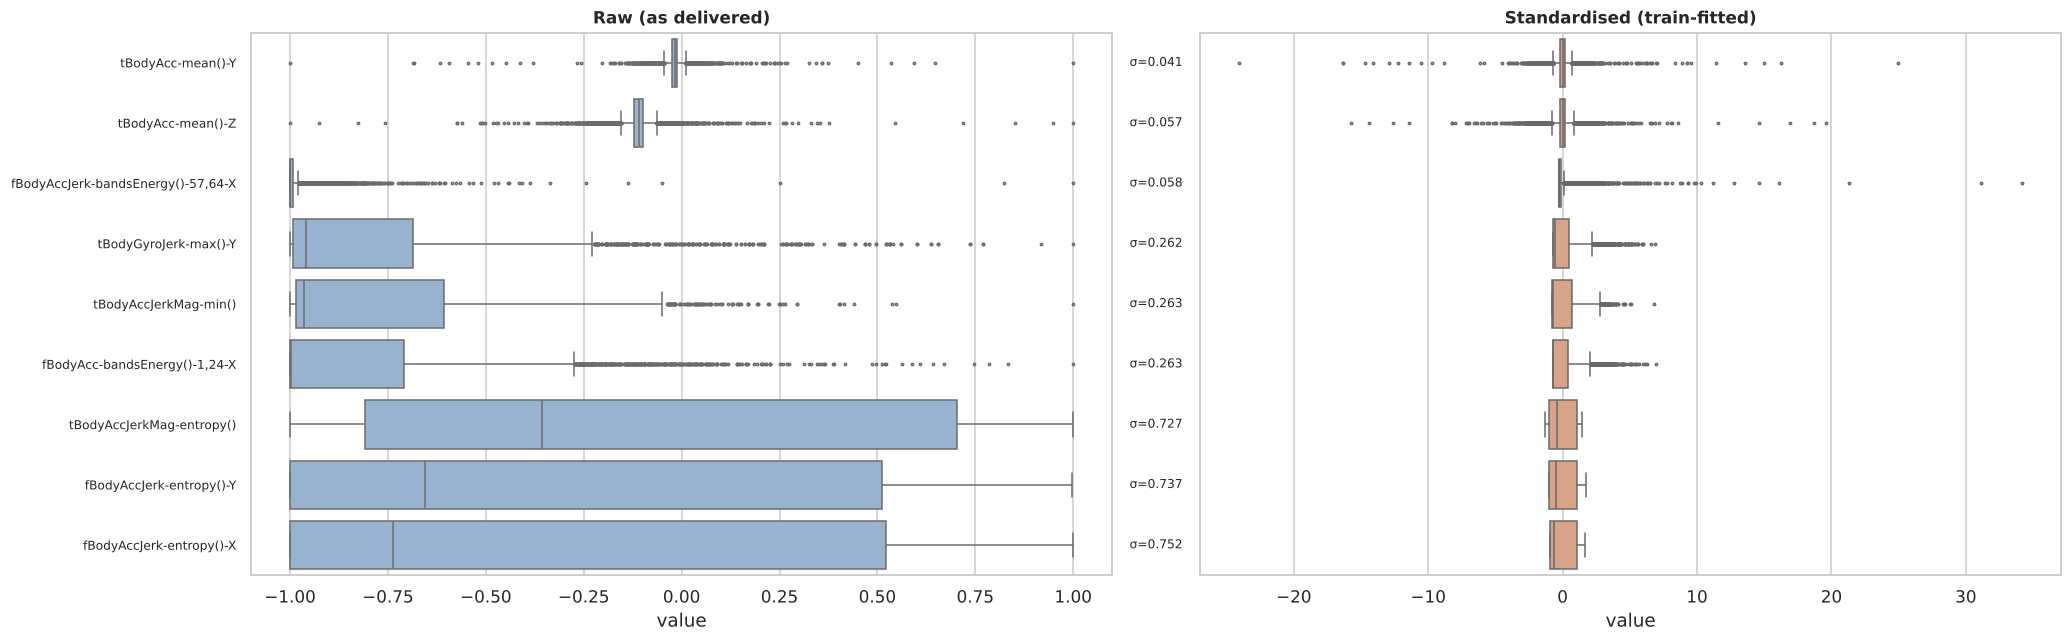

In [35]:
v = shape.loc[keep_dedup, "variance"].sort_values()      # skip value-identical copies
picked = list(v.index[:3]) + list(v.index[len(v) // 2 - 1: len(v) // 2 + 2]) + list(v.index[-3:])
long = pd.concat([
    X_train[picked].melt(var_name="feature").assign(version="Raw (as delivered)"),
    Xs_train[picked].melt(var_name="feature").assign(version="Standardised (train-fitted)"),
])
fig, axes = plt.subplots(1, 2, figsize=(19, 6), sharey=True)
for ax, ver in zip(axes, ["Raw (as delivered)", "Standardised (train-fitted)"]):
    sns.boxplot(data=long[long["version"] == ver], y="feature", x="value", order=picked, ax=ax, fliersize=1.5,
                color="#8fb3d9" if ver.startswith("Raw") else "#e5a07a")
    ax.set(title=ver, ylabel="", xlabel="value")
for i, f in enumerate(picked):
    axes[0].text(1.02, i, f"σ={shape.loc[f, 'std']:.3f}", va="center", fontsize=8, transform=axes[0].get_yaxis_transform())
axes[0].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

###### 6.2 Which features standardisation amplifies — and are they informative?
Standardising multiplies each feature by 1/σ, so low-variance features are scaled up the most (up to ~25× here). That is only harmless if those features carry signal. η² (the share of a feature's variance explained by the activity label, from a one-way ANOVA on the training split) is used as a quick check of signal content.

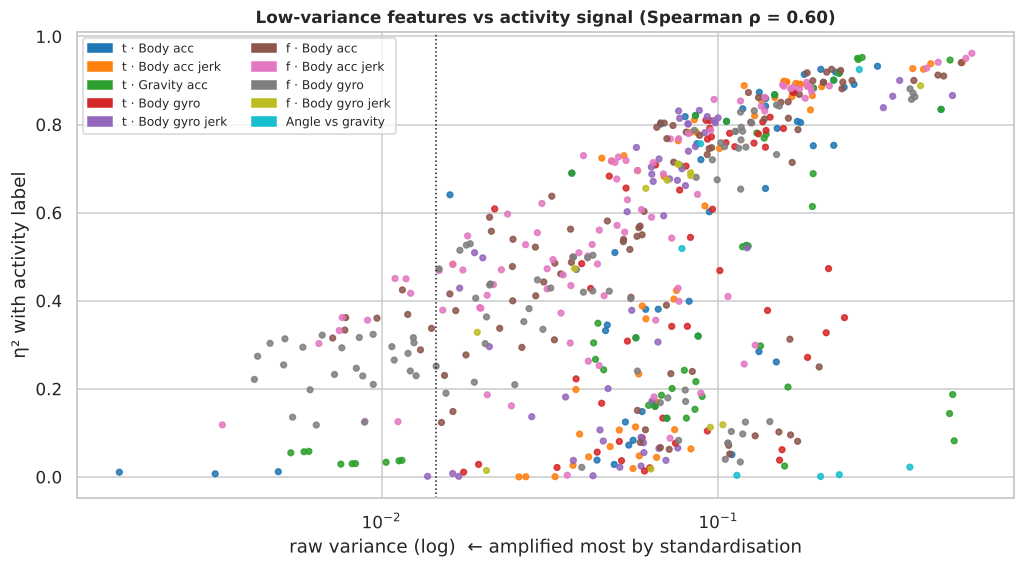

45 features have η² < 0.05 (activity explains <5% of their variance): {'arCoeff': 14, 'mean': 12, 'angle': 4, 'maxInds': 3, 'std': 2, 'mad': 2, 'iqr': 2, 'correlation': 2, 'entropy': 1, 'skewness': 1, 'kurtosis': 1, 'meanFreq': 1}


In [36]:
def eta_squared(X: pd.DataFrame, labels: pd.Series) -> pd.Series:
    Xv = X.to_numpy()
    grand = Xv.mean(axis=0)
    ss_total = ((Xv - grand) ** 2).sum(axis=0)
    ss_between = np.zeros(Xv.shape[1])
    for k in pd.unique(labels):
        mask = (labels == k).to_numpy()
        ss_between += mask.sum() * (Xv[mask].mean(axis=0) - grand) ** 2
    return pd.Series(ss_between / ss_total, index=X.columns)


eta2 = eta_squared(X_train, y_train)
amplification = 1 / shape["std"]
rho, _ = spearmanr(shape["variance"], eta2)

low_var = shape["variance"] <= shape["variance"].quantile(0.10)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(shape["variance"], eta2, s=14, c=[GROUP_COLORS[gname] for gname in group_of], alpha=0.85)
ax.set_xscale("log")
ax.axvline(shape["variance"].quantile(0.10), ls=":", color="k", lw=1)
ax.set(xlabel="raw variance (log)  ← amplified most by standardisation", ylabel="η² with activity label",
       title=f"Low-variance features vs activity signal (Spearman ρ = {rho:.2f})")
ax.legend(handles=[Patch(color=GROUP_COLORS[gname], label=gname) for gname in GROUP_ORDER], fontsize=8,
          ncol=2, loc="upper left")
plt.show()

pd.DataFrame({
    "median η²": [eta2[low_var].median(), eta2[~low_var].median()],
    "% with η² < 0.2": [(eta2[low_var] < 0.2).mean() * 100, (eta2[~low_var] < 0.2).mean() * 100],
    "median amplification (1/σ)": [amplification[low_var].median(), amplification[~low_var].median()],
}, index=["lowest-variance 10% of features", "other 90%"]).round(3)

near_zero = eta2[eta2 < 0.05].index
print(f"{len(near_zero)} features have η² < 0.05 (activity explains <5% of their variance):",
      meta.loc[near_zero, "statistic"].value_counts().to_dict())

In [37]:
print("Most amplified features:")
pd.DataFrame({"raw σ": shape["std"], "amplification 1/σ": amplification, "η² activity": eta2,
              "group": group_of}).nlargest(10, "amplification 1/σ").round(3)

Most amplified features:


,raw σ,amplification 1/σ,η² activity,group
tBodyAcc-mean()-Y,0.041,24.503,0.011,t · Body acc
tBodyAcc-mean()-Z,0.057,17.657,0.007,t · Body acc
"fBodyAccJerk-bandsEnergy()-57,64-X",0.058,17.233,0.118,f · Body acc jerk
"fBodyGyro-bandsEnergy()-33,40-Y",0.065,15.444,0.221,f · Body gyro
"fBodyGyro-bandsEnergy()-33,40-Z",0.065,15.274,0.274,f · Body gyro
"fBodyGyro-bandsEnergy()-33,48-Z",0.068,14.639,0.303,f · Body gyro
tBodyAcc-mean()-X,0.070,14.233,0.012,t · Body acc
"fBodyGyro-bandsEnergy()-33,48-Y",0.072,13.977,0.254,f · Body gyro
"fBodyGyro-bandsEnergy()-25,48-Z",0.072,13.914,0.314,f · Body gyro
tGravityAcc-iqr()-X,0.073,13.637,0.055,t · Gravity acc


**Standardisation amplifies near-noise features**
* Raw variance and activity signal are positively related (Spearman ρ = 0.60). The lowest-variance 10 % of features have median η² = 0.25, compared with 0.56 for the rest, and they are amplified about 11× (median), against 3.6× for the rest.
* The most amplified features are the worst offenders. `tBodyAcc-mean()` X/Y/Z are scaled up 14–25× and have **η² ≈ 0.01**: body acceleration is gravity-removed, so its window mean is near zero for every activity. The same holds for the `mean()` of acceleration jerk, gyroscope and gyroscope jerk (η² ≤ 0.03).
* Forty-five features have η² < 0.05, mostly `arCoeff` (14), body-signal `mean()` (12) and four of the angle features. The four angles are those between gravity and the mean body, jerk or gyro vector, which are angles to a near-zero vector. After standardisation these weigh as much as the most informative features, and their heavy tails become values as large as ±25 σ (§6.1).
* **Caveat:** η² is a univariate, label-based screen. It flags *candidates* for removal; whether removing them helps should be confirmed inside cross-validation.

###### 6.3 Relative weighting of the physical groups
For Euclidean-distance and variance-based methods, the expected squared distance between two random windows is 2 × Σ variances. So a group's **share of the total variance is its share of the distance** — i.e. its effective weight.
* **Raw:** weight ∝ the group's summed variance.
* **Standardised:** every feature has variance 1, so weight ∝ the number of features in the group.
* **Duplicate removal / correlation filter:** changes the feature counts, and therefore the weights.

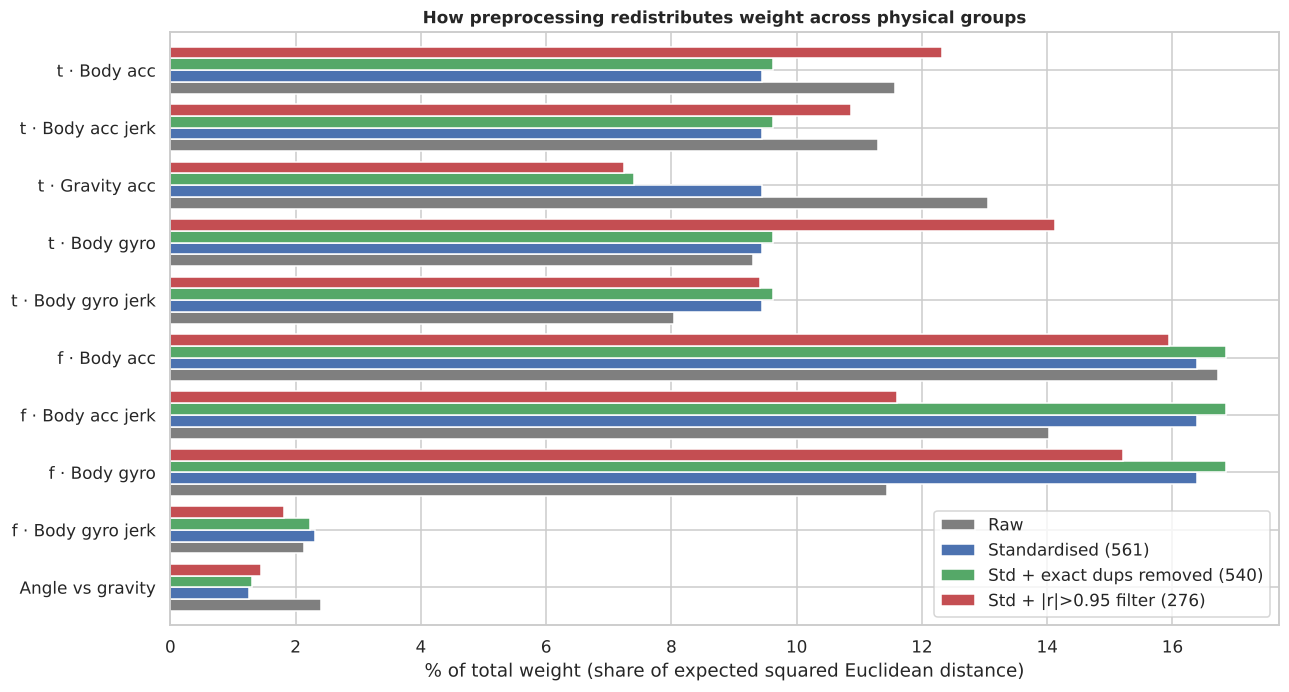

,Raw,Standardised (561),Std + exact dups removed (540),Std + |r|>0.95 filter (276)
group,,,,
t · Body acc,11.6,9.4,9.6,12.3
t · Body acc jerk,11.3,9.4,9.6,10.9
t · Gravity acc,13.1,9.4,7.4,7.2
t · Body gyro,9.3,9.4,9.6,14.1
t · Body gyro jerk,8.0,9.4,9.6,9.4
f · Body acc,16.7,16.4,16.9,15.9
f · Body acc jerk,14.0,16.4,16.9,11.6
f · Body gyro,11.4,16.4,16.9,15.2
f · Body gyro jerk,2.1,2.3,2.2,1.8


In [38]:
def weight_share(weights: pd.Series, by: pd.Series, order=None) -> pd.Series:
    out = weights.groupby(by.loc[weights.index].astype(str)).sum() / weights.sum() * 100
    return out.reindex(order) if order is not None else out


ones = lambda cols: pd.Series(1.0, index=cols)
schemes = {
    "Raw": shape["variance"],
    "Standardised (561)": ones(feature_names),
    f"Std + exact dups removed ({len(keep_dedup)})": ones(keep_dedup),
    f"Std + |r|>0.95 filter ({len(kept_095)})": ones(kept_095),
}
shares = pd.DataFrame({k: weight_share(w, meta["group"], GROUP_ORDER) for k, w in schemes.items()})

fig, ax = plt.subplots(figsize=(13, 7))
shares.iloc[::-1].plot.barh(ax=ax, width=0.82, color=["#7f7f7f", "#4c72b0", "#55a868", "#c44e52"])
ax.set(xlabel="% of total weight (share of expected squared Euclidean distance)", ylabel="",
       title="How preprocessing redistributes weight across physical groups")
ax.legend(loc="lower right")
plt.show()
shares.round(1)

In [39]:
by_domain = pd.DataFrame({k: weight_share(w, meta["domain"], ["Time", "Frequency", "Angle"]) for k, w in schemes.items()})
by_sensor = pd.DataFrame({k: weight_share(w, meta["sensor"], ["accelerometer", "gyroscope", "acc+gyro"]) for k, w in schemes.items()})
by_component = pd.DataFrame({k: weight_share(w, meta["component"], ["body", "gravity", "angle vs gravity"]) for k, w in schemes.items()})
pd.concat({"domain": by_domain, "sensor": by_sensor, "component": by_component}).round(1)

Raw  Standardised (561)  Std + exact dups removed (540)  Std + |r|>0.95 filter (276)
domain    Time              53.3                47.2                            45.9                         54.0
          Frequency         44.3                51.5                            52.8                         44.6
          Angle              2.4                 1.2                             1.3                          1.4
sensor    accelerometer     68.0                62.0                            61.3                         58.7
          gyroscope         30.9                37.6                            38.3                         40.6
          acc+gyro           1.1                 0.4                             0.4                          0.7
component body              84.5                89.3                            91.3                         91.3
          gravity           13.1                 9.4                             7.4                          7.2
          angle vs gravity   2.4                 1.2                             1.3                          1.4

**How the relative weighting shifts**
* **Raw → standardised:**
  * **Gravity** falls from 13.1 % to 9.4 % and **angle** halves (2.4 % → 1.2 %). These high-variance orientation features lose their raw advantage.
  * **Frequency-domain gyroscope** rises from 11.4 % to 16.4 %, because its many low-variance band energies now count fully.
  * By domain, the balance flips from time-heavy (53 % vs 44 %) to frequency-heavy (47 % vs 52 %). By sensor, the gyroscope rises from 31 % to 38 %.
* **Removing exact duplicates** cuts gravity further, to 7.4 %, and leaves the other groups almost unchanged (+0.2–0.5 pp each).
* **The |r| > 0.95 filter** removes most from the most redundant groups, so weight moves back toward the time domain (54 %): frequency acc-jerk falls to 11.6 %, and time-domain gyro rises to 14.1 %.
* **Takeaway:** standardisation does not make the physical groups equally important. It makes each group count in proportion to its number of features, and that count was set by how many statistics the dataset authors chose to compute. Correlation filtering partly corrects this by collapsing near-copies.

###### 6.4 Effect on the principal components
PCA is the clearest view of how preprocessing changes the geometry the model sees. Note that PCA on raw data is dominated by whichever features happen to have the largest variance.

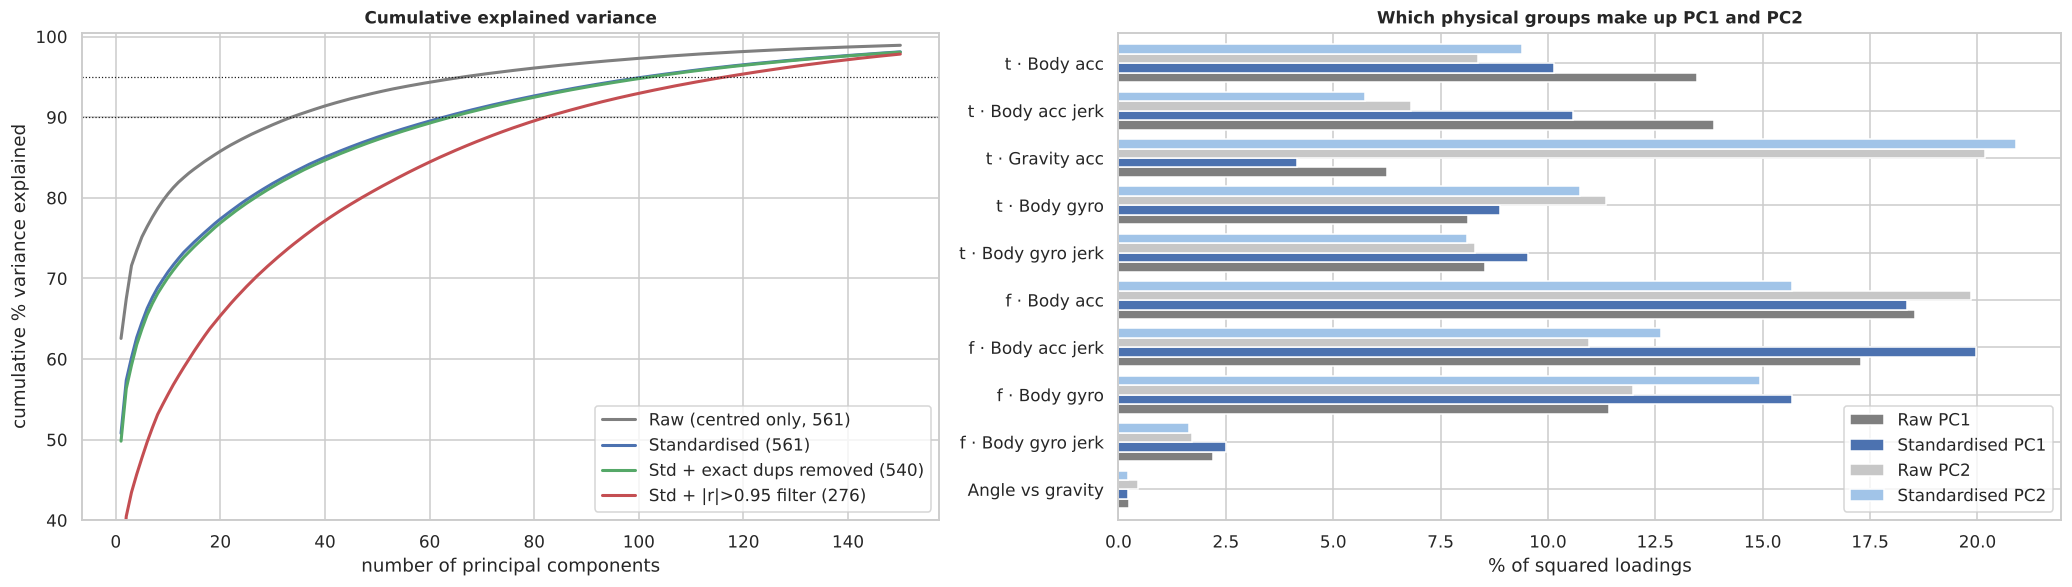

,components for 80% variance,components for 90% variance,components for 95% variance,components for 99% variance,PC1 % variance
"Raw (centred only, 561)",10,34,67,155,62.6
Standardised (561),26,63,102,179,50.8
Std + exact dups removed (540),27,64,103,179,49.8
Std + |r|>0.95 filter (276),47,83,117,176,32.7


In [40]:
variants = {
    "Raw (centred only, 561)": X_train,
    "Standardised (561)": Xs_train,
    f"Std + exact dups removed ({len(keep_dedup)})": Xs_train[keep_dedup],
    f"Std + |r|>0.95 filter ({len(kept_095)})": Xs_train[kept_095],
}
pcas = {name: PCA(svd_solver="full").fit(data) for name, data in variants.items()}

targets = [0.80, 0.90, 0.95, 0.99]
pca_table = pd.DataFrame({name: [int(np.searchsorted(np.cumsum(p.explained_variance_ratio_), t) + 1) for t in targets]
                          for name, p in pcas.items()},
                         index=[f"components for {int(t * 100)}% variance" for t in targets]).T
pca_table["PC1 % variance"] = [round(p.explained_variance_ratio_[0] * 100, 1) for p in pcas.values()]

fig, axes = plt.subplots(1, 2, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
for (name, p), c in zip(pcas.items(), ["#7f7f7f", "#4c72b0", "#55a868", "#c44e52"]):
    axes[0].plot(np.arange(1, 151), np.cumsum(p.explained_variance_ratio_)[:150] * 100, label=name, color=c, lw=2)
for t in targets[1:3]:
    axes[0].axhline(t * 100, ls=":", color="k", lw=0.8)
axes[0].set(xlabel="number of principal components", ylabel="cumulative % variance explained",
            title="Cumulative explained variance", ylim=(40, 100.5))
axes[0].legend(loc="lower right")

pc1 = pd.DataFrame({
    "Raw PC1": weight_share(pd.Series(pcas["Raw (centred only, 561)"].components_[0] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
    "Standardised PC1": weight_share(pd.Series(pcas["Standardised (561)"].components_[0] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
    "Raw PC2": weight_share(pd.Series(pcas["Raw (centred only, 561)"].components_[1] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
    "Standardised PC2": weight_share(pd.Series(pcas["Standardised (561)"].components_[1] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
})
pc1.iloc[::-1].plot.barh(ax=axes[1], width=0.8, color=["#7f7f7f", "#4c72b0", "#c7c7c7", "#a1c4e8"])
axes[1].set(xlabel="% of squared loadings", ylabel="", title="Which physical groups make up PC1 and PC2")
plt.tight_layout()
plt.show()
pca_table

**What PCA reveals**
* **Raw data looks more compressible than it is.** 34 components reach 90 % of the variance, against 63 after standardisation, because a few high-variance features dominate the raw covariance. The standardised count is the fairer measure of dimensionality.
* **One "movement intensity" factor dominates.** PC1 explains 51 % of standardised variance, and its loadings are spread across every body-motion group. PC2 is led by **gravity** (≈ 20 % of its loadings in both versions), i.e. **orientation/posture**. This matches the static/dynamic and laying/upright splits seen in §3.2.
* **Exact duplicate removal barely changes the geometry** (102 → 103 components for 95 %).
* **The 0.95 filter halves the features but keeps most independent directions.** PC1 falls from 51 % to 33 % because many near-copies of "intensity" are gone, and 95 % of the variance now needs 117 of 276 components. The filtered set is far less redundant without collapsing.

###### 6.5 How the train-fitted scaling transfers to the test subjects
If train and test came from the same distribution, standardised test features would have mean ≈ 0 and standard deviation ≈ 1. Departures show covariate shift between the 21 training subjects and the 9 test subjects.

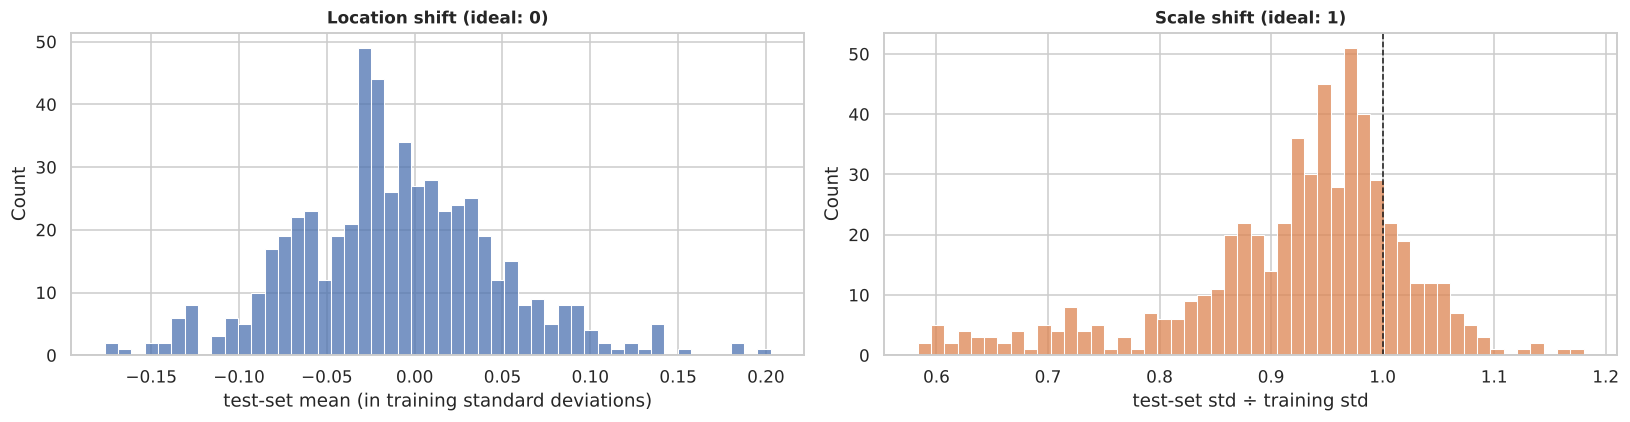

median |mean shift| (σ units)                  0.034
features with |mean shift| > 0.2σ                  1
features with std ratio outside [0.8, 1.25]       66
  of which energy / bandsEnergy                   57


,test mean (σ),test std ratio,group
"tBodyGyroJerk-correlation()-Y,Z",0.203,1.006,t · Body gyro jerk
"tGravityAcc-arCoeff()-X,1",0.186,1.034,t · Gravity acc
tBodyGyroMag-entropy(),0.182,0.954,t · Body gyro
tGravityAcc-sma(),-0.177,0.907,t · Gravity acc
"tGravityAcc-arCoeff()-X,2",-0.173,1.024,t · Gravity acc
"tBodyGyro-arCoeff()-X,3",-0.163,1.025,t · Body gyro
"tGravityAcc-arCoeff()-X,3",0.156,1.017,t · Gravity acc
tGravityAcc-energy()-Z,-0.152,0.892,t · Gravity acc


In [41]:
test_mean, test_std = Xs_test.mean(), Xs_test.std()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(test_mean, bins=50, ax=axes[0], color="#4c72b0")
axes[0].set(xlabel="test-set mean (in training standard deviations)", title="Location shift (ideal: 0)")
sns.histplot(test_std, bins=50, ax=axes[1], color="#dd8452")
axes[1].axvline(1, color="k", ls="--", lw=1)
axes[1].set(xlabel="test-set std ÷ training std", title="Scale shift (ideal: 1)")
plt.tight_layout()
plt.show()

print(pd.Series(dtype=object, data={
    "median |mean shift| (σ units)": round(float(test_mean.abs().median()), 3),
    "features with |mean shift| > 0.2σ": int((test_mean.abs() > 0.2).sum()),
    "features with std ratio outside [0.8, 1.25]": int(((test_std < 0.8) | (test_std > 1.25)).sum()),
    "  of which energy / bandsEnergy": int(meta.loc[test_std.index[(test_std < 0.8) | (test_std > 1.25)], "statistic"]
                                            .isin(["energy", "bandsEnergy"]).sum()),
}).to_string())
pd.DataFrame({"test mean (σ)": test_mean, "test std ratio": test_std, "group": group_of}) \
    .reindex(test_mean.abs().sort_values(ascending=False).index).head(8).round(3)

**Train-fitted scaling transfers well, with one systematic difference**
* **Location:** test means are essentially centred (median |shift| 0.03 σ, largest 0.20 σ). No feature is badly mis-centred.
* **Scale:** the test set is systematically *narrower* (median std ratio 0.94). The 66 features below 0.8 are mostly frequency-domain `energy`/`bandsEnergy` features (57 of 66), and none are above 1.25. These heavy-tailed energy features depend on how vigorously each person moves, so the 9 test subjects simply cover a smaller range than the 21 training subjects.
* **Implication:** between-subject variation is real and concentrated in energy features. Validation should hold out whole subjects, and a log or Yeo–Johnson transform of the energy features would reduce sensitivity to a few vigorous subjects.

##### 7. Summary and recommended preprocessing

In [42]:
summary = pd.Series({
    "Windows (train / test)": f"{len(X_train):,} / {len(X_test):,}",
    "Subjects (train / test), overlap": f"{subj_train.nunique()} / {subj_test.nunique()}, none",
    "Missing / non-finite values": int(X_all.isna().to_numpy().sum() + np.isinf(arr_all).sum()),
    "Duplicate rows (within or across splits)": int(h_train.duplicated().sum() + h_test.duplicated().sum() + h_test.isin(set(h_train)).sum()),
    "Duplicate feature names (bandsEnergy X/Y/Z)": f"{len(dup_names)} names × 3 = {int(dup_names.sum())} columns, renamed",
    "Value-identical columns": f"{len(dup_groups)} groups, {len(exact_drop)} redundant",
    "Zero-variance features": int((const["variance"] == 0).sum()),
    "Discrete features (≤ 50 distinct values)": int((const["n_unique"] <= 50).sum()),
    "Value range": f"[{arr_all.min():.0f}, {arr_all.max():.0f}]",
    "Cells outside 1.5×IQR fences (train)": f"{out_mask.to_numpy().mean() * 100:.1f}%",
    "Features with |skew| > 1": int((shape["skewness"].abs() > 1).sum()),
    "Variance ratio max / min": f"{shape['variance'].max() / shape['variance'].min():.0f}×",
    "Feature pairs with |r| ≥ 0.95": int((pair_r >= 0.95).sum()),
    "Features kept by |r| > 0.95 filter": f"{len(kept_095)} of 561",
    "PCA components for 95% (standardised)": int(pca_table.loc["Standardised (561)", "components for 95% variance"]),
    "Median |test mean shift| after scaling": f"{test_mean.abs().median():.2f} σ",
}).to_frame("result")
summary

,result
Windows (train / test),"7,352 / 2,947"
"Subjects (train / test), overlap","21 / 9, none"
Missing / non-finite values,0
Duplicate rows (within or across splits),0
Duplicate feature names (bandsEnergy X/Y/Z),"42 names × 3 = 126 columns, renamed"
Value-identical columns,"19 groups, 21 redundant"
Zero-variance features,0
Discrete features (≤ 50 distinct values),11
Value range,"[-1, 1]"
Cells outside 1.5×IQR fences (train),4.0%


###### Key findings
1. **Clean data.** There are no missing or non-finite values, no duplicate windows, no constant features, and no subject overlap between train and test. Classes are reasonably balanced (13–19 % each). All values are already bounded in [−1, 1].
2. **Two labelling problems in the source files:**
   * 126 `bandsEnergy` columns share 42 names (they are the X/Y/Z axes).
   * 21 columns are exact copies: `tGravityAccMag` ≡ `tBodyAccMag`, which is a source bug, and `Mag-sma()` ≡ `Mag-mean()`, which holds by definition.
3. **Extremes and saturation are signal, not noise.** 80 % of outliers come from dynamic windows, and the pile-ups at −1 are floor effects from static postures.
4. **Distributions are skewed and bimodal.** About half the features have |skew| > 1, especially frequency-domain energies, and most features mix static and dynamic modes.
5. **The feature set is highly redundant.** 70 % of features have a near-twin at |r| ≥ 0.95, and a 0.95 filter halves the set (561 → 276). Spread statistics (`std`/`mad`/`iqr`) and time/frequency energies (Parseval's theorem) are the main overlaps.
6. **Two main axes of information:** movement intensity (all body-motion groups, PC1) and posture/orientation (gravity and angle features, PC2).
7. **Standardisation changes the relative weights.** It equalises features rather than physical groups, which raises gyroscope and frequency-domain weight. It also amplifies a set of near-zero-information features, such as body-signal `mean()`, by up to 25×.

###### Recommended preprocessing decisions

| # | Decision | Why (evidence in this notebook) |
|---|---|---|
| 1 | **Keep all rows.** No imputation, row de-duplication, outlier removal or clipping. | 0 missing and 0 duplicate rows; values bounded; extremes come from dynamic activities (§2.5). |
| 2 | **Rename the 126 `bandsEnergy` columns** with `-X/-Y/-Z` suffixes. | Same-named columns hold different data (§2.3). Unique names are needed by pandas, sklearn and any feature-importance work. |
| 3 | **Drop the 21 value-identical columns** (561 → 540). | Lossless (§2.3); removes the `tGravityAccMag` bug and stops gravity being double-counted (§6.3). |
| 4 | **Standardise with `StandardScaler` fitted on training data only**, inside each CV fold, for scale-sensitive models (k-NN, SVM, logistic regression, PCA, neural networks). Not needed for tree ensembles. | Variances differ 339× (§3.3). Standardisation is linear, so correlations and shapes are unchanged (§6). The train-fitted scaler transfers well (§6.5). |
| 5 | **Flag low-signal features as removal candidates and test the removal in CV:** body-signal `mean()` (12) and the 4 `angle()` features built on body means. | η² ≈ 0.00–0.03, physically ≈ 0 by construction, and amplified up to 25× by scaling (§6.2). |
| 6 | **For linear or distance-based models, or for interpretability: apply a \|r\| > 0.95 correlation filter fitted on train** (→ 276 features), or use PCA (~100 components for 95 %). Treat the threshold as a hyperparameter. | 2,281 pairs ≥ 0.95; `std`/`mad`/`iqr` and time/frequency energies are near-copies (§4). |
| 7 | **Optional:** Yeo–Johnson or log transform of `energy`/`bandsEnergy` features for models that assume roughly Gaussian inputs (LDA, Gaussian NB). | Median skew 2–3, kurtosis up to 19 (§3.1); main source of train/test scale shift (§6.5). |
| 8 | **Validate with subject-wise splits** (`GroupKFold` on `subject`), never random row splits. | 50 % window overlap between consecutive rows; between-subject differences in energy features (§6.5). |

The cell below implements decisions 2–4 as a leakage-safe sklearn pipeline (decision 2 happens at load time). Decisions 5–7 are optional steps to compare during modelling.

In [43]:
# The recommended baseline, as a leakage-safe sklearn pipeline: put it in front of any model and fit it
# inside cross-validation so the scaler only ever sees training folds.
baseline_preprocess = Pipeline([
    ("drop_exact_duplicates", ColumnTransformer([("keep", "passthrough", keep_dedup)], remainder="drop")),
    ("standardise", StandardScaler()),
])
Xp_train = baseline_preprocess.fit_transform(X_train)
Xp_test = baseline_preprocess.transform(X_test)
print("Preprocessed train:", Xp_train.shape, " test:", Xp_test.shape)

Preprocessed train: (7352, 540)  test: (2947, 540)


In [44]:
# Per-feature audit table for the rest of the team
audit = meta.drop(columns=["col"]).copy()
audit["group"] = group_of
audit = audit.join(shape[["mean", "std", "variance", "skewness", "excess kurtosis", "bimodality coef"]])
audit = audit.join(extreme[["% at -1", "% at +1", "% IQR outliers"]])
audit["n_unique"] = const["n_unique"]
audit["max |r| with another feature"] = max_abs_r
audit["exact duplicate of"] = pd.Series(exact_dup_of)
audit["keep: exact dedup"] = audit.index.isin(keep_dedup)
audit["keep: |r|>0.95 filter"] = audit.index.isin(kept_095)
audit["eta2 activity"] = eta2
audit["test mean shift (σ)"] = test_mean
audit.index.name = "feature"

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(exist_ok=True)
    audit.to_csv(OUTPUT_DIR / "task1_feature_audit.csv")
    print("Saved", OUTPUT_DIR / "task1_feature_audit.csv")
audit.head()

Saved task1_outputs/task1_feature_audit.csv


,raw_name,domain,signal,sensor,component,jerk,magnitude,axis,statistic,group,mean,std,variance,skewness,excess kurtosis,bimodality coef,% at -1,% at +1,% IQR outliers,n_unique,max |r| with another feature,exact duplicate of,keep: exact dedup,keep: |r|>0.95 filter,eta2 activity,test mean shift (σ)
feature,,,,,,,,,,,,,,,,,,,,,,,,,,
tBodyAcc-mean()-X,tBodyAcc-mean()-X,Time,tBodyAcc,accelerometer,body,False,False,X,mean,t · Body acc,0.2745,0.0703,0.0049,-3.4483,50.9114,0.2391,0.0136,0.0136,24.4151,7347,0.5443,NaN,True,True,0.0119,-0.0070
tBodyAcc-mean()-Y,tBodyAcc-mean()-Y,Time,tBodyAcc,accelerometer,body,False,False,Y,mean,t · Body acc,-0.0177,0.0408,0.0017,-0.4030,172.4857,0.0066,0.0136,0.0136,15.2612,7352,0.1952,NaN,True,True,0.0107,-0.0041
tBodyAcc-mean()-Z,tBodyAcc-mean()-Z,Time,tBodyAcc,accelerometer,body,False,False,Z,mean,t · Body acc,-0.1091,0.0566,0.0032,1.7845,85.9750,0.0470,0.0136,0.0136,16.0501,7349,0.2935,NaN,True,True,0.0070,0.0133
tBodyAcc-std()-X,tBodyAcc-std()-X,Time,tBodyAcc,accelerometer,body,False,False,X,std,t · Body acc,-0.6054,0.4487,0.2014,0.6774,-0.8656,0.6831,0.0136,0.0136,0.0272,7349,0.9986,NaN,True,True,0.9254,-0.0183
tBodyAcc-std()-Y,tBodyAcc-std()-Y,Time,tBodyAcc,accelerometer,body,False,False,Y,std,t · Body acc,-0.5109,0.5026,0.2527,0.4059,-1.4527,0.7522,0.0000,0.0000,0.0000,7351,0.9978,NaN,True,True,0.8912,0.0052


### Task 2 — Natural structure and movement relationships

Objective: Investigate whether the sensor data suggest meaningful movement groups and relationships.

**Member**: Abrar

What needs to be done:
1. Explore PCA projections of the sensor measurements.
2. Examine whether observations form distinct regions, overlapping distributions or continuous patterns.
3. Look for broad movement families and possible finer subdivisions.
4. Compare the apparent structure against known activity labels, using labels only for interpretation.
5. Investigate whether some activities occupy overlapping or nested regions of sensor space.
Expected output: Evidence describing the apparent organisation of movement and hypotheses about shared movement patterns.

At this stage, visual groupings are exploratory evidence, not validated clusters.

*Code merged from task2_abrar_EDA.ipynb.*

#### Task 2 — Natural structure and movement relationships (Abrar)

**The question in plain words:** if we hide the activity labels and simply *look* at the sensor data, does it fall into natural groups? Are those groups sharp and separate, do they overlap, or do they blend smoothly into each other?

**What data we use**
- The **scaled training windows** from the preprocessing step (`X_train_scaled_df`): 7,352 windows × 561 features.
- One row = one **2.56-second window** of one person doing one activity. This is our unit of analysis.
- We use only the training set so that the test set stays untouched for later steps, the same choice the team made when fitting the scaler.

**The one rule of this section:** PCA never sees `activity_name` or `subject_id`. We first look at the shapes *without* labels. Only afterwards do we colour the points by the true labels, to *interpret* what we found.

**Plan**
1. Run PCA and see how much information the first few components hold.
2. Find out what each of the first components means physically.
3. Look at the data **without labels**: is there any structure at all?
4. Add the labels and compare.
5. Look for broad movement families, then finer groups inside each family.
6. Measure which activities overlap, and which sit inside one another.
7. Check the picture with a second, non-linear method (t-SNE).
8. Summarise the evidence and the hypotheses we will test with real clustering in RQ1.

*Reminder from the brief: everything here is exploratory evidence, not validated clusters.*

In [45]:
# ---- Setup for Task 2 -------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform

RNG = 42                                   # fixed seed so every result can be reproduced
X2 = X_train_scaled_df.values               # 7,352 x 561, already standardised
acts = meta_train["activity_name"].to_numpy(dtype=object)    # used ONLY for interpretation
subj = meta_train["subject_id"].to_numpy()                   # used ONLY for interpretation

# Fixed activity order and colours (dynamic first, then static), checked for colour-blind safety
ACT_ORDER = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
SHORT = {"WALKING": "Walk", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sit", "STANDING": "Stand", "LAYING": "Lay"}
COLORS = dict(zip(ACT_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
DYNAMIC = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
print("Windows:", X2.shape[0], "| Features:", X2.shape[1])

Windows: 7352 | Features: 561


##### 2.1 How much information do the first components hold?

**What PCA does:** it rotates the data to find new axes (called *principal components*, PC1, PC2, ...). PC1 is the direction where the data spreads the most, PC2 the next most, and so on. If a few PCs hold most of the spread, the 561 features are really telling a much smaller story.

Share of information in each of the first 5 PCs: [50.8  6.6  2.8  2.5  1.9] %
  50% of the information needs   1 PCs (out of 561)
  80% of the information needs  26 PCs (out of 561)
  90% of the information needs  63 PCs (out of 561)
  95% of the information needs 102 PCs (out of 561)


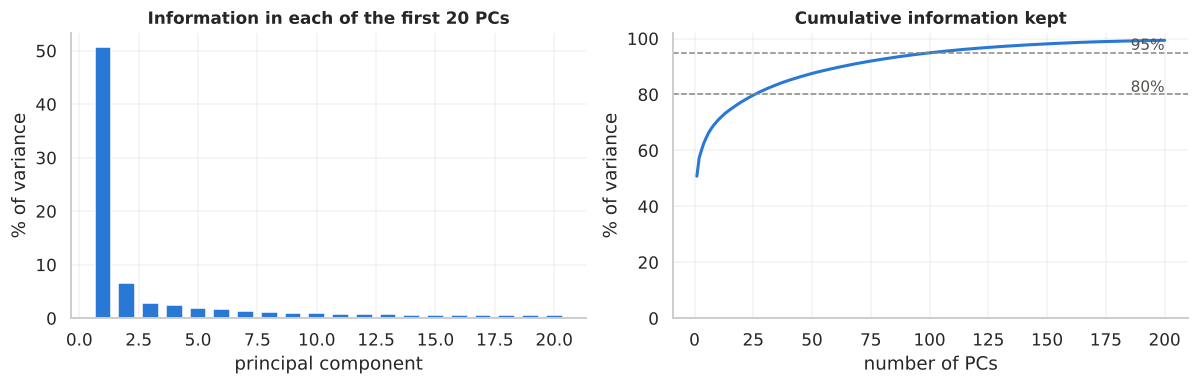

In [46]:
pca = PCA(random_state=RNG).fit(X2)
Z = pca.transform(X2)                       # every window, expressed in PC coordinates
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

print("Share of information in each of the first 5 PCs:", np.round(evr[:5] * 100, 1), "%")
for target in [0.50, 0.80, 0.90, 0.95]:
    print(f"  {target:.0%} of the information needs {np.argmax(cum >= target) + 1:>3} PCs (out of 561)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(range(1, 21), evr[:20] * 100, color="#2a78d6", width=0.7)
ax[0].set(title="Information in each of the first 20 PCs", xlabel="principal component", ylabel="% of variance")
ax[1].plot(range(1, 201), cum[:200] * 100, color="#2a78d6", lw=2)
for t, c in [(80, "#898781"), (95, "#898781")]:
    ax[1].axhline(t, ls="--", lw=1, color=c)
    ax[1].text(200, t + 1, f"{t}%", ha="right", color="#52514e")
ax[1].set(title="Cumulative information kept", xlabel="number of PCs", ylabel="% of variance", ylim=(0, 102))
plt.tight_layout(); plt.show()

**What this shows**
- **PC1 alone holds about half (≈51%) of all the variation.** That is unusually large. It means one single "theme" dominates the whole dataset.
- After PC1, each extra component adds only a little (PC2 ≈ 7%, PC3 ≈ 3%).
- About **100 components keep 95%** of the information. So the 561 features contain a lot of repetition, which matches the redundancy that Task 1 looks at.

**Why this matters for later:** a 2-D picture (PC1 + PC2) shows only about 57% of the information. So what looks like overlap in a 2-D plot might **not** be real overlap in the full space. We check exactly this in Section 2.6.

##### 2.2 What does each component mean physically?

A PC is a weighted mix of the original features. The features with the biggest weights (called *loadings*) tell us what the PC "is about".

In [47]:
def top_loadings(k, n=8):
    w = pd.Series(pca.components_[k], index=X_train_scaled_df.columns)
    return w.reindex(w.abs().sort_values(ascending=False).index)[:n].round(3)

for k in range(3):
    print(f"\n--- PC{k+1} ({evr[k]*100:.1f}% of variance): strongest features ---")
    print(top_loadings(k).to_string())


--- PC1 (50.8% of variance): strongest features ---
fBodyAcc-sma()                0.059
fBodyAccJerk-sma()            0.059
tBodyAccJerk-sma()            0.059
fBodyGyro-sma()               0.059
tBodyAccJerkMag-mean()        0.058
tBodyAccJerkMag-sma()         0.058
fBodyBodyAccJerkMag-mean()    0.058
fBodyBodyAccJerkMag-sma()     0.058

--- PC2 (6.6% of variance): strongest features ---
fBodyAcc-meanFreq()-Z        0.122
tBodyGyroMag-arCoeff()1      0.120
tBodyAccMag-arCoeff()1       0.118
tGravityAccMag-arCoeff()1    0.118
fBodyAccMag-meanFreq()       0.118
tGravityAcc-arCoeff()-Z,1    0.118
tGravityAcc-arCoeff()-Z,2   -0.117
tGravityAcc-arCoeff()-Z,3    0.115

--- PC3 (2.8% of variance): strongest features ---
tGravityAcc-energy()-X       0.110
tGravityAcc-arCoeff()-X,1    0.110
tGravityAcc-entropy()-Y     -0.110
tGravityAcc-energy()-Z      -0.109
tGravityAcc-min()-X          0.108
angle(X,gravityMean)        -0.108
tGravityAcc-std()-X         -0.104
tGravityAcc-mean()-X         0

**How to read the feature names:** `t` = time domain, `f` = frequency domain, `Body` = movement of the body, `Gravity` = direction of gravity (phone orientation), `Jerk` = how suddenly the movement changes, `Mag` = overall size, `sma` / `energy` / `mean` = how much movement in total.

**Interpretation**
- **PC1 = movement intensity.** Its top features are all "how much the body moves" (`BodyAcc-sma`, `BodyAccJerk`, `BodyGyro`). A high PC1 means a lot of motion, and a low PC1 means the person is still.
- **PC2 = rhythm and frequency of the signal.** It is driven by `arCoeff` (how a signal follows its own recent past) and `meanFreq` (the typical frequency). It describes *how* a movement repeats, not how strong it is.
- **PC3 = body orientation.** It is driven by `tGravityAcc` and `angle(X, gravityMean)`, which describe which way gravity points relative to the phone. That is posture: upright or lying down.

So the three main directions of the data have clear physical meanings: **intensity, rhythm and posture**.

##### 2.3 Looking WITHOUT labels: is there any structure at all?

First we look at the shape of the data with no colours. If the data were just one big shapeless cloud, there would be nothing to cluster.

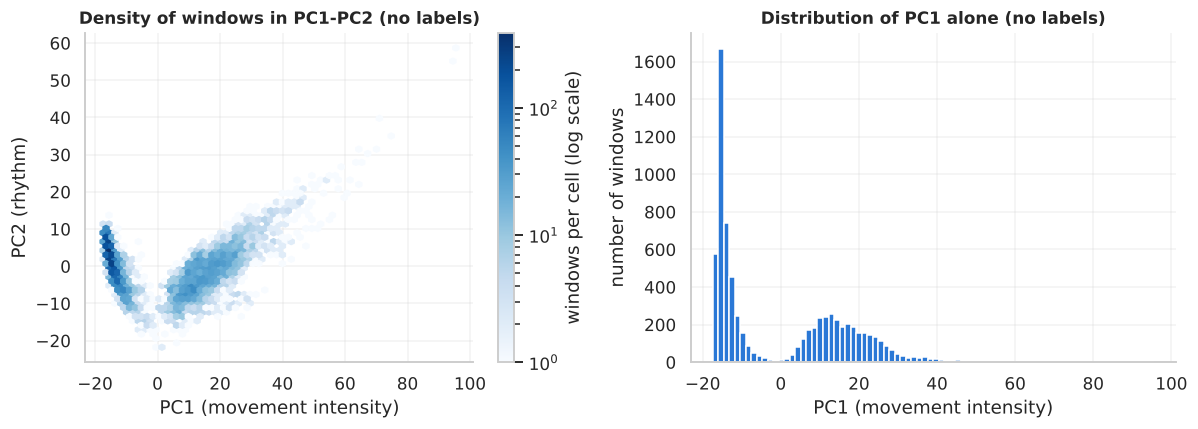

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hb = ax[0].hexbin(Z[:, 0], Z[:, 1], gridsize=60, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax[0], label="windows per cell (log scale)")
ax[0].set(title="Density of windows in PC1-PC2 (no labels)", xlabel="PC1 (movement intensity)", ylabel="PC2 (rhythm)")

ax[1].hist(Z[:, 0], bins=80, color="#2a78d6")
ax[1].set(title="Distribution of PC1 alone (no labels)", xlabel="PC1 (movement intensity)", ylabel="number of windows")
plt.tight_layout(); plt.show()

**Cluster tendency, measured: the Hopkins statistic**

Looking at a picture is subjective, so we also put a number on it. The **Hopkins statistic** compares two distances:
- how far a real window is from its nearest real neighbour, and
- how far a random fake point is from its nearest real window.

If the data are clumpy, real points sit close together while random points land in empty space, so the score gets close to **1**. A score near **0.5** means the data look like random noise with no structure.

In [49]:
def hopkins(data, n=500, seed=RNG):
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    real = data[rng.choice(len(data), n, replace=False)]
    w = nn.kneighbors(real)[0][:, 1]                            # real point -> nearest OTHER real point
    fake = rng.uniform(data.min(0), data.max(0), size=(n, data.shape[1]))
    u = nn.kneighbors(fake, n_neighbors=1)[0][:, 0]            # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

scores = [hopkins(Z[:, :10], seed=s) for s in range(5)]
print(f"Hopkins statistic on the first 10 PCs, 5 repeats: mean {np.mean(scores):.3f} (min {min(scores):.3f}, max {max(scores):.3f})")

Hopkins statistic on the first 10 PCs, 5 repeats: mean 0.941 (min 0.940, max 0.941)


**What this shows**
- The PC1 histogram has **two clear humps with a gap between them**. Even with no labels, the data naturally split into two big groups: windows with very little movement (left) and windows with a lot of movement (right).
- The right hump is **wide and flat**, while the left one is tall and narrow. The "moving" group is spread out, and the "still" group is packed tightly together.
- The Hopkins score is about **0.94**, far above the 0.5 of random data, so there is strong cluster tendency.

**A caution (good for the limitations box):** in many dimensions the Hopkins statistic is pushed upwards, because random points easily fall in empty space. So we treat it as *supporting* evidence, not proof. The two-hump histogram is the more convincing evidence.

##### 2.4 Now add the labels: which activity is where?

We colour the **same** points by their true activity. PCA did not use these colours; they only help us interpret the structure we already saw. We draw PC1 against PC2 and also PC1 against PC3, because PC3 was the posture axis.

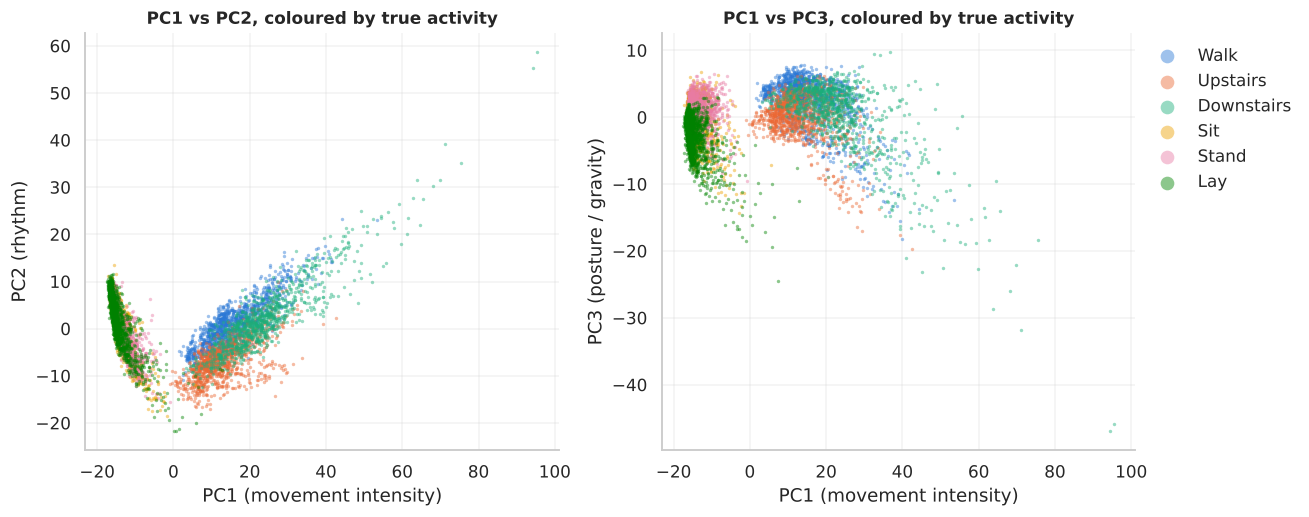

PC1        PC2       PC3     
                    mean   std mean  std mean  std
activity                                          
WALKING             15.8   7.4  1.0  4.9  2.3  3.8
WALKING_UPSTAIRS    12.9   6.5 -6.9  4.1 -0.2  3.4
WALKING_DOWNSTAIRS  23.8  10.9  2.1  7.3  0.1  5.7
SITTING            -14.0   2.5  1.0  5.3 -0.0  3.0
STANDING           -13.5   2.4  0.2  4.6  1.2  2.0
LAYING             -14.3   3.2  1.7  5.6 -3.1  3.2

In [50]:
def scatter_by_activity(ax, x, y, title, xl, yl, annotate=True):
    for a in ACT_ORDER:
        m = acts == a
        ax.scatter(x[m], y[m], s=5, alpha=0.45, color=COLORS[a], label=SHORT[a], linewidths=0)
        if annotate:
            ax.annotate(SHORT[a], (np.median(x[m]), np.median(y[m])), fontsize=9, weight="bold",
                        ha="center", color="#0b0b0b",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORS[a], alpha=0.9))
    ax.set(title=title, xlabel=xl, ylabel=yl)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
scatter_by_activity(ax[0], Z[:, 0], Z[:, 1], "PC1 vs PC2, coloured by true activity", "PC1 (movement intensity)", "PC2 (rhythm)", annotate=False)
scatter_by_activity(ax[1], Z[:, 0], Z[:, 2], "PC1 vs PC3, coloured by true activity", "PC1 (movement intensity)", "PC3 (posture / gravity)", annotate=False)
ax[1].legend(markerscale=4, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

summary = (pd.DataFrame({"activity": acts, "PC1": Z[:, 0], "PC2": Z[:, 1], "PC3": Z[:, 2]})
             .groupby("activity").agg(["mean", "std"]).round(1).reindex(ACT_ORDER))
summary

**What this shows**
- **The two humps from 2.3 are "moving" and "still".** Walking, upstairs and downstairs all sit on the right (high PC1). Sitting, standing and lying all sit on the left (low PC1).
- **In PC1-PC2, the three still activities sit almost on top of each other.** You cannot tell them apart in that view.
- **In PC1-PC3, lying shifts downwards (lower PC3) and starts to pull away from sitting and standing**, though it still touches them in this view. That makes sense physically: lying down turns the phone sideways, so gravity points in a different direction. Lying differs by **posture**, not by movement. We will see it separate much more clearly in 2.5.
- **Sitting and standing still overlap** in both views. Physically, both are upright and still. The only difference is a small change in body angle.
- The table shows that **walking downstairs has the biggest spread** on PC1 (std ≈ 11, compared with ≈ 2.5 for sitting). It is the most variable activity.

##### 2.5 Broad movement families, and finer groups inside each family

**Step 1: the broad split.** A very simple rule, PC1 > 0, splits the windows into two families. We check how well that rule matches "moving vs still".

In [51]:
is_dynamic = np.isin(acts, DYNAMIC)
family_pred = Z[:, 0] > 0
agree = (family_pred == is_dynamic).mean()
print(f"The simple rule 'PC1 > 0' puts {agree:.1%} of windows in the right family (moving vs still).")
print(pd.crosstab(pd.Series(np.where(is_dynamic, "moving (true)", "still (true)"), name=""),
                  pd.Series(np.where(family_pred, "PC1 > 0", "PC1 <= 0"), name="")))

The simple rule 'PC1 > 0' puts 99.8% of windows in the right family (moving vs still).
               PC1 <= 0  PC1 > 0
                                
moving (true)         3     3282
still (true)       4053       14


**Step 2: zoom inside each family.** We now run a *separate* PCA on each family. Inside one family, the big difference (moving vs still) is gone, so PCA can find the smaller differences that were hidden before.

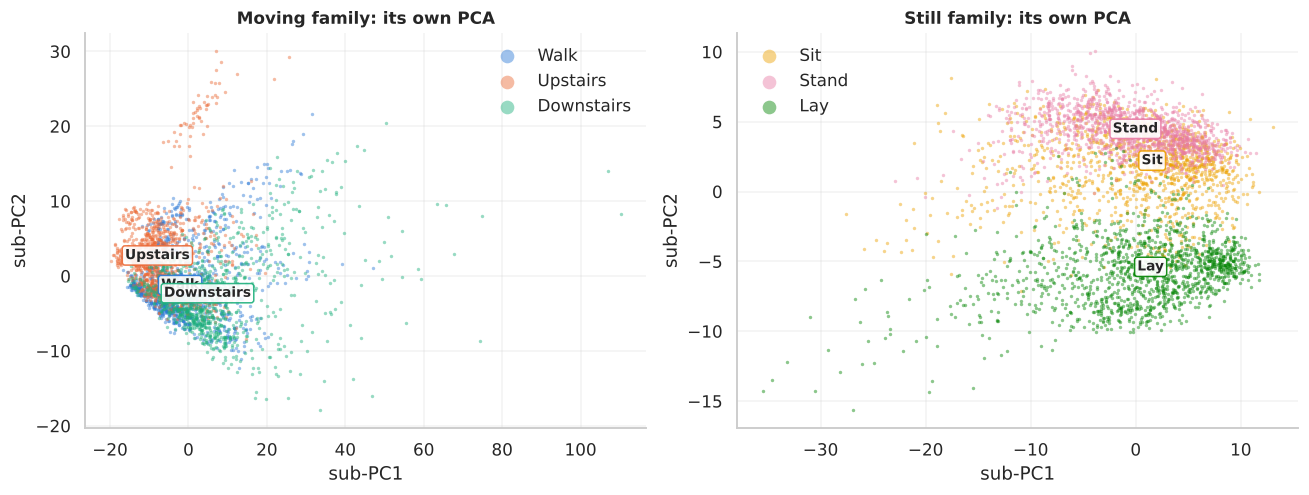

Moving family: first 3 sub-PCs hold [29.4  7.   5.6] % of the family's variance
Still family: first 3 sub-PCs hold [20.  11.   5.8] % of the family's variance


In [52]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sub_info = {}
for k, (name, members) in enumerate([("Moving family", DYNAMIC),
                                     ("Still family", ["SITTING", "STANDING", "LAYING"])]):
    m = np.isin(acts, members)
    p_sub = PCA(n_components=5, random_state=RNG).fit(X2[m])
    Zs = p_sub.transform(X2[m])
    sub_info[name] = np.round(p_sub.explained_variance_ratio_[:3] * 100, 1)
    for a in members:
        mm = acts[m] == a
        ax[k].scatter(Zs[mm, 0], Zs[mm, 1], s=5, alpha=0.45, color=COLORS[a], label=SHORT[a], linewidths=0)
        ax[k].annotate(SHORT[a], (np.median(Zs[mm, 0]), np.median(Zs[mm, 1])), fontsize=9, weight="bold",
                       ha="center", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORS[a], alpha=0.9))
    ax[k].set(title=f"{name}: its own PCA", xlabel="sub-PC1", ylabel="sub-PC2")
    ax[k].legend(markerscale=4, frameon=False)
plt.tight_layout(); plt.show()
for name, v in sub_info.items():
    print(f"{name}: first 3 sub-PCs hold {v} % of the family's variance")

**What this shows**
- **The broad split is almost perfect:** the rule `PC1 > 0` gets about **99.8%** of windows into the right family. "Moving vs still" is the strongest, most natural structure in the data.
- **Inside the still family:** **lying now forms its own clear region** (bottom of the plot). **Sitting and standing are still mixed**, although standing sits a little higher on average.
- **Inside the moving family:** **upstairs partly moves away** (to the left and up), but **walking and downstairs still overlap heavily** in this 2-D view. Downstairs also has a **long tail** of windows stretching far to the right, so its shape is stretched rather than round.
- The groups touch each other without clear gaps. That looks more like a **continuous** pattern with soft borders than like separate islands. *(Section 2.7 shows that walking and downstairs separate much better in the full space than in this 2-D view.)*

So the data look like a **hierarchy (a family tree)**, not six equal groups:

```
All windows
├── Moving:  walking, upstairs, downstairs   (close neighbours, soft borders, downstairs stretched)
└── Still:   lying  |  sitting + standing    (lying apart by posture; sitting and standing heavily mixed)
```

##### 2.6 Testing the family tree with distances

To check the tree with numbers, we compute the **centre** of each activity (its average position) in the first 50 PCs, then measure the distance between every pair of centres. A *dendrogram* joins the closest pair first, then the next closest, and so on.

We use 50 PCs because they keep about 87% of the information while removing much of the noise.

The first 50 PCs keep 87.5% of the information.


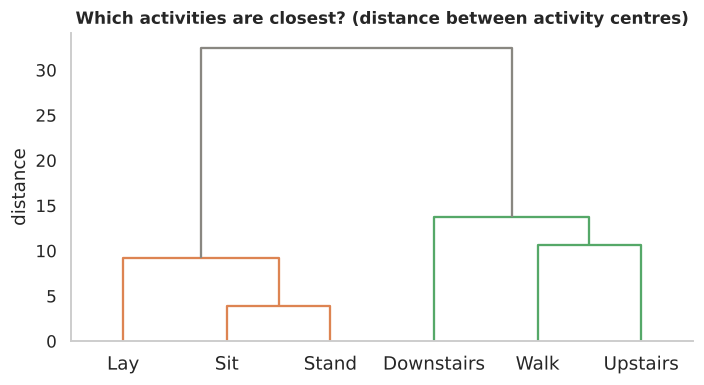

,Walk,Upstairs,Downstairs,Sit,Stand,Lay
Walk,0.0,10.6,11.9,30.4,30.0,31.3
Upstairs,10.6,0.0,15.6,28.4,28.0,29.4
Downstairs,11.9,15.6,0.0,38.2,37.9,38.7
Sit,30.4,28.4,38.2,0.0,3.9,8.2
Stand,30.0,28.0,37.9,3.9,0.0,10.2
Lay,31.3,29.4,38.7,8.2,10.2,0.0


In [53]:
N_PC = 50
Z50 = Z[:, :N_PC]
print(f"The first {N_PC} PCs keep {cum[N_PC-1]:.1%} of the information.")

centres = pd.DataFrame(Z50).groupby(acts).mean().reindex(ACT_ORDER)
dist = pd.DataFrame(squareform(pdist(centres)), index=[SHORT[a] for a in ACT_ORDER],
                    columns=[SHORT[a] for a in ACT_ORDER]).round(1)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
dendrogram(linkage(centres.values, method="average"), labels=[SHORT[a] for a in ACT_ORDER],
           ax=ax, color_threshold=20, above_threshold_color="#898781")
ax.set(title="Which activities are closest? (distance between activity centres)", ylabel="distance")
ax.grid(False); plt.tight_layout(); plt.show()
dist

**What this shows (read the dendrogram from the bottom up)**
1. **Sitting and standing join first** (distance ≈ 4). They are the most similar pair by far.
2. **Lying joins them next** (≈ 8–10): it is still close, but a little apart.
3. **Walking and upstairs join** (≈ 11), then **downstairs** joins them (≈ 12–16).
4. **The two families join only at the very top** (≈ 28–39), which is **about 2.5 to 10 times larger** than the distances inside a family.

This confirms the tree from 2.5 with numbers. It also answers one of RQ1's sub-questions: **yes, walking and upstairs are closer to each other than to downstairs, and sitting and standing are the closest pair of all.**

*Note:* these are distances between **centres**. They tell us how far apart groups are on average, but not how much the groups overlap. We measure overlap next.

##### 2.7 Measuring overlap: who are each window's neighbours?

**The idea:** for every window, find its **10 nearest neighbours** in the 50-PC space. If an activity is a clean, separate group, its windows' neighbours will almost all have the same activity. If two activities overlap, their neighbours will be mixed.

> *Real-life example:* if you live in a "Bangladeshi area" of a city, most of your 10 nearest neighbours are Bangladeshi. In a mixed area, your neighbours come from many backgrounds.

Each row of the table below answers: *"For windows of this activity, what share of their neighbours belong to each activity?"*

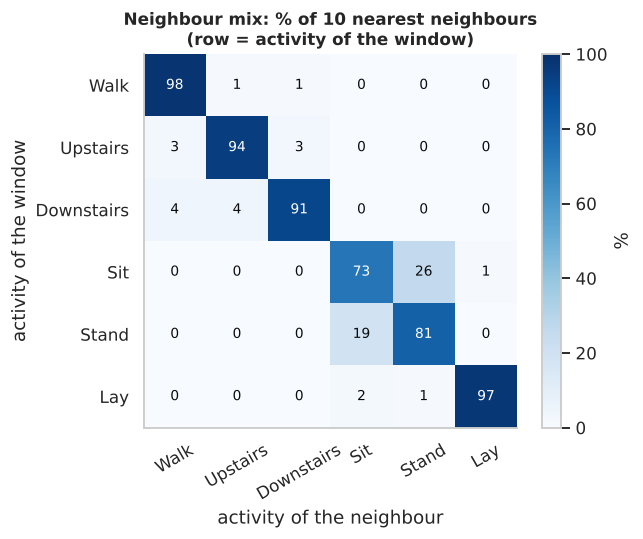

Same-activity neighbours using only PC1-PC2: 50.6%
Same-activity neighbours using 50 PCs:       88.8%


,Walk,Upstairs,Downstairs,Sit,Stand,Lay
Walk,98.4,0.8,0.8,0.0,0.0,0.0
Upstairs,3.0,94.2,2.8,0.0,0.0,0.0
Downstairs,4.3,4.5,91.2,0.0,0.0,0.0
Sit,0.0,0.1,0.0,72.9,25.9,1.1
Stand,0.0,0.0,0.0,19.1,80.9,0.1
Lay,0.0,0.1,0.0,1.8,1.0,97.1


In [54]:
K = 10
nn = NearestNeighbors(n_neighbors=K + 1).fit(Z50)
_, idx = nn.kneighbors(Z50)
nbr_acts = acts[idx[:, 1:]]                        # drop column 0 = the window itself

mix = pd.DataFrame({b: [(nbr_acts[acts == a] == b).mean() * 100 for a in ACT_ORDER] for b in ACT_ORDER},
                   index=ACT_ORDER)
mix.index = mix.columns = [SHORT[a] for a in ACT_ORDER]

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(mix.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(6), mix.columns, rotation=30); ax.set_yticks(range(6), mix.index)
for r in range(6):
    for c in range(6):
        v = mix.values[r, c]
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > 55 else "#0b0b0b")
ax.set(title="Neighbour mix: % of 10 nearest neighbours\n(row = activity of the window)",
       xlabel="activity of the neighbour", ylabel="activity of the window")
ax.grid(False); fig.colorbar(im, ax=ax, label="%"); plt.tight_layout(); plt.show()

# Does the 2-D picture tell the truth? Compare "same-activity neighbours" in 2 PCs vs 50 PCs
def purity(data):
    _, ix = NearestNeighbors(n_neighbors=K + 1).fit(data).kneighbors(data)
    return (acts[ix[:, 1:]] == acts[:, None]).mean()
print(f"Same-activity neighbours using only PC1-PC2: {purity(Z[:, :2]):.1%}")
print(f"Same-activity neighbours using 50 PCs:       {purity(Z50):.1%}")
mix.round(1)

**What this shows**
- **Walking (98%), lying (97%), upstairs (94%) and downstairs (91%) are well separated.** Most of their neighbours are the same activity.
- **Sitting and standing truly overlap.** About **26%** of a sitting window's neighbours are standing windows, and about **19%** the other way round. That is the only big overlap.
- **The moving activities overlap a little, with each other only** (3–5% for upstairs and downstairs). Moving and still windows are almost never neighbours (≈ 0%).
- **The 2-D picture is misleading.** With only PC1-PC2, only about **51%** of neighbours share the same activity. With 50 PCs, it is about **89%**. Many groups that look mixed in the flat 2-D plot are actually separate in the full space, the way two people can look close together in a photo while one stands far behind the other.

**Lesson for the poster:** a PCA scatter plot is useful for a first look, but conclusions about overlap must come from the full space, not the 2-D picture.

##### 2.8 Nested regions: how spread out is each activity, and are there groups inside groups?

Two checks:
1. **Spread (dispersion):** the average distance from each window to its activity's centre. A big number means the activity is loose and varied.
2. **People inside activities:** do a window's neighbours tend to come from the **same person**? If yes, each activity contains smaller "personal" sub-regions nested inside it. That would be a structure *finer* than the six labels.

If people did not matter, about 4.8% of neighbours would be from the same person (1 out of 21).
Observed over all windows: 53.7%


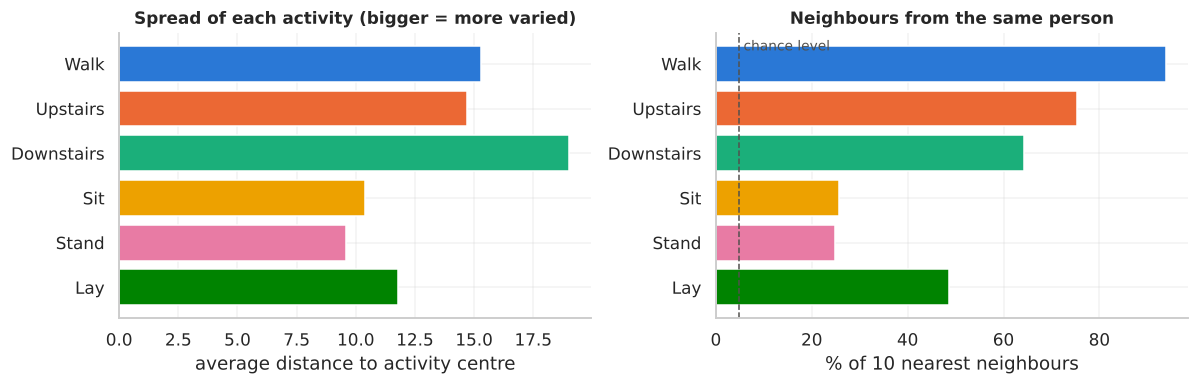

,windows,avg distance to centre (spread),% neighbours from SAME person
activity,,,
Walk,1226,15.3,93.8
Upstairs,1073,14.7,75.4
Downstairs,986,19.0,64.2
Sit,1286,10.4,25.6
Stand,1374,9.6,24.8
Lay,1407,11.8,48.7


In [55]:
rows = []
for a in ACT_ORDER:
    m = acts == a
    d = np.linalg.norm(Z50[m] - Z50[m].mean(0), axis=1)
    same_person = (subj[idx[m, 1:]] == subj[m, None]).mean()
    rows.append({"activity": SHORT[a], "windows": m.sum(),
                 "avg distance to centre (spread)": round(d.mean(), 1),
                 "% neighbours from SAME person": round(same_person * 100, 1)})
nested = pd.DataFrame(rows).set_index("activity")
chance = 100 / len(np.unique(subj))
overall = (subj[idx[:, 1:]] == subj[:, None]).mean() * 100
print(f"If people did not matter, about {chance:.1f}% of neighbours would be from the same person (1 out of 21).")
print(f"Observed over all windows: {overall:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh(nested.index[::-1], nested.iloc[::-1, 1], color=[COLORS[a] for a in ACT_ORDER[::-1]])
ax[0].set(title="Spread of each activity (bigger = more varied)", xlabel="average distance to activity centre")
ax[1].barh(nested.index[::-1], nested.iloc[::-1, 2], color=[COLORS[a] for a in ACT_ORDER[::-1]])
ax[1].axvline(chance, ls="--", color="#52514e", lw=1)
ax[1].text(chance + 1, 5.3, "chance level", color="#52514e", fontsize=9)
ax[1].set(title="Neighbours from the same person", xlabel="% of 10 nearest neighbours")
plt.tight_layout(); plt.show()
nested

**What this shows**
- **Downstairs is the most spread-out activity** (≈ 19), then walking and upstairs (≈ 15). The still activities are tight (≈ 10–12). So the moving activities are the most varied, and downstairs most of all. This connects to **Task 4**, which asks why downstairs shows up so often among unusual windows: an activity that is naturally spread out will have more points far from its centre.
- **People matter a lot, especially when moving.** If people did not matter, only about **5%** of neighbours would come from the same person. The real numbers are far higher:
  - **walking ≈ 94%**, upstairs ≈ 75%, downstairs ≈ 64%: each person's walk is almost like a **fingerprint** (this is called *gait*, the personal style of walking);
  - lying ≈ 49%, sitting and standing ≈ 25%: smaller, but still about **5 times** what chance would give.
- So inside each activity there are smaller **personal sub-regions**, and they are strongest for walking.
- This is a **nested** structure: *family → activity → person*. Part of it is natural (people really move differently). Part of it may come from the data collection: windows from one recording session overlap by 50% in time, so neighbouring windows are near-copies of each other. Both explanations should be kept in mind. **Task 5** looks at the person effect in detail.

##### 2.9 A second view: does a non-linear method agree? (t-SNE)

PCA can only rotate and flatten the data with straight lines. Groups that curve around each other may be hidden in a PCA plot. **t-SNE** is a non-linear method that tries to keep each point's neighbours close in a 2-D map. It is good at showing local groups.

**Two warnings about t-SNE:**
- Distances *between* far-apart groups and the *size* of groups in a t-SNE map are **not meaningful**. Only "who is next to whom" is meaningful.
- It is for looking only. We never cluster on a t-SNE map.

To keep it fast and less noisy, we run t-SNE on the first 50 PCs. This takes about a minute.

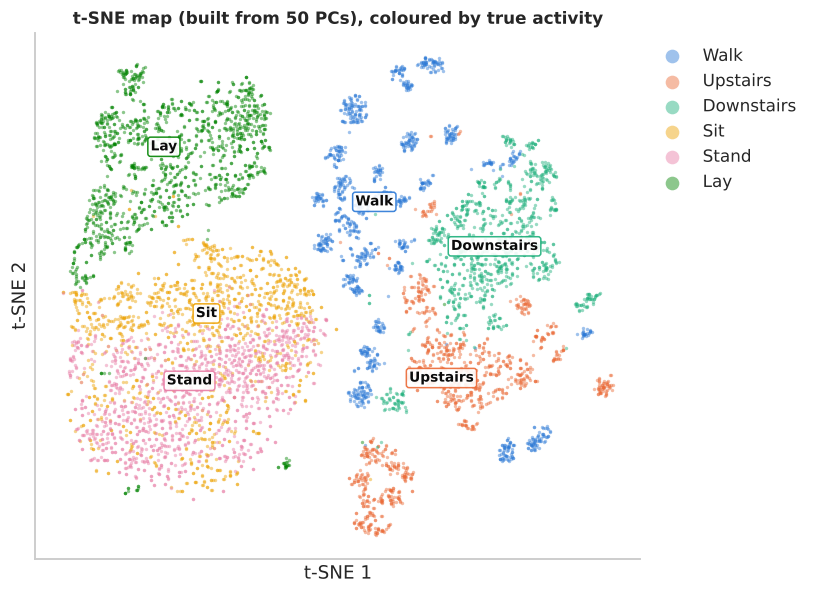

In [56]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RNG)
T = tsne.fit_transform(Z50)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
scatter_by_activity(ax, T[:, 0], T[:, 1], "t-SNE map (built from 50 PCs), coloured by true activity", "t-SNE 1", "t-SNE 2")
ax.legend(markerscale=4, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**What this shows**
- t-SNE tells the **same story** as PCA and the neighbour analysis, which makes us more confident:
  - moving and still windows form two separate areas;
  - lying forms its own clear island;
  - walking, upstairs and downstairs form neighbouring islands that touch;
  - sitting and standing are still partly mixed.
- **Walking breaks into many small, tight islands.** This fits the 94% same-person result in 2.8: each island is most likely one person's walking. That is structure **finer than the six labels**. Upstairs also shows a few islands; downstairs is a looser cloud.
- **Sitting and standing form one big shared area.** This is the same overlap found in 2.7.
- Lying sits next to them but mostly in its own area.

Because two very different methods (linear PCA and non-linear t-SNE) agree, the main structure is unlikely to be a side effect of one method.

##### 2.10 Summary of Task 2: evidence and hypotheses

**How the movement data are organised (evidence)**

| Finding | Evidence |
|---|---|
| The strongest structure is **moving vs still** | PC1 (intensity, ≈ 51% of variance) has two humps with a gap; `PC1 > 0` matches the families for 99.8% of windows; Hopkins ≈ 0.94 |
| The structure is a **hierarchy**, not six equal groups | Distances between families are about 2.5–10× larger than distances inside a family (dendrogram) |
| **Lying** is separated by **posture**, not movement | It separates from sitting and standing only along PC3 (gravity / orientation) |
| **Sitting and standing overlap** heavily | 19–26% of their neighbours are the other activity |
| **Walking, upstairs and downstairs** are neighbours with soft borders | 91–98% same-activity neighbours; small mixing only among themselves |
| **Downstairs** is the most varied activity | Largest spread on PC1 and in 50-PC space |
| Activities contain **person-specific sub-regions** | Same-person neighbours: walking ≈ 94%, still activities ≈ 25–49% (chance ≈ 5%); walking splits into many small t-SNE islands |
| A 2-D PCA plot **understates separation** | Same-activity neighbours: 51% in 2 PCs vs 89% in 50 PCs |

**Hypotheses to test with real clustering (RQ1) and anomaly detection (RQ2, RQ3)**
- **H1.** Clustering will find **2 groups (moving vs still) most clearly**. A choice of k = 2 may score better on internal measures such as silhouette than k = 6.
- **H2.** If we ask for 6 clusters, **sitting and standing will often be merged** or split in a way that does not follow the labels, while lying will form its own cluster.
- **H3.** Because the moving family is **long and spread out** instead of round, a method that allows stretched shapes (such as **GMM**) may fit it better than **K-means**, which assumes round groups of similar size.
- **H4.** Anomaly detectors will flag **more downstairs windows**, partly because downstairs is naturally more varied, not only because those windows are truly strange (link to Task 4 and RQ2).
- **H5.** Some "anomalies" may really be **person-specific movement styles**, especially for walking (link to Task 5 and RQ3). Clustering with many clusters may split walking **by person** instead of by activity.

**Limitations**
- Only the training set (21 people) was used. The test people may look slightly different.
- PCA finds straight-line structure only. t-SNE helps here, but t-SNE maps are not reliable for distances between groups.
- The features were pre-scaled to [-1, 1] by the dataset authors and then standardised again by us, so each feature has equal weight. Redundant features (Task 1) still give extra weight to the ideas they repeat.
- Windows overlap by 50% in time, so near neighbours can be near-copies. This may make the person effect and the cluster tendency look stronger than they really are.
- All the label comparisons above are **interpretation only**. Visual groupings are exploratory evidence, not validated clusters.

### Task 3 — Physical interpretation of movement patterns
Objective: Understand which sensor characteristics distinguish or connect different movement patterns.

**Member**: Youssef

What needs to be done:
1. Explore acceleration, gyroscope and gravity-related feature distributions.
2. Compare time-domain and frequency-domain characteristics.
3. Identify which physical features differ most between activity groups.
4. Examine which activities share similar physical characteristics.
5. Investigate whether movement differences are associated with motion intensity, periodicity or orientation.
Expected output: Interpretable physical explanations for similarities and differences between movement patterns.

*Code by Youssef (from main).*

Training observations: 7,352 | Physical features: 561 | Modelling features: 561
Training set only; label names are used for interpretation, not for fitting anomaly models.

=== EDA TASK 3: PHYSICAL MOVEMENT PATTERNS ===
Physical feature availability: 7 of 7


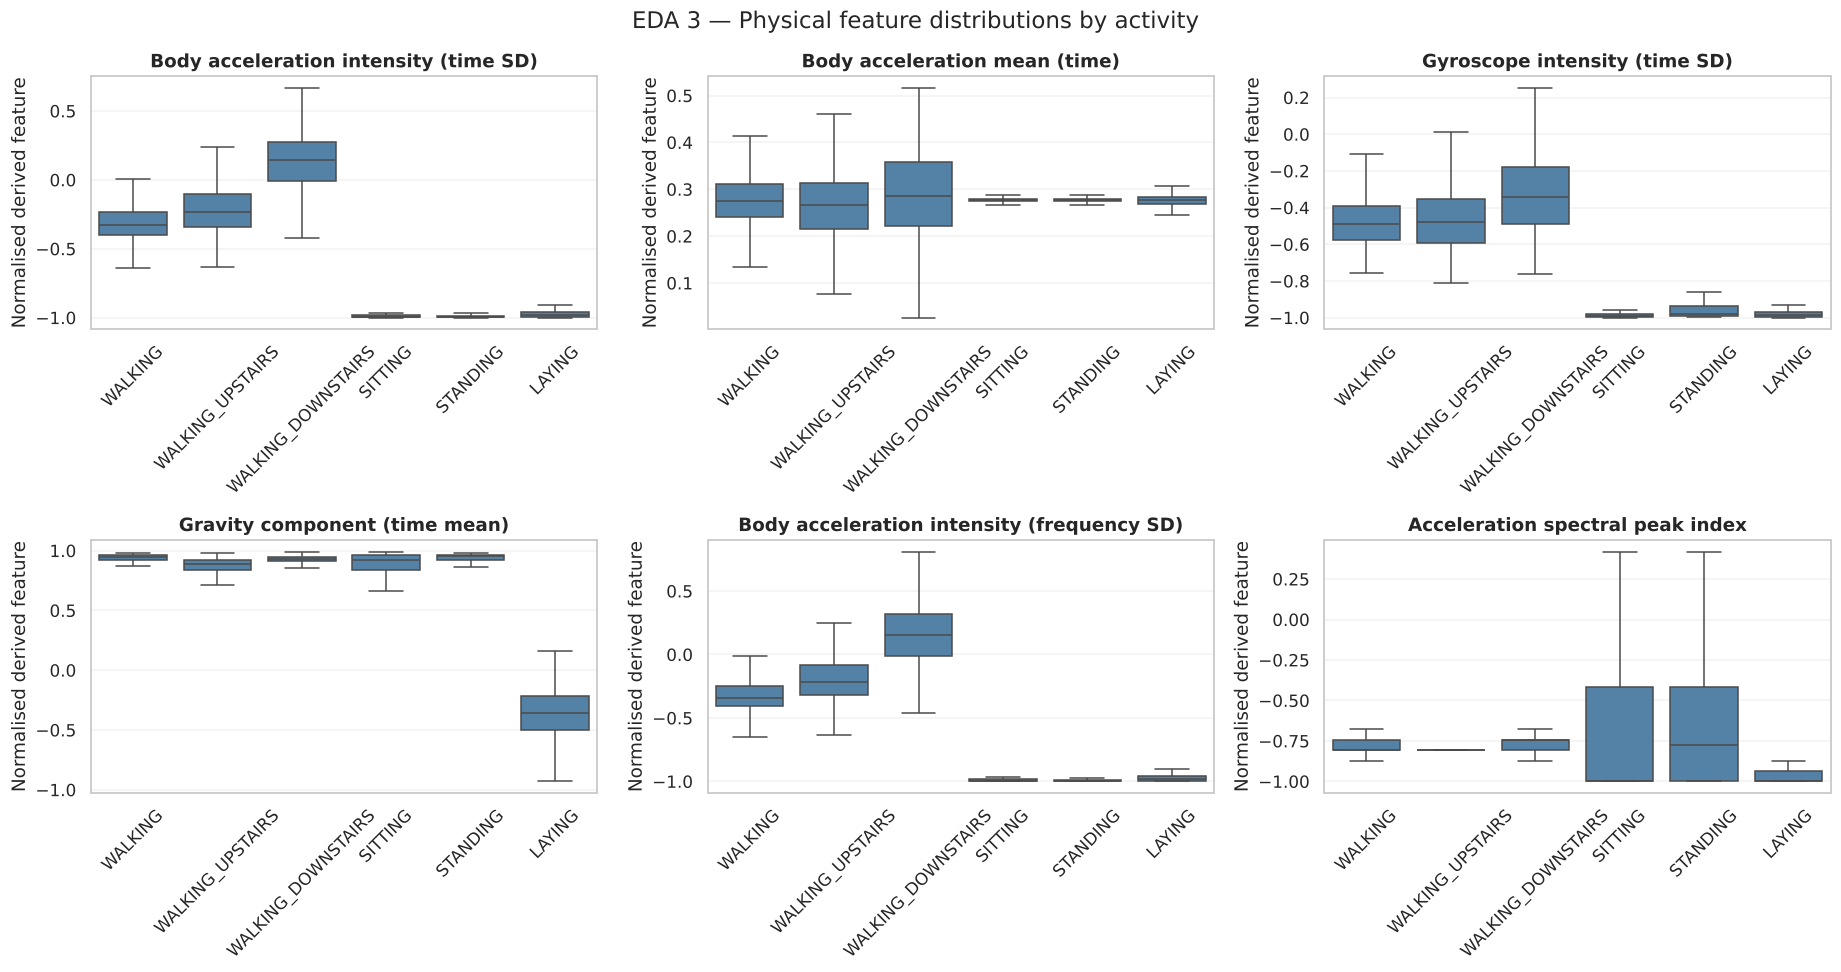


Top 12 features separating the six activities:
                      feature  eta_squared       sensor    domain
     fBodyAccJerk-entropy()-X        0.962 Acceleration Frequency
         tGravityAcc-mean()-X        0.952      Gravity      Time
          tGravityAcc-min()-X        0.950      Gravity      Time
     fBodyAccJerk-entropy()-Y        0.950 Acceleration Frequency
          tGravityAcc-max()-X        0.948      Gravity      Time
       tGravityAcc-energy()-X        0.946      Gravity      Time
fBodyBodyAccJerkMag-entropy()        0.941 Acceleration Frequency
    tBodyAccJerkMag-entropy()        0.941 Acceleration      Time
         fBodyAcc-entropy()-X        0.940 Acceleration Frequency
     tBodyAccJerk-entropy()-X        0.938 Acceleration      Time
             tBodyAcc-max()-X        0.932 Acceleration      Time
     fBodyAccJerk-entropy()-Z        0.928 Acceleration Frequency

Average separability by sensor and domain:
                         mean  count
sensor       

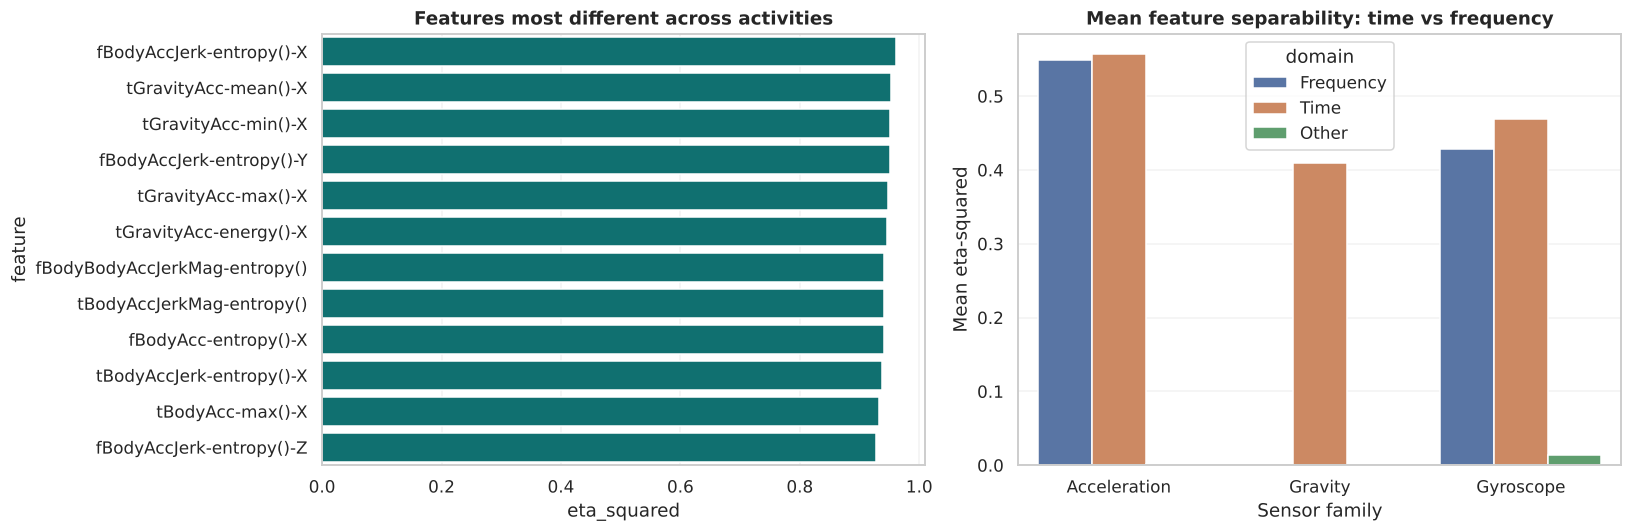


Closest activity pairs in standardised physical feature centroids:
  SITTING + STANDING: centroid distance 3.96
  SITTING + LAYING: centroid distance 7.62
  STANDING + LAYING: centroid distance 9.51
  WALKING + WALKING_UPSTAIRS: centroid distance 10.63
  WALKING + WALKING_DOWNSTAIRS: centroid distance 11.91


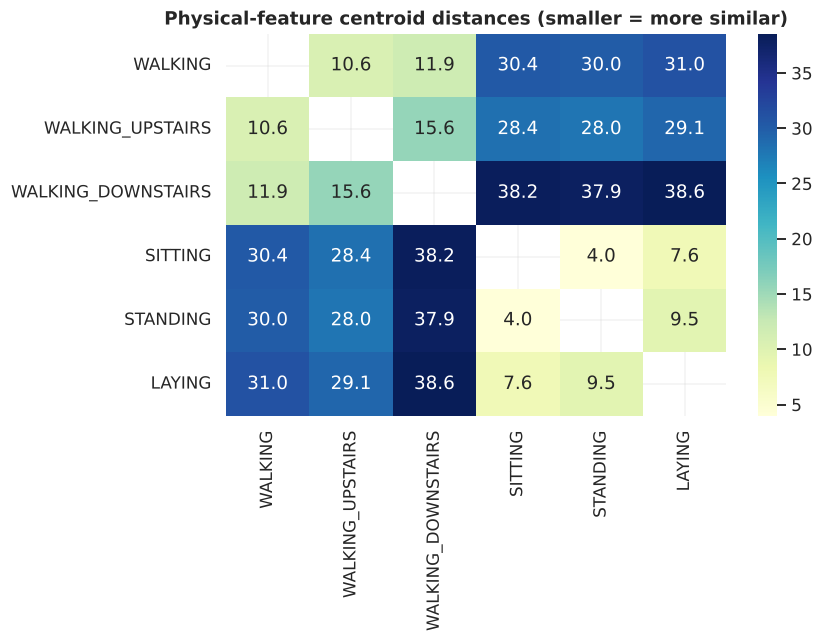


Motion intensity, spectral peak index, and gravity/orientation-related means:
                    tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyGyro-std()-X  tBodyGyro-std()-Y  tBodyGyro-std()-Z  fBodyAcc-maxInds-X  fBodyAcc-maxInds-Y  fBodyAcc-maxInds-Z  tGravityAcc-mean()-X  tGravityAcc-mean()-Y  tGravityAcc-mean()-Z
activity                                                                                                                                                                                                                                                       
WALKING                       -0.313            -0.020            -0.246             -0.461             -0.326             -0.321              -0.773              -0.693              -0.782                 0.933                -0.200                -0.065
WALKING_UPSTAIRS              -0.221            -0.000            -0.140             -0.461             -0.322             -0.238              -0.797    

In [57]:
# ================================================================
# YOUSSEF — EDA TASK 3: PHYSICAL INTERPRETATION
# Requires train_df from the notebook's data-loading cells.
# ================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
ACTIVITY_NAMES = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}
ORDER = list(ACTIVITY_NAMES.values())

if "train_df" not in globals():
    raise RuntimeError(
        "Run the earlier notebook cells that create train_df first."
    )

if not {"activity_id", "subject_id"}.issubset(train_df.columns):
    raise ValueError(
        "train_df must contain activity_id and subject_id."
    )

d = train_df.copy().reset_index(drop=True)
d["activity"] = d["activity_id"].map(ACTIVITY_NAMES)

if d["activity"].isna().any():
    raise ValueError("Unexpected activity IDs found.")

feature_cols = [
    c for c in d.columns
    if c not in ("activity", "activity_id", "subject_id")
]

X = d[feature_cols].apply(pd.to_numeric, errors="raise")

# Remove constant features only for multivariate modelling.
model_cols = X.columns[X.std(ddof=0) > 1e-12]
Z = StandardScaler().fit_transform(X[model_cols])

print(
    f"Training observations: {len(d):,} | "
    f"Physical features: {len(feature_cols)} | "
    f"Modelling features: {len(model_cols)}"
)
print(
    "Training set only; label names are used for interpretation, "
    "not for fitting anomaly models.\n"
)

# ================================================================
# EDA TASK 3: PHYSICAL FEATURE INTERPRETATION
# ================================================================

# Dataset features are mostly normalised, not raw physical units.
physical_features = {
    "Body acceleration intensity (time SD)": "tBodyAcc-std()-X",
    "Body acceleration mean (time)": "tBodyAcc-mean()-X",
    "Gyroscope intensity (time SD)": "tBodyGyro-std()-X",
    "Gravity component (time mean)": "tGravityAcc-mean()-X",
    "Body acceleration intensity (frequency SD)": "fBodyAcc-std()-X",
    "Acceleration spectral peak index": "fBodyAcc-maxInds-X",
    "Gyroscope energy (frequency)": "fBodyGyro-energy()-X"
}

chosen = {
    label: col
    for label, col in physical_features.items()
    if col in X.columns
}

if len(chosen) < 4:
    raise ValueError(
        "Expected UCI HAR physical feature names were not found."
    )

print("=== EDA TASK 3: PHYSICAL MOVEMENT PATTERNS ===")
print(
    "Physical feature availability:",
    len(chosen),
    "of",
    len(physical_features)
)

# ------------------------------------------------
# 1. Physical feature distributions by activity
# ------------------------------------------------

view = list(chosen.items())[:6]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, (label, col) in zip(axes.flat, view):
    sns.boxplot(
        data=d,
        x="activity",
        y=col,
        order=ORDER,
        ax=ax,
        showfliers=False,
        color="steelblue"
    )
    ax.set_title(label)
    ax.set(
        xlabel="",
        ylabel="Normalised derived feature"
    )
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flat[len(view):]:
    ax.axis("off")

fig.suptitle(
    "EDA 3 — Physical feature distributions by activity",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 2. Feature separability by sensor and domain
# ------------------------------------------------

def eta_squared(frame, labels):
    grand_mean = frame.mean(axis=0)
    total_ss = ((frame - grand_mean) ** 2).sum(axis=0)

    between_ss = pd.Series(
        0.0,
        index=frame.columns
    )

    for activity in ORDER:
        mask = labels.eq(activity)

        if mask.sum():
            between_ss += (
                mask.sum()
                * (frame.loc[mask].mean(axis=0) - grand_mean) ** 2
            )

    return (
        between_ss / total_ss.replace(0, np.nan)
    ).fillna(0)


eta = eta_squared(
    X,
    d["activity"]
).sort_values(ascending=False)

feature_summary = pd.DataFrame({
    "feature": eta.index,
    "eta_squared": eta.values
})


def family(name):
    if "GravityAcc" in name:
        return "Gravity"
    if "Gyro" in name:
        return "Gyroscope"
    if "Acc" in name:
        return "Acceleration"
    return "Other"


feature_summary["sensor"] = (
    feature_summary["feature"].map(family)
)

feature_summary["domain"] = (
    feature_summary["feature"]
    .str[0]
    .map({"t": "Time", "f": "Frequency"})
    .fillna("Other")
)

print("\nTop 12 features separating the six activities:")
print(
    feature_summary.head(12).to_string(
        index=False,
        float_format=lambda v: f"{v:.3f}"
    )
)

print("\nAverage separability by sensor and domain:")
print(
    feature_summary
    .groupby(["sensor", "domain"])["eta_squared"]
    .agg(["mean", "count"])
    .round(3)
    .to_string()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=feature_summary.head(12),
    y="feature",
    x="eta_squared",
    ax=axes[0],
    color="teal"
)

axes[0].set_title(
    "Features most different across activities"
)

sns.barplot(
    data=feature_summary[
        feature_summary["sensor"] != "Other"
    ],
    x="sensor",
    y="eta_squared",
    hue="domain",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title(
    "Mean feature separability: time vs frequency"
)
axes[1].set(
    xlabel="Sensor family",
    ylabel="Mean eta-squared"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 3. Physical similarity between activities
# FIXED: No read-only NumPy array modification
# ------------------------------------------------

physical_cols = [
    c for c in X.columns
    if ("Acc" in c or "Gyro" in c)
    and (c.startswith("t") or c.startswith("f"))
]

P = StandardScaler().fit_transform(
    X[physical_cols]
)

centroids = (
    pd.DataFrame(P, columns=physical_cols)
    .assign(activity=d["activity"])
    .groupby("activity")
    .mean()
    .reindex(ORDER)
)

distances = pd.DataFrame(
    pairwise_distances(
        centroids,
        metric="euclidean"
    ),
    index=ORDER,
    columns=ORDER
)

# FIX: Use pandas .loc to safely update the diagonal.
# This avoids the "underlying array is read-only" error.
for activity in ORDER:
    distances.loc[activity, activity] = np.nan

nearest_pairs = sorted(
    (distances.loc[a, b], a, b)
    for i, a in enumerate(ORDER)
    for b in ORDER[i + 1:]
)

print(
    "\nClosest activity pairs in standardised "
    "physical feature centroids:"
)

for distance, a, b in nearest_pairs[:5]:
    print(
        f"  {a} + {b}: "
        f"centroid distance {distance:.2f}"
    )

plt.figure(figsize=(8, 6))

sns.heatmap(
    distances,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title(
    "Physical-feature centroid distances "
    "(smaller = more similar)"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 4. Motion intensity, periodicity and orientation
# ------------------------------------------------

proxy_cols = [
    c for c in [
        "tBodyAcc-std()-X",
        "tBodyAcc-std()-Y",
        "tBodyAcc-std()-Z",
        "tBodyGyro-std()-X",
        "tBodyGyro-std()-Y",
        "tBodyGyro-std()-Z",
        "fBodyAcc-maxInds-X",
        "fBodyAcc-maxInds-Y",
        "fBodyAcc-maxInds-Z",
        "tGravityAcc-mean()-X",
        "tGravityAcc-mean()-Y",
        "tGravityAcc-mean()-Z"
    ]
    if c in X
]

proxy_means = (
    d.groupby("activity")[proxy_cols]
    .mean()
    .reindex(ORDER)
)

print(
    "\nMotion intensity, spectral peak index, "
    "and gravity/orientation-related means:"
)

print(
    proxy_means.round(3).to_string()
)

print(
    "\nNOTE: Gravity axis means suggest phone orientation, "
    "not a calibrated body pose."
)
print(
    "A spectral peak index alone does not establish "
    "motion periodicity.\n"
)


#### Preliminary anomaly scores (Youssef — RQ2 groundwork)
Isolation Forest, 10-NN and K-means boundary scores on 30 principal components. Task 4 reuses `d`, `Q`, `X` and the `if_top5` / `knn_top5` flags from this cell, so it stays here for now and moves to RQ2 when the research questions are combined.

=== RESEARCH QUESTION 2: VARIABILITY AND ANOMALY PROFILES ===


PCA variance explained by 30 components: 81.8%



Activity-level findings (5% expected if unusualness were uniform):
                       n  dispersion  if_mean  if_top5_pct  knn_top5_pct  boundary_margin  IF_enrichment_vs_5pct
activity                                                                                                        
WALKING             1226       14.01     0.43         6.93          4.81             4.34                   1.39
WALKING_UPSTAIRS    1073       13.41     0.44         6.99          4.66             6.36                   1.40
WALKING_DOWNSTAIRS   986       17.58     0.46        16.13         21.10             5.34                   3.23
SITTING             1286        9.31     0.39         1.01          1.01             3.33                   0.20
STANDING            1374        8.54     0.39         0.22          0.15             4.52                   0.04
LAYING              1407       10.62     0.41         2.35          2.56             3.84                   0.47


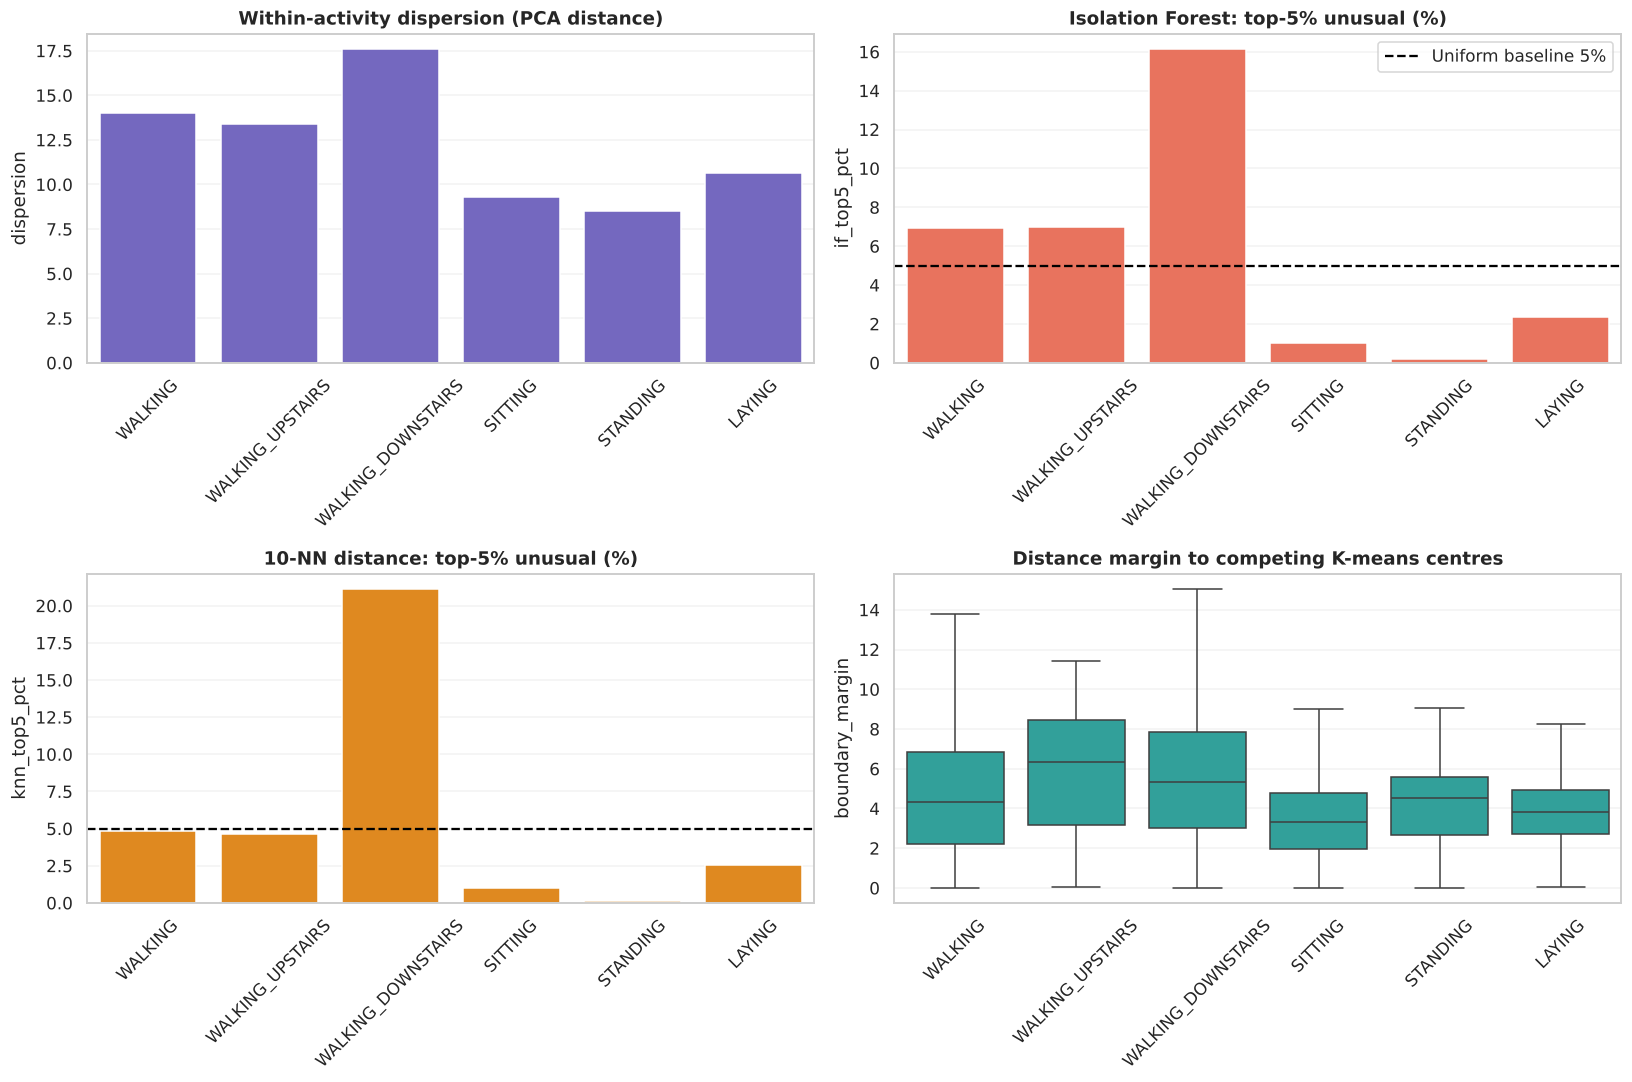


Across six activities: dispersion vs Isolation Forest top-5% rate:
Spearman rho=0.94, p=0.005
Agreement across methods: 279 windows appear in both top-5% shortlists

Boundary/density/dispersion comparison:
           median_boundary_margin  median_knn_distance  median_within_activity_dispersion
Other 95%                   4.260                7.461                             10.400
IF top 5%                   5.136               16.522                             27.981


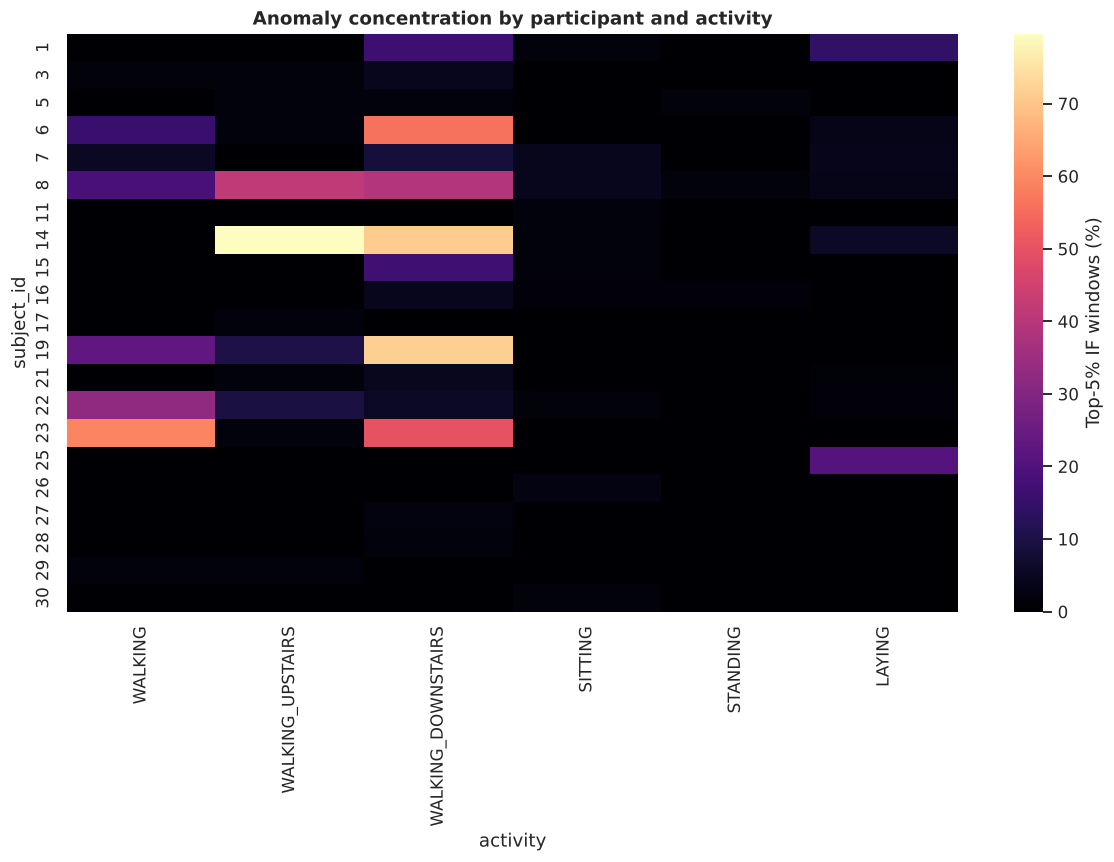


=== INTERPRETATION FOR REPORT ===
Largest within-activity dispersion: WALKING_DOWNSTAIRS.
Highest global Isolation Forest unusualness rate: WALKING_DOWNSTAIRS (16.1%; 3.2x uniform baseline).
Lowest unusualness rate: STANDING (0.2%).
Closest physical movement profiles: SITTING and STANDING.

Caution: These are unsupervised unusualness scores, NOT verified abnormal motions.
Overlapping 2.56-second windows, subject differences, correlated features and cluster geometry may influence rankings.
No transition labels are supplied.
For the shared RQ2 report, compare these patterns with the group's other clustering results.
Investigate flagged windows before attributing them to actual physical irregularities.

=== YOUSSEF ANALYSIS COMPLETED ===


In [58]:
# ================================================================
# RESEARCH QUESTION 2: MOVEMENT VARIABILITY AND ANOMALIES
# ================================================================

print(
    "=== RESEARCH QUESTION 2: "
    "VARIABILITY AND ANOMALY PROFILES ==="
)

# ------------------------------------------------
# 5. Dimensionality reduction using PCA
# ------------------------------------------------

n_components = min(
    30,
    Z.shape[1],
    Z.shape[0] - 1
)

pca = PCA(
    n_components=n_components,
    random_state=RANDOM_STATE
)

Q = pca.fit_transform(Z)

print(
    f"PCA variance explained by {n_components} "
    f"components: "
    f"{pca.explained_variance_ratio_.sum():.1%}"
)

# ------------------------------------------------
# 6. Isolation Forest anomaly detection
# ------------------------------------------------

iso = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

iso.fit(Q)

# Larger scores indicate more unusual observations.
d["if_score"] = -iso.score_samples(Q)

# ------------------------------------------------
# 7. K-nearest neighbours anomaly scores
# ------------------------------------------------

nn = NearestNeighbors(
    n_neighbors=11,
    n_jobs=-1
).fit(Q)

knn_dist, _ = nn.kneighbors(Q)

# Distance to the tenth other nearest neighbour.
d["knn_score"] = knn_dist[:, 10]

# ------------------------------------------------
# 8. K-means cluster boundary analysis
# ------------------------------------------------

km = KMeans(
    n_clusters=6,
    n_init=10,
    random_state=RANDOM_STATE
).fit(Q)

cluster_d = km.transform(Q)

# Sort each observation's distances to cluster centres.
cluster_d.sort(axis=1)

# Small margins indicate competing nearby clusters.
d["boundary_margin"] = (
    cluster_d[:, 1] - cluster_d[:, 0]
)

# ------------------------------------------------
# 9. Within-activity variability
# ------------------------------------------------

# Labels are used only to describe activity dispersion.
act_centres = {
    a: Q[
        d["activity"].eq(a).to_numpy()
    ].mean(axis=0)
    for a in ORDER
}

d["within_activity_distance"] = np.array([
    np.linalg.norm(
        point - act_centres[act]
    )
    for point, act in zip(Q, d["activity"])
])

# ------------------------------------------------
# 10. Identify the top 5% most unusual observations
# ------------------------------------------------

threshold_if = d["if_score"].quantile(0.95)
threshold_knn = d["knn_score"].quantile(0.95)

d["if_top5"] = (
    d["if_score"] >= threshold_if
)

d["knn_top5"] = (
    d["knn_score"] >= threshold_knn
)

results = (
    d.groupby("activity", observed=True)
    .agg(
        n=("if_score", "size"),
        dispersion=(
            "within_activity_distance", "mean"
        ),
        if_mean=("if_score", "mean"),
        if_top5_pct=(
            "if_top5",
            lambda x: x.mean() * 100
        ),
        knn_top5_pct=(
            "knn_top5",
            lambda x: x.mean() * 100
        ),
        boundary_margin=(
            "boundary_margin", "median"
        )
    )
    .reindex(ORDER)
)

results["IF_enrichment_vs_5pct"] = (
    results["if_top5_pct"] / 5.0
)

print(
    "\nActivity-level findings "
    "(5% expected if unusualness were uniform):"
)

print(
    results.round(2).to_string()
)

# ------------------------------------------------
# 11. Variability and anomaly visualisations
# ------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

sns.barplot(
    x=results.index,
    y=results["dispersion"],
    ax=axes[0, 0],
    color="slateblue"
)

axes[0, 0].set_title(
    "Within-activity dispersion (PCA distance)"
)

sns.barplot(
    x=results.index,
    y=results["if_top5_pct"],
    ax=axes[0, 1],
    color="tomato"
)

axes[0, 1].axhline(
    5,
    ls="--",
    color="black",
    label="Uniform baseline 5%"
)

axes[0, 1].legend()

axes[0, 1].set_title(
    "Isolation Forest: top-5% unusual (%)"
)

sns.barplot(
    x=results.index,
    y=results["knn_top5_pct"],
    ax=axes[1, 0],
    color="darkorange"
)

axes[1, 0].axhline(
    5,
    ls="--",
    color="black"
)

axes[1, 0].set_title(
    "10-NN distance: top-5% unusual (%)"
)

sns.boxplot(
    data=d,
    x="activity",
    y="boundary_margin",
    order=ORDER,
    showfliers=False,
    ax=axes[1, 1],
    color="lightseagreen"
)

axes[1, 1].set_title(
    "Distance margin to competing K-means centres"
)

for ax in axes.flat:
    ax.tick_params(
        axis="x",
        rotation=45
    )
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 12. Correlation between variability and anomalies
# ------------------------------------------------

rho, pvalue = spearmanr(
    results["dispersion"],
    results["if_top5_pct"]
)

print(
    "\nAcross six activities: dispersion vs "
    "Isolation Forest top-5% rate:"
)
print(
    f"Spearman rho={rho:.2f}, p={pvalue:.3f}"
)

score_agreement = (
    d["if_top5"] & d["knn_top5"]
).sum()

print(
    f"Agreement across methods: {score_agreement} "
    "windows appear in both top-5% shortlists"
)

# ------------------------------------------------
# 13. Anomalies and cluster boundaries
# ------------------------------------------------

summary = (
    d.groupby("if_top5")
    .agg(
        median_boundary_margin=(
            "boundary_margin", "median"
        ),
        median_knn_distance=(
            "knn_score", "median"
        ),
        median_within_activity_dispersion=(
            "within_activity_distance", "median"
        )
    )
)

summary.index = [
    "Other 95%",
    "IF top 5%"
]

print(
    "\nBoundary/density/dispersion comparison:"
)

print(
    summary.round(3).to_string()
)

# ------------------------------------------------
# 14. Anomaly rates by participant and activity
# ------------------------------------------------

subject_rates = (
    d.pivot_table(
        index="subject_id",
        columns="activity",
        values="if_top5",
        aggfunc="mean"
    ) * 100
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    subject_rates.reindex(columns=ORDER),
    cmap="magma",
    vmin=0,
    cbar_kws={
        "label": "Top-5% IF windows (%)"
    }
)

plt.title(
    "Anomaly concentration by participant and activity"
)

plt.tight_layout()
plt.show()

# ================================================================
# 15. AUTOMATIC INTERPRETATION FOR THE REPORT
# ================================================================

most_variable = (
    results["dispersion"].idxmax()
)

most_flagged = (
    results["if_top5_pct"].idxmax()
)

least_flagged = (
    results["if_top5_pct"].idxmin()
)

print("\n=== INTERPRETATION FOR REPORT ===")

print(
    f"Largest within-activity dispersion: "
    f"{most_variable}."
)

print(
    f"Highest global Isolation Forest unusualness rate: "
    f"{most_flagged} "
    f"({results.loc[most_flagged, 'if_top5_pct']:.1f}%; "
    f"{results.loc[most_flagged, 'IF_enrichment_vs_5pct']:.1f}x "
    f"uniform baseline)."
)

print(
    f"Lowest unusualness rate: {least_flagged} "
    f"({results.loc[least_flagged, 'if_top5_pct']:.1f}%)."
)

print(
    f"Closest physical movement profiles: "
    f"{nearest_pairs[0][1]} and "
    f"{nearest_pairs[0][2]}."
)

print(
    "\nCaution: These are unsupervised unusualness scores, "
    "NOT verified abnormal motions."
)

print(
    "Overlapping 2.56-second windows, subject differences, "
    "correlated features and cluster geometry may "
    "influence rankings."
)

print(
    "No transition labels are supplied."
)

print(
    "For the shared RQ2 report, compare these patterns "
    "with the group's other clustering results."
)

print(
    "Investigate flagged windows before attributing "
    "them to actual physical irregularities."
)

print(
    "\n=== YOUSSEF ANALYSIS COMPLETED ==="
)


### Task 4 — Movement variability and diversity
Objective: Determine whether some types of movement exhibit greater internal variation than others.

What needs to be done:
1. Compare within-activity feature variance and multivariate dispersion.
2. Examine local neighbourhood distances and density differences.
3. Investigate whether some activities contain several distinct movement patterns.
4. Determine whether activity variability is distributed across participants or concentrated in a few individuals.
5. Investigate why walking downstairs is disproportionately represented among the existing high-scoring unusual observations.
Expected output: Evidence identifying which movements are more heterogeneous and potential explanations for their apparent unusualness.

*Code by Subhashini (from DSA8003_Group_4_Analysis_Task4_Executed.ipynb).*

TASK 4 — Movement variability and diversity
Analysing 7,352 training windows, 561 features, and 21 participants.
The activity labels are used for grouping and interpretation only.

1) Within-activity feature variance (highest first):


,mean_feature_variance,median_feature_variance,n_windows
activity,,,
WALKING_DOWNSTAIRS,0.0519,0.0472,986
WALKING_UPSTAIRS,0.0383,0.0275,1073
LAYING,0.0363,0.0064,1407
WALKING,0.0362,0.0313,1226
SITTING,0.0291,0.0029,1286
STANDING,0.0254,0.0021,1374


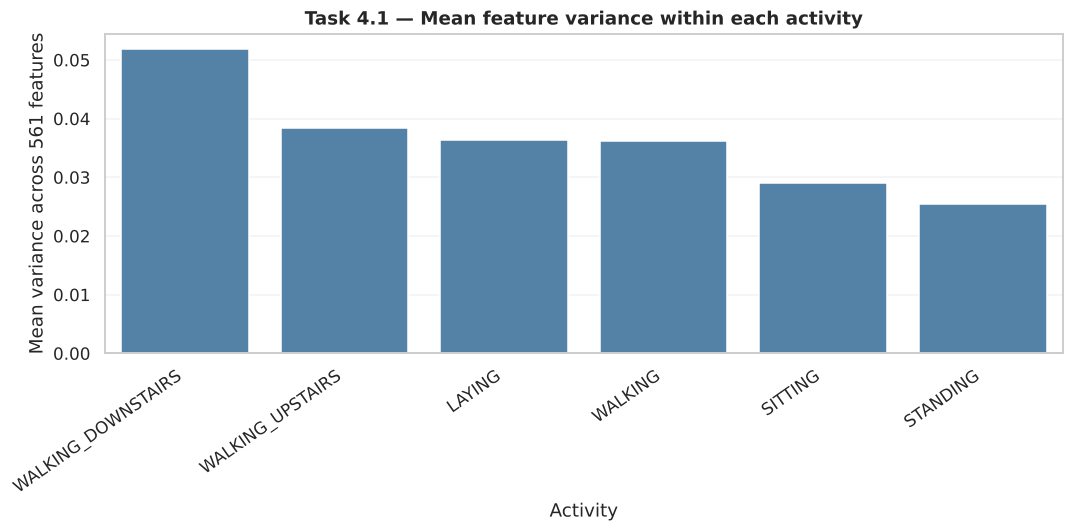


Top 8 high-variance features within each activity:

WALKING


,variance
"angle(tBodyGyroMean,gravityMean)",0.4402
"tGravityAcc-correlation()-X,Z",0.3525
"tGravityAcc-correlation()-Y,Z",0.3355
"tGravityAcc-correlation()-X,Y",0.3221
"angle(tBodyAccJerkMean),gravityMean)",0.2893
"angle(tBodyGyroJerkMean,gravityMean)",0.2470
"angle(tBodyAccMean,gravity)",0.2102
fBodyBodyAccJerkMag-kurtosis(),0.1591



WALKING_UPSTAIRS


,variance
"angle(tBodyGyroMean,gravityMean)",0.7041
"tGravityAcc-correlation()-X,Z",0.3958
"tGravityAcc-correlation()-Y,Z",0.3693
"angle(tBodyAccJerkMean),gravityMean)",0.3388
"angle(tBodyGyroJerkMean,gravityMean)",0.2968
tBodyGyro-entropy()-X,0.2687
"tGravityAcc-correlation()-X,Y",0.2509
fBodyGyro-kurtosis()-Y,0.2067



WALKING_DOWNSTAIRS


,variance
"angle(tBodyGyroMean,gravityMean)",0.6991
"angle(tBodyAccJerkMean),gravityMean)",0.3997
"tGravityAcc-correlation()-X,Z",0.3704
"tGravityAcc-correlation()-Y,Z",0.3364
"tGravityAcc-correlation()-X,Y",0.3146
"angle(tBodyGyroJerkMean,gravityMean)",0.2839
"angle(tBodyAccMean,gravity)",0.2669
tBodyGyro-entropy()-X,0.2056


... (4 outputs left out)


LAYING


,variance
"tGravityAcc-correlation()-X,Y",0.5634
"tGravityAcc-correlation()-X,Z",0.4797
"tGravityAcc-correlation()-Y,Z",0.4578
fBodyAcc-kurtosis()-X,0.3465
tGravityAcc-energy()-Z,0.3145
fBodyAcc-kurtosis()-Y,0.2909
tGravityAcc-energy()-Y,0.2760
tBodyGyro-entropy()-Z,0.2719



2) Multivariate dispersion in PCA space (highest mean first):


,mean,median,std,count
activity,,,,
WALKING_DOWNSTAIRS,17.578,14.880,9.582,986
WALKING,14.014,12.371,5.598,1226
WALKING_UPSTAIRS,13.413,12.049,4.883,1073
LAYING,10.624,9.563,5.066,1407
SITTING,9.312,8.274,3.947,1286
STANDING,8.536,7.929,2.886,1374


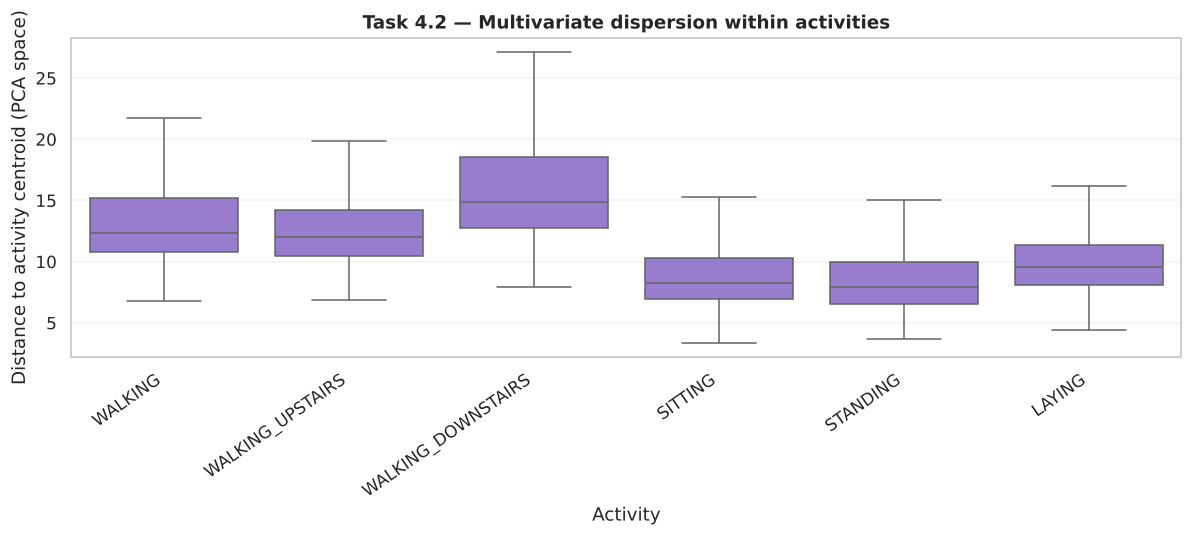


3) Neighbourhood distances (larger distance = locally sparser):


,mean_global_5nn,median_global_5nn,mean_within_activity_5nn,median_within_activity_5nn,n_windows
activity,,,,,
WALKING_DOWNSTAIRS,10.898,10.020,10.956,10.060,986
WALKING_UPSTAIRS,8.362,7.940,8.398,7.956,1073
WALKING,7.790,7.351,7.807,7.351,1226
LAYING,5.984,5.383,6.002,5.389,1407
SITTING,5.616,5.195,5.766,5.306,1286
STANDING,5.426,5.097,5.521,5.188,1374


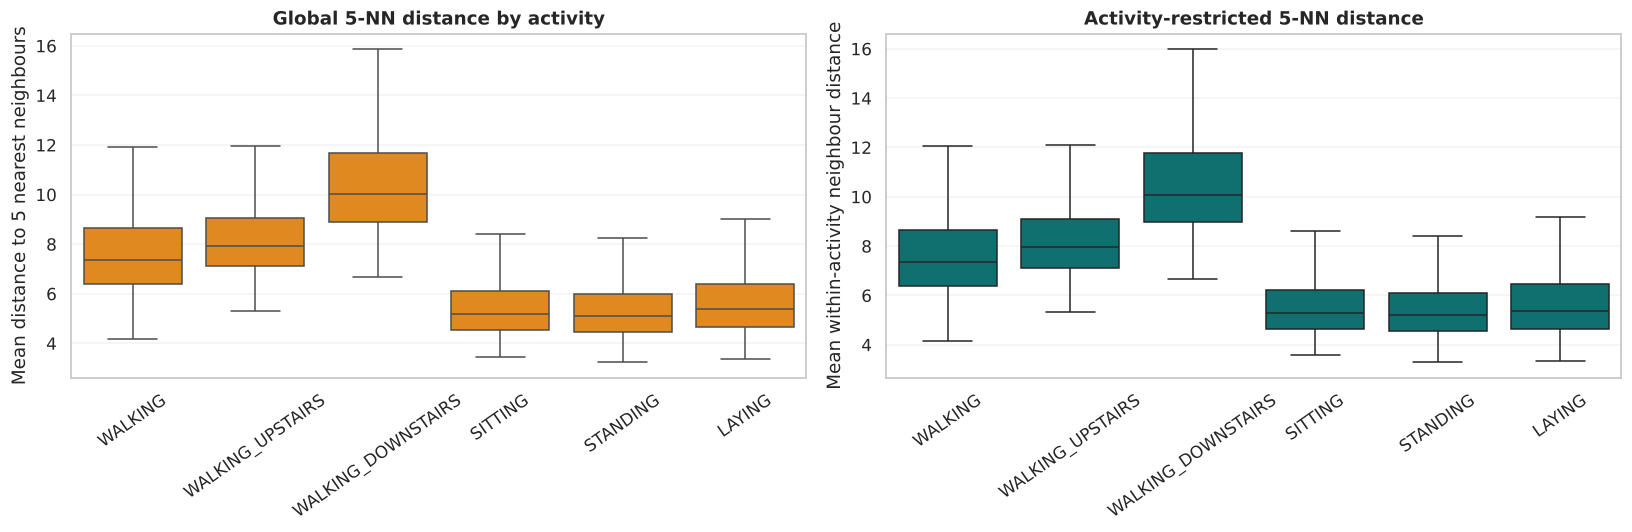


4) Within-activity clustering check (larger silhouette suggests clearer subgroups):


k,2,3
activity,,
WALKING,0.300,0.206
WALKING_UPSTAIRS,0.286,0.223
WALKING_DOWNSTAIRS,0.423,0.185
SITTING,0.310,0.218
STANDING,0.249,0.151
LAYING,0.332,0.218


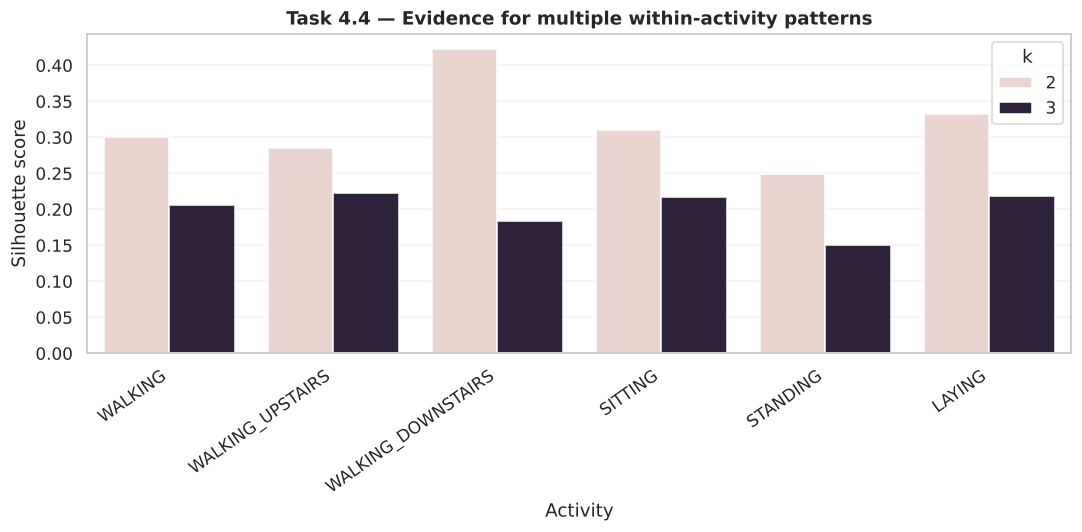


5) Participant contribution to variability by activity:


,mean_participant_dispersion,sd_between_participants,min_participant_dispersion,max_participant_dispersion,participants
activity,,,,,
WALKING_DOWNSTAIRS,17.709,7.283,12.689,42.374,21
WALKING,14.148,4.477,10.027,26.309,21
WALKING_UPSTAIRS,13.515,3.984,9.874,26.158,21
LAYING,10.729,2.187,8.833,18.377,21
SITTING,9.412,0.932,7.889,11.240,21
STANDING,8.583,0.743,7.429,10.610,21


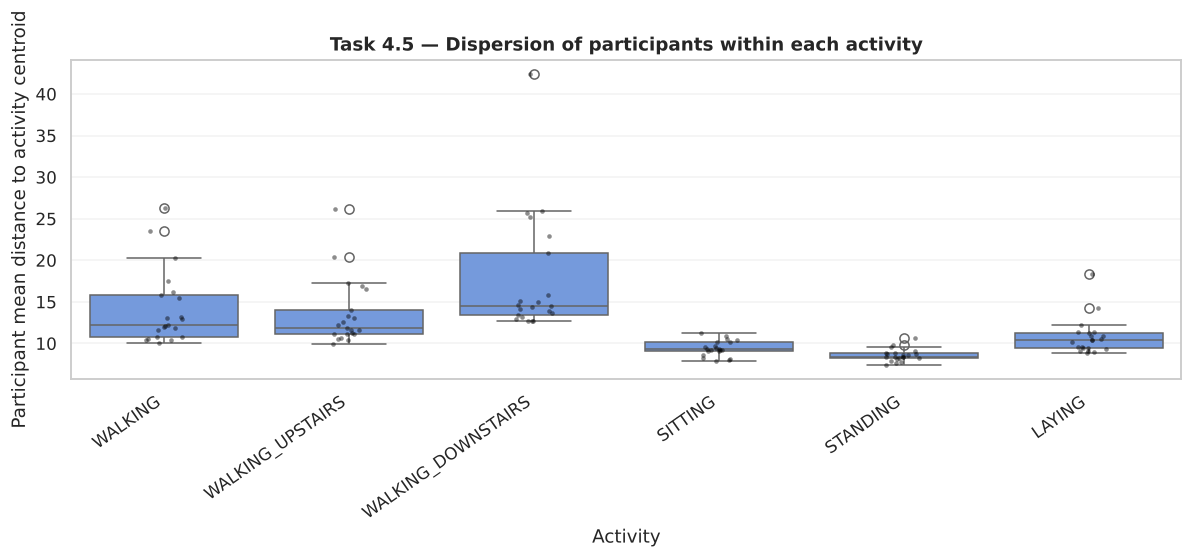


Between-participant share of activity dispersion (approximate variance decomposition):


,between_subject_share_of_dispersion,within_subject_share_approx
activity,,
WALKING,0.615,0.385
WALKING_UPSTAIRS,0.565,0.435
WALKING_DOWNSTAIRS,0.515,0.485
SITTING,0.117,0.883
STANDING,0.157,0.843
LAYING,0.246,0.754



6) WALKING_DOWNSTAIRS representation among anomaly shortlists:


,method,all_flagged_n,downstairs_flagged_n,downstairs_share_of_flagged_pct,downstairs_baseline_share_pct,enrichment_vs_activity_prevalence,downstairs_within_activity_flag_rate_pct
0,if_top5,368,159,43.21,13.41,3.22,16.13
1,knn_top5,368,208,56.52,13.41,4.21,21.10



Feature contrasts for WALKING_DOWNSTAIRS — top 12 variance ratios:


,downstairs_mean,other_activities_mean,mean_difference,downstairs_variance,other_activities_variance,variance_ratio_downstairs_to_others
"fBodyGyro-bandsEnergy()-33,40-Y",-0.9124,-0.9865,0.0741,0.0202,0.0010,20.4972
"fBodyGyro-bandsEnergy()-33,48-Y",-0.8966,-0.9838,0.0872,0.0231,0.0013,17.4620
"fBodyGyro-bandsEnergy()-25,48-Y",-0.8720,-0.9796,0.1076,0.0363,0.0025,14.2842
"fBodyGyro-bandsEnergy()-25,32-Y",-0.8749,-0.9800,0.1051,0.0378,0.0028,13.3752
"fBodyAccJerk-bandsEnergy()-57,64-X",-0.9432,-0.9904,0.0472,0.0156,0.0012,13.3746
"fBodyGyro-bandsEnergy()-41,48-Y",-0.8399,-0.9739,0.1340,0.0419,0.0035,11.9692
"fBodyGyro-bandsEnergy()-9,16-Z",-0.7438,-0.9611,0.2173,0.0649,0.0056,11.5774
"fBodyAcc-bandsEnergy()-57,64-X",-0.8251,-0.9731,0.1480,0.0613,0.0053,11.4853
"fBodyAccJerk-bandsEnergy()-33,40-Z",-0.8766,-0.9789,0.1023,0.0246,0.0023,10.5910
"fBodyGyro-bandsEnergy()-33,40-Z",-0.9054,-0.9819,0.0765,0.0167,0.0016,10.4948


... (2 outputs left out)

Participants contributing at least one flagged downstairs window: 15
Share from top participant: 20.1%

Downstairs knn_top5 flags by participant:


,flagged_windows
subject_id,
14,42
19,33
23,30
6,28
8,24
7,12
1,10
15,6
3,5


Participants contributing at least one flagged downstairs window: 19
Share from top participant: 20.2%

Mean anomaly scores by activity:


,if_score,knn_score
activity,,
WALKING,0.4339,9.3869
WALKING_UPSTAIRS,0.4370,9.9288
WALKING_DOWNSTAIRS,0.4633,12.8482
SITTING,0.3897,6.4266
STANDING,0.3893,6.2028
LAYING,0.4114,7.0471


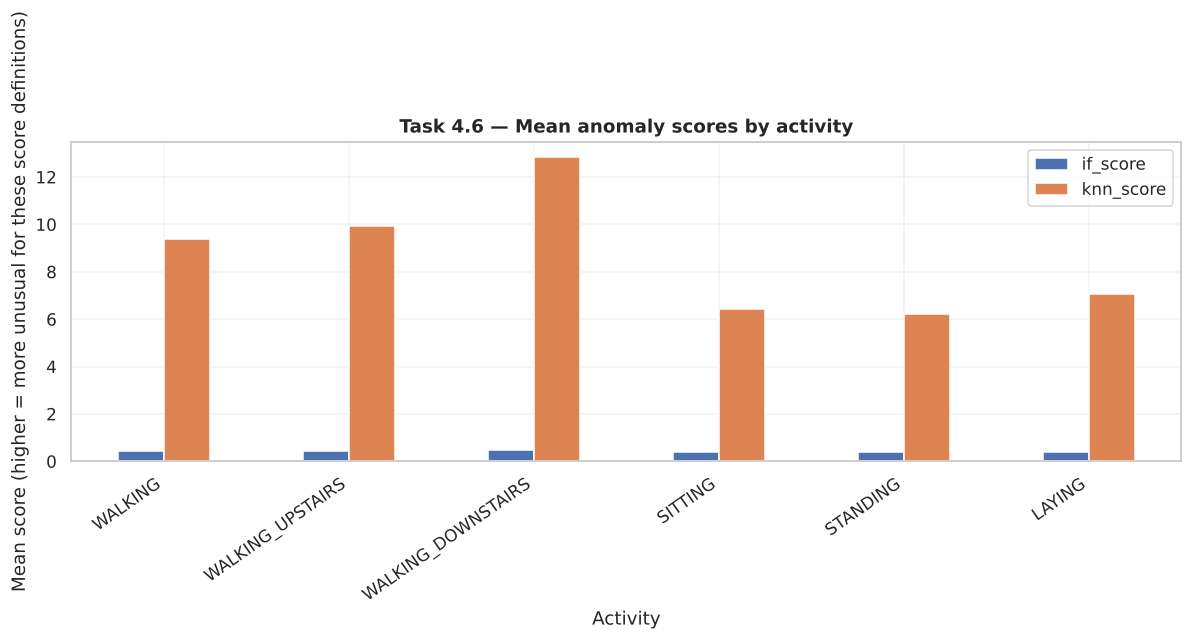


TASK 4 — DATA-DRIVEN SUMMARY
Highest average within-activity feature variance: WALKING_DOWNSTAIRS (0.0519).
Highest mean multivariate dispersion: WALKING_DOWNSTAIRS (17.578).
Locally sparsest activity by global 5-NN distance: WALKING_DOWNSTAIRS (10.898).
Greatest between-participant spread in activity: WALKING_DOWNSTAIRS.
WALKING_DOWNSTAIRS baseline prevalence in this training subset: 13.41%.
Use the enrichment table and participant counts above to assess whether downstairs unusualness is activity-wide or concentrated in a small number of participants.

Interpretation caution: UCI HAR windows are 2.56 seconds long and overlap by 50%; adjacent windows are therefore not independent. The dataset contains derived, normalised features rather than raw unfiltered sensor values. High anomaly scores describe geometric unusualness and do not establish abnormal or unsafe movement.


In [59]:
# ================================================================
# TASK 4 — MOVEMENT VARIABILITY AND DIVERSITY
# Uses the training data and PCA/anomaly objects from Youssef's preliminary anomaly-score cell.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Check that the upstream Task 3 / RQ2 cell has been run.
required_objects = ["d", "Q", "X", "feature_cols", "ORDER", "ACTIVITY_NAMES"]
missing_objects = [obj for obj in required_objects if obj not in globals()]
if missing_objects:
    raise RuntimeError(
        "Run Youssef's Task 3 cells (including the preliminary anomaly scores) before Task 4. "
        f"Missing: {missing_objects}"
    )

task4_df = d.copy().reset_index(drop=True)
task4_Q = np.asarray(Q)
task4_X = X.reset_index(drop=True)

if len(task4_df) != len(task4_Q) or len(task4_df) != len(task4_X):
    raise ValueError("Rows in d, Q, and X do not align.")

activity_order = [a for a in ORDER if a in task4_df["activity"].unique()]
task4_df["activity"] = pd.Categorical(
    task4_df["activity"], categories=activity_order, ordered=True
)

print("TASK 4 — Movement variability and diversity")
print(
    f"Analysing {len(task4_df):,} training windows, "
    f"{task4_X.shape[1]} features, and "
    f"{task4_df['subject_id'].nunique()} participants."
)
print("The activity labels are used for grouping and interpretation only.")

# ----------------------------------------------------------------
# 1. Within-activity feature variance
# ----------------------------------------------------------------
# Variance is calculated from the feature values as supplied in the
# UCI HAR feature matrix. Average variance gives a compact activity
# summary; feature-level results show which measurements vary most.

feature_variance_by_activity = (
    task4_df[["activity"]]
    .join(task4_X)
    .groupby("activity", observed=True)[task4_X.columns]
    .var(ddof=1)
    .reindex(activity_order)
)

mean_feature_variance = feature_variance_by_activity.mean(axis=1)
variance_summary = pd.DataFrame({
    "mean_feature_variance": mean_feature_variance,
    "median_feature_variance": feature_variance_by_activity.median(axis=1),
    "n_windows": task4_df.groupby("activity", observed=True).size().reindex(activity_order)
}).sort_values("mean_feature_variance", ascending=False)

print("\n1) Within-activity feature variance (highest first):")
display(variance_summary.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(
    x=variance_summary.index.astype(str),
    y=variance_summary["mean_feature_variance"],
    color="steelblue"
)
plt.title("Task 4.1 — Mean feature variance within each activity")
plt.xlabel("Activity")
plt.ylabel("Mean variance across 561 features")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Show features with the largest variance for each activity.
top_variance_features = {}
for activity in activity_order:
    top_variance_features[activity] = (
        feature_variance_by_activity.loc[activity]
        .sort_values(ascending=False)
        .head(8)
    )

print("\nTop 8 high-variance features within each activity:")
for activity, values in top_variance_features.items():
    print(f"\n{activity}")
    display(values.rename("variance").to_frame().round(4))

# ----------------------------------------------------------------
# 2. Multivariate dispersion from activity centroids in PCA space
# ----------------------------------------------------------------
# Q is the PCA representation produced in the upstream cell. Euclidean
# distances to each activity centroid measure within-class spread.

dispersion_values = np.zeros(len(task4_df), dtype=float)
activity_centroids = {}

for activity in activity_order:
    mask = task4_df["activity"].eq(activity).to_numpy()
    centroid = task4_Q[mask].mean(axis=0)
    activity_centroids[activity] = centroid
    dispersion_values[mask] = np.linalg.norm(task4_Q[mask] - centroid, axis=1)

task4_df["activity_centroid_distance"] = dispersion_values

dispersion_summary = (
    task4_df.groupby("activity", observed=True)["activity_centroid_distance"]
    .agg(["mean", "median", "std", "count"])
    .reindex(activity_order)
    .sort_values("mean", ascending=False)
)

print("\n2) Multivariate dispersion in PCA space (highest mean first):")
display(dispersion_summary.round(3))

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=task4_df,
    x="activity",
    y="activity_centroid_distance",
    order=activity_order,
    showfliers=False,
    color="mediumpurple"
)
plt.title("Task 4.2 — Multivariate dispersion within activities")
plt.xlabel("Activity")
plt.ylabel("Distance to activity centroid (PCA space)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------
# 3. Local neighbourhood distance and density
# ----------------------------------------------------------------
# Global 5-neighbour distance reflects local sparsity in the overall
# feature space. Activity-restricted 5-NN distances assess density
# within each activity. Smaller distances mean denser neighbourhoods.

k_local = 5
global_k = min(k_local + 1, len(task4_Q))
global_nn = NearestNeighbors(n_neighbors=global_k, n_jobs=-1).fit(task4_Q)
global_distances, _ = global_nn.kneighbors(task4_Q)
# The first distance is the observation itself (zero).
task4_df["global_5nn_distance"] = global_distances[:, 1:].mean(axis=1)

within_activity_distance = np.full(len(task4_df), np.nan)
for activity in activity_order:
    idx = np.flatnonzero(task4_df["activity"].eq(activity).to_numpy())
    if len(idx) <= k_local:
        within_activity_distance[idx] = np.nan
        continue
    nn_activity = NearestNeighbors(
        n_neighbors=k_local + 1, n_jobs=-1
    ).fit(task4_Q[idx])
    distances_activity, _ = nn_activity.kneighbors(task4_Q[idx])
    within_activity_distance[idx] = distances_activity[:, 1:].mean(axis=1)

task4_df["within_activity_5nn_distance"] = within_activity_distance

density_summary = (
    task4_df.groupby("activity", observed=True)
    .agg(
        mean_global_5nn=("global_5nn_distance", "mean"),
        median_global_5nn=("global_5nn_distance", "median"),
        mean_within_activity_5nn=("within_activity_5nn_distance", "mean"),
        median_within_activity_5nn=("within_activity_5nn_distance", "median"),
        n_windows=("subject_id", "size")
    )
    .reindex(activity_order)
    .sort_values("mean_global_5nn", ascending=False)
)

print("\n3) Neighbourhood distances (larger distance = locally sparser):")
display(density_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(
    data=task4_df, x="activity", y="global_5nn_distance",
    order=activity_order, showfliers=False, ax=axes[0], color="darkorange"
)
axes[0].set_title("Global 5-NN distance by activity")
axes[0].set_ylabel("Mean distance to 5 nearest neighbours")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=35)

sns.boxplot(
    data=task4_df, x="activity", y="within_activity_5nn_distance",
    order=activity_order, showfliers=False, ax=axes[1], color="teal"
)
axes[1].set_title("Activity-restricted 5-NN distance")
axes[1].set_ylabel("Mean within-activity neighbour distance")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------
# 4. Check whether activities contain multiple distinct patterns
# ----------------------------------------------------------------
# Fit k-means separately within each activity in PCA space and compare
# silhouette scores for k=2 and k=3. Scores are computed on a capped,
# reproducible sample for computational efficiency. This is exploratory,
# not proof that clusters are natural movement subtypes.

rng = np.random.RandomState(RANDOM_STATE)
subpattern_rows = []
subpattern_models = {}

max_silhouette_sample = 1200

for activity in activity_order:
    idx = np.flatnonzero(task4_df["activity"].eq(activity).to_numpy())
    Xa = task4_Q[idx]

    if len(idx) < 20:
        continue

    if len(idx) > max_silhouette_sample:
        sample_local = rng.choice(
            np.arange(len(idx)), size=max_silhouette_sample, replace=False
        )
        X_eval = Xa[sample_local]
    else:
        X_eval = Xa

    for k in [2, 3]:
        model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        labels_eval = model.fit_predict(X_eval)

        if len(np.unique(labels_eval)) > 1 and len(X_eval) > k:
            score = silhouette_score(X_eval, labels_eval)
        else:
            score = np.nan

        subpattern_rows.append({
            "activity": activity,
            "k": k,
            "silhouette": score,
            "evaluated_windows": len(X_eval)
        })
        subpattern_models[(activity, k)] = model

subpattern_summary = pd.DataFrame(subpattern_rows)
print("\n4) Within-activity clustering check (larger silhouette suggests clearer subgroups):")
display(
    subpattern_summary.pivot(
        index="activity", columns="k", values="silhouette"
    ).reindex(activity_order).round(3)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=subpattern_summary,
    x="activity",
    y="silhouette",
    hue="k"
)
plt.title("Task 4.4 — Evidence for multiple within-activity patterns")
plt.xlabel("Activity")
plt.ylabel("Silhouette score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------
# 5. Is variability distributed across participants or concentrated?
# ----------------------------------------------------------------
# For each activity-participant pair, summarize distances from that
# participant's windows to the activity centroid. Large values show
# participant groups that contribute more to activity-level spread.

participant_activity = (
    task4_df.groupby(["activity", "subject_id"], observed=True)
    .agg(
        participant_mean_dispersion=("activity_centroid_distance", "mean"),
        participant_median_dispersion=("activity_centroid_distance", "median"),
        participant_window_count=("activity_centroid_distance", "size")
    )
    .reset_index()
)

participant_variability_summary = (
    participant_activity.groupby("activity", observed=True)
    .agg(
        mean_participant_dispersion=("participant_mean_dispersion", "mean"),
        sd_between_participants=("participant_mean_dispersion", "std"),
        min_participant_dispersion=("participant_mean_dispersion", "min"),
        max_participant_dispersion=("participant_mean_dispersion", "max"),
        participants=("subject_id", "nunique")
    )
    .reindex(activity_order)
    .sort_values("sd_between_participants", ascending=False)
)

print("\n5) Participant contribution to variability by activity:")
display(participant_variability_summary.round(3))

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=participant_activity,
    x="activity",
    y="participant_mean_dispersion",
    order=activity_order,
    showfliers=True,
    color="cornflowerblue"
)
sns.stripplot(
    data=participant_activity,
    x="activity",
    y="participant_mean_dispersion",
    order=activity_order,
    color="black",
    alpha=0.45,
    size=3
)
plt.title("Task 4.5 — Dispersion of participants within each activity")
plt.xlabel("Activity")
plt.ylabel("Participant mean distance to activity centroid")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Per activity, quantify how much the sum of participant-level
# squared deviations contributes to total within-activity squared spread.
participant_concentration_rows = []
for activity in activity_order:
    activity_mask = task4_df["activity"].eq(activity).to_numpy()
    Qa = task4_Q[activity_mask]
    subj_a = task4_df.loc[activity_mask, "subject_id"].to_numpy()

    centroid = Qa.mean(axis=0)
    total_ss = ((Qa - centroid) ** 2).sum()

    subject_centroid_ss = 0.0
    subject_centroids = []
    for subject in np.unique(subj_a):
        sub_mask = subj_a == subject
        sub_centroid = Qa[sub_mask].mean(axis=0)
        subject_centroids.append((subject, sub_mask.sum(), sub_centroid))
        subject_centroid_ss += sub_mask.sum() * (
            (sub_centroid - centroid) ** 2
        ).sum()

    ratio = subject_centroid_ss / total_ss if total_ss > 0 else np.nan
    participant_concentration_rows.append({
        "activity": activity,
        "between_subject_share_of_dispersion": ratio,
        "within_subject_share_approx": 1 - ratio if pd.notna(ratio) else np.nan
    })

participant_concentration = pd.DataFrame(participant_concentration_rows).set_index(
    "activity"
).reindex(activity_order)

print("\nBetween-participant share of activity dispersion (approximate variance decomposition):")
display(participant_concentration.round(3))

# ----------------------------------------------------------------
# 6. Focus: why WALKING_DOWNSTAIRS appears among high anomaly scores
# ----------------------------------------------------------------
# Reuse anomaly flags produced in the prior cell. Compare the downstairs
# share among flagged observations with its overall prevalence, and
# inspect participant-level concentration and feature-level differences.

if "if_top5" in task4_df.columns and "knn_top5" in task4_df.columns:
    anomaly_flag_cols = ["if_top5", "knn_top5"]
else:
    anomaly_flag_cols = []
    print(
        "\nNote: anomaly shortlist flags are not available in d. "
        "Task 4 will still report variability/density, but anomaly enrichment "
        "needs Cell 22's IF/KNN top-5% flags."
    )

downstairs_name = "WALKING_DOWNSTAIRS"
if downstairs_name in activity_order:
    overall_downstairs_pct = (
        task4_df["activity"].eq(downstairs_name).mean() * 100
    )

    downstairs_anomaly_rows = []
    for flag in anomaly_flag_cols:
        flagged = task4_df[flag].astype(bool)
        flagged_n = int(flagged.sum())
        downstairs_flagged_n = int(
            (flagged & task4_df["activity"].eq(downstairs_name)).sum()
        )
        downstairs_rate_in_flagged = (
            downstairs_flagged_n / flagged_n * 100 if flagged_n else np.nan
        )
        enrichment = (
            downstairs_rate_in_flagged / overall_downstairs_pct
            if overall_downstairs_pct > 0 else np.nan
        )
        activity_rate = (
            task4_df.loc[
                task4_df["activity"].eq(downstairs_name), flag
            ].mean() * 100
        )

        downstairs_anomaly_rows.append({
            "method": flag,
            "all_flagged_n": flagged_n,
            "downstairs_flagged_n": downstairs_flagged_n,
            "downstairs_share_of_flagged_pct": downstairs_rate_in_flagged,
            "downstairs_baseline_share_pct": overall_downstairs_pct,
            "enrichment_vs_activity_prevalence": enrichment,
            "downstairs_within_activity_flag_rate_pct": activity_rate
        })

    downstairs_anomaly_summary = pd.DataFrame(downstairs_anomaly_rows)
    print("\n6) WALKING_DOWNSTAIRS representation among anomaly shortlists:")
    display(downstairs_anomaly_summary.round(2))

    # Compare downstairs and other activity observations in selected
    # variance-ranked features; this offers feature-level clues.
    downstairs_mask = task4_df["activity"].eq(downstairs_name)
    other_mask = ~downstairs_mask

    downstairs_feature_mean = task4_X.loc[downstairs_mask].mean()
    other_feature_mean = task4_X.loc[other_mask].mean()
    downstairs_feature_var = task4_X.loc[downstairs_mask].var(ddof=1)
    other_feature_var = task4_X.loc[other_mask].var(ddof=1)

    feature_contrast = pd.DataFrame({
        "downstairs_mean": downstairs_feature_mean,
        "other_activities_mean": other_feature_mean,
        "mean_difference": downstairs_feature_mean - other_feature_mean,
        "downstairs_variance": downstairs_feature_var,
        "other_activities_variance": other_feature_var,
        "variance_ratio_downstairs_to_others": (
            downstairs_feature_var / other_feature_var.replace(0, np.nan)
        )
    })

    print("\nFeature contrasts for WALKING_DOWNSTAIRS — top 12 variance ratios:")
    display(
        feature_contrast.sort_values(
            "variance_ratio_downstairs_to_others", ascending=False
        ).head(12).round(4)
    )

    # Participant concentration among flagged downstairs windows
    for flag in anomaly_flag_cols:
        flagged_downstairs = task4_df[
            task4_df["activity"].eq(downstairs_name)
            & task4_df[flag].astype(bool)
        ]
        if len(flagged_downstairs):
            subject_counts = (
                flagged_downstairs.groupby("subject_id", observed=True)
                .size()
                .sort_values(ascending=False)
            )
            print(f"\nDownstairs {flag} flags by participant:")
            display(subject_counts.rename("flagged_windows").to_frame())
            print(
                f"Participants contributing at least one flagged downstairs "
                f"window: {subject_counts.size}"
            )
            print(
                f"Share from top participant: "
                f"{subject_counts.iloc[0] / subject_counts.sum() * 100:.1f}%"
            )

    # Compare anomaly scores by activity (if present)
    score_cols = [c for c in ["if_score", "knn_score"] if c in task4_df.columns]
    if score_cols:
        anomaly_score_by_activity = (
            task4_df.groupby("activity", observed=True)[score_cols]
            .mean()
            .reindex(activity_order)
        )
        print("\nMean anomaly scores by activity:")
        display(anomaly_score_by_activity.round(4))

        anomaly_score_by_activity.plot(
            kind="bar", figsize=(11, 5)
        )
        plt.title("Task 4.6 — Mean anomaly scores by activity")
        plt.xlabel("Activity")
        plt.ylabel("Mean score (higher = more unusual for these score definitions)")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()
else:
    print(
        "\nWALKING_DOWNSTAIRS is not present in this activity mapping; "
        "please verify activity labels."
    )

# ----------------------------------------------------------------
# 7. Automatic evidence summary (data-derived, not a fixed conclusion)
# ----------------------------------------------------------------
highest_variance_activity = variance_summary["mean_feature_variance"].idxmax()
highest_dispersion_activity = dispersion_summary["mean"].idxmax()
sparsest_global_activity = density_summary["mean_global_5nn"].idxmax()
largest_between_subject_activity = (
    participant_variability_summary["sd_between_participants"].idxmax()
)

print("\n" + "=" * 68)
print("TASK 4 — DATA-DRIVEN SUMMARY")
print("=" * 68)
print(
    f"Highest average within-activity feature variance: "
    f"{highest_variance_activity} "
    f"({variance_summary.loc[highest_variance_activity, 'mean_feature_variance']:.4f})."
)
print(
    f"Highest mean multivariate dispersion: {highest_dispersion_activity} "
    f"({dispersion_summary.loc[highest_dispersion_activity, 'mean']:.3f})."
)
print(
    f"Locally sparsest activity by global 5-NN distance: "
    f"{sparsest_global_activity} "
    f"({density_summary.loc[sparsest_global_activity, 'mean_global_5nn']:.3f})."
)
print(
    f"Greatest between-participant spread in activity: "
    f"{largest_between_subject_activity}."
)
if downstairs_name in activity_order:
    print(
        f"WALKING_DOWNSTAIRS baseline prevalence in this training subset: "
        f"{overall_downstairs_pct:.2f}%."
    )
    if anomaly_flag_cols:
        print(
            "Use the enrichment table and participant counts above to assess "
            "whether downstairs unusualness is activity-wide or concentrated "
            "in a small number of participants."
        )

print(
    "\nInterpretation caution: UCI HAR windows are 2.56 seconds long and "
    "overlap by 50%; adjacent windows are therefore not independent. "
    "The dataset contains derived, normalised features rather than raw "
    "unfiltered sensor values. High anomaly scores describe geometric "
    "unusualness and do not establish abnormal or unsafe movement."
)


### Task 5 — Participant-specific movement characteristics
Objective: Investigate whether individuals exhibit consistent and distinguishable movement patterns.

**Member**: Sushanth

What needs to be done:
1. Compare participants while controlling for activity type.
2. Examine how participant-specific feature distributions differ.
3. Investigate whether some participants occupy distinct regions within the same activity.
4. Compare within-participant and between-participant variability.
5. Examine whether participant 19 is consistently distinctive or whether only a few observations are extreme.
Expected output: Evidence showing whether individual movement differences are systematic or concentrated in isolated observations.

*Code by Sushanth (from DSA8003_Group_4_Analysis_(main).ipynb).*

21 participants, 7,352 windows, 561 features
Windows per participant x activity: min 36 | median 55 | max 95


activity,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
subject_id,,,,,,
participant 19,52,40,39,73,73,83


,participants,median eta2 (participant),chance level (shuffled),% features eta2 > 0.30
WALKING,21,0.617,0.017,80.570
WALKING_UPSTAIRS,21,0.563,0.018,74.866
WALKING_DOWNSTAIRS,21,0.475,0.019,75.758
SITTING,21,0.067,0.015,3.565
STANDING,21,0.105,0.014,4.278
LAYING,21,0.100,0.013,5.704


For comparison, the activity label explains a median 0.50 of feature variance across all windows.


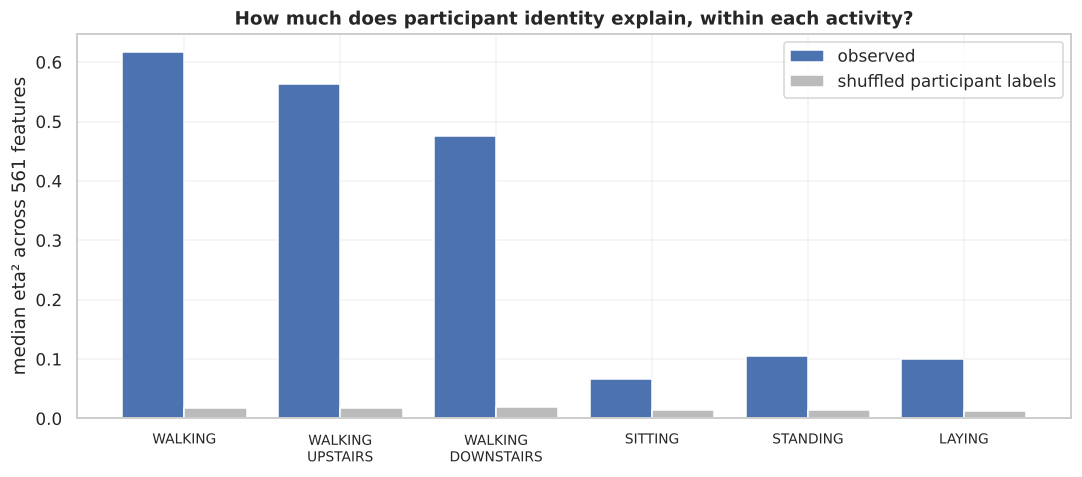

,mean eta2 (participant),strongest in
tGravityAcc-mean()-Z,0.712,WALKING_UPSTAIRS
tGravityAcc-energy()-Y,0.712,WALKING_DOWNSTAIRS
"angle(Z,gravityMean)",0.710,WALKING_UPSTAIRS
tGravityAcc-min()-Z,0.707,WALKING_UPSTAIRS
tGravityAcc-max()-Z,0.706,WALKING_UPSTAIRS
tGravityAcc-sma(),0.675,WALKING_UPSTAIRS
"angle(X,gravityMean)",0.667,WALKING
tGravityAcc-mean()-X,0.649,WALKING
"angle(Y,gravityMean)",0.649,WALKING_DOWNSTAIRS
tGravityAcc-energy()-Z,0.646,LAYING


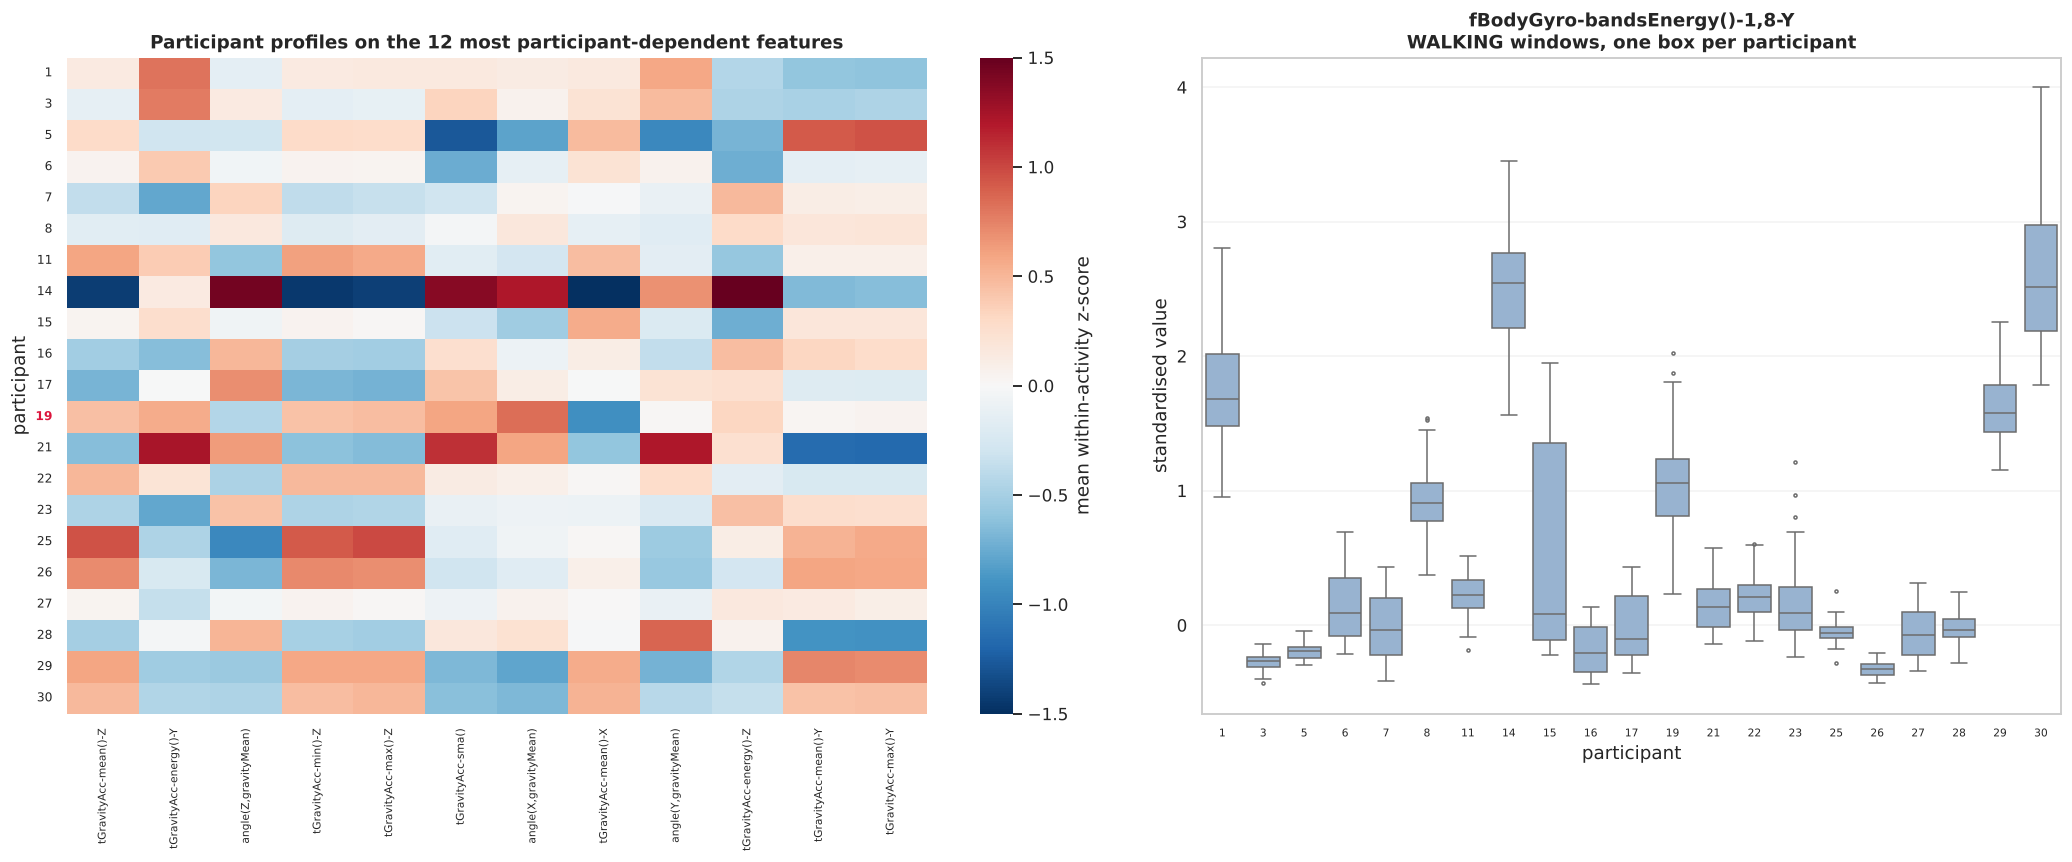

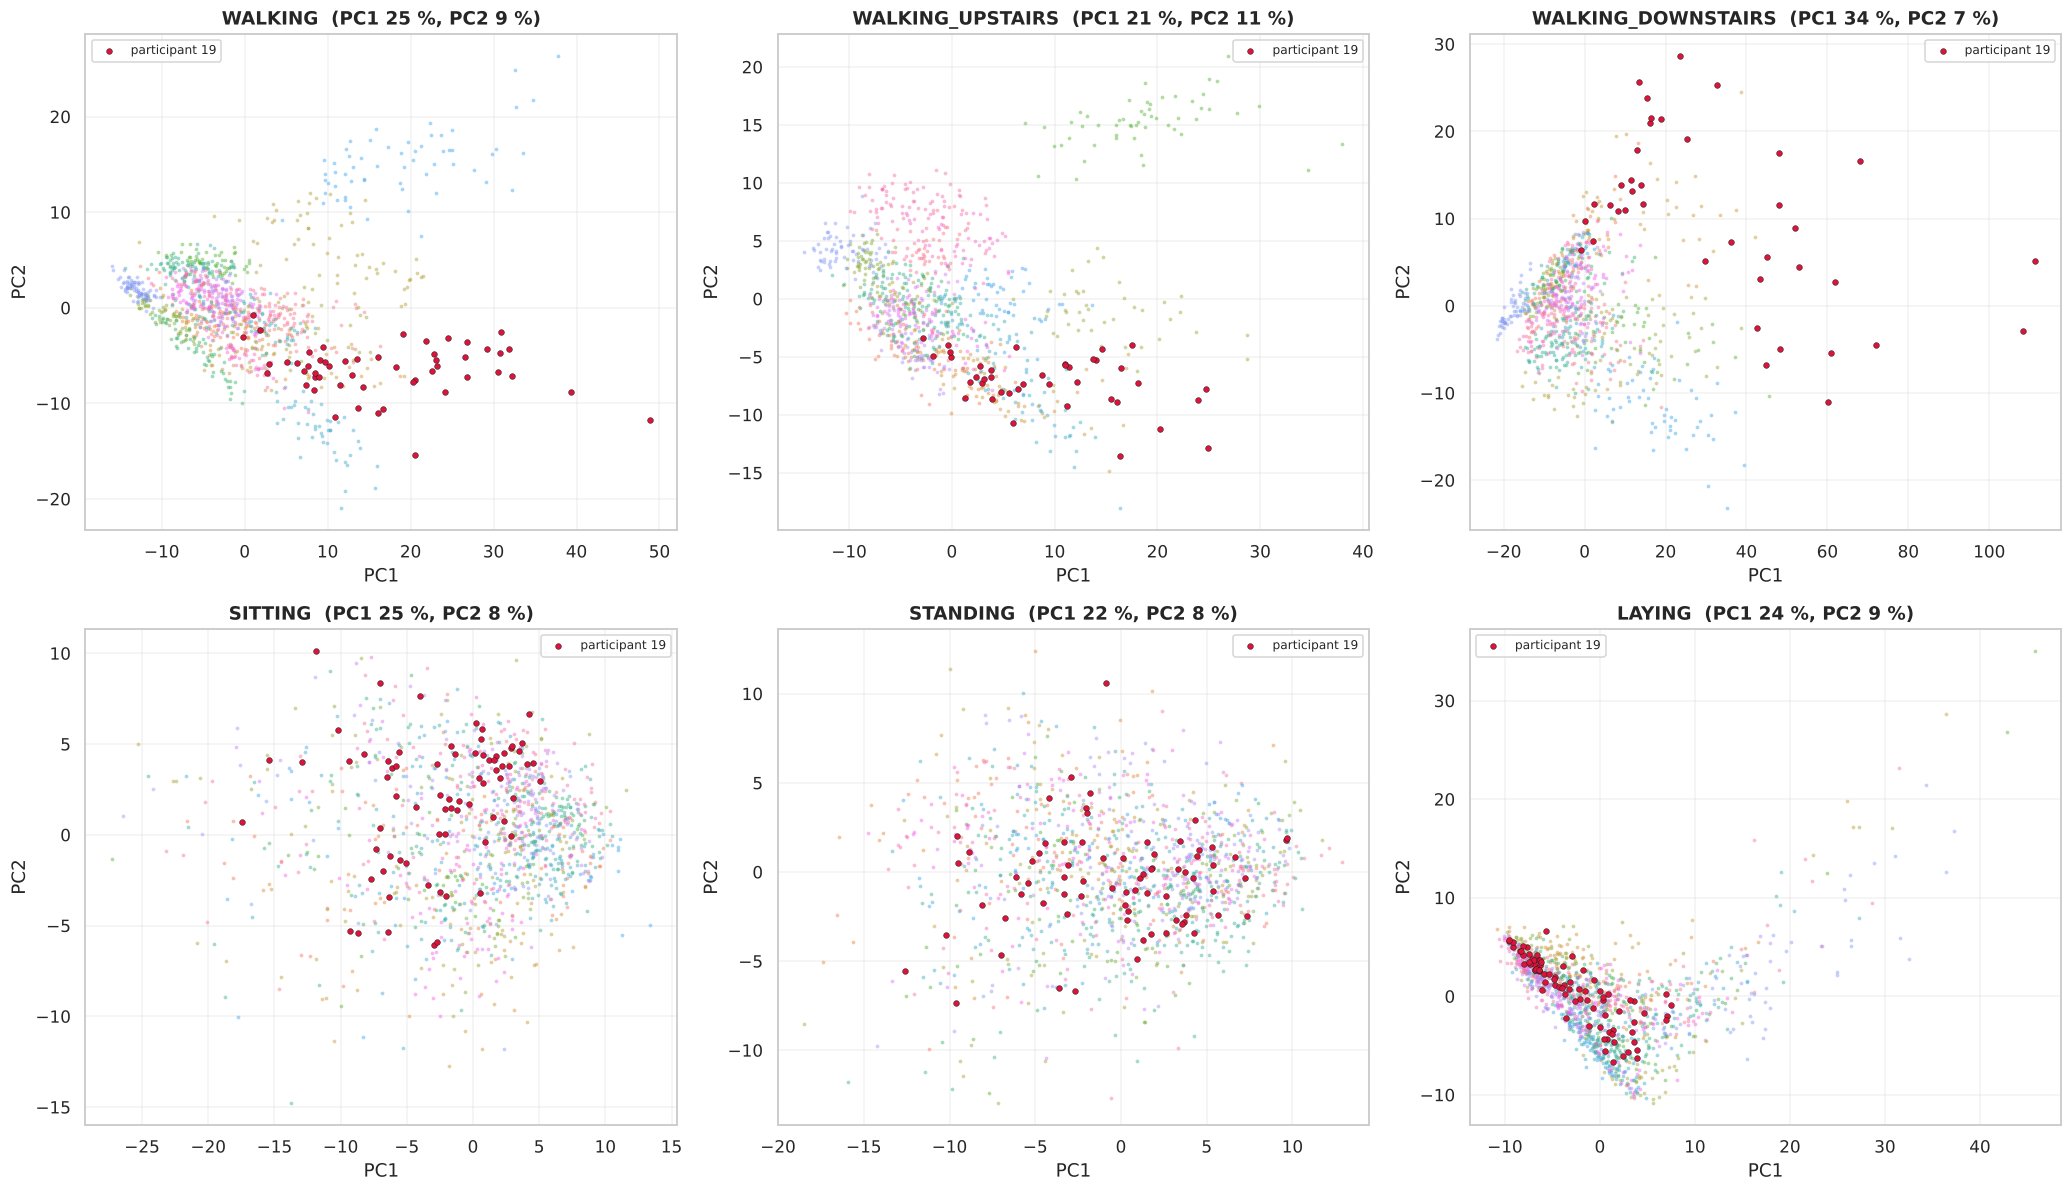

,participants,silhouette (participant),chance accuracy,held-out kNN accuracy,accuracy for participant 19
activity,,,,,
WALKING,21,0.216,0.048,0.958,1.000
WALKING_UPSTAIRS,21,0.099,0.048,0.796,0.667
WALKING_DOWNSTAIRS,21,0.040,0.048,0.631,0.833
SITTING,21,-0.101,0.048,0.162,0.409
STANDING,21,-0.089,0.048,0.192,0.136
LAYING,21,-0.059,0.048,0.497,0.640


,within,between,between (shuffled baseline),between / baseline,% feature variance within participants,19: within,19: between,19: within rank (1 = most variable),19: between rank (1 = furthest from centre)
activity,,,,,,,,,
WALKING,3.18,2.91,0.58,5.04,38.25,5.17,3.65,1,4
WALKING_UPSTAIRS,3.52,2.54,0.60,4.23,43.66,4.51,2.70,2,7
WALKING_DOWNSTAIRS,3.48,2.39,0.64,3.74,52.52,6.45,3.63,1,2
SITTING,4.03,1.51,0.56,2.70,93.32,3.87,1.98,14,2
STANDING,4.04,1.58,0.54,2.94,89.51,3.94,1.42,14,15
LAYING,3.65,1.93,0.53,3.63,89.96,3.68,1.84,7,11


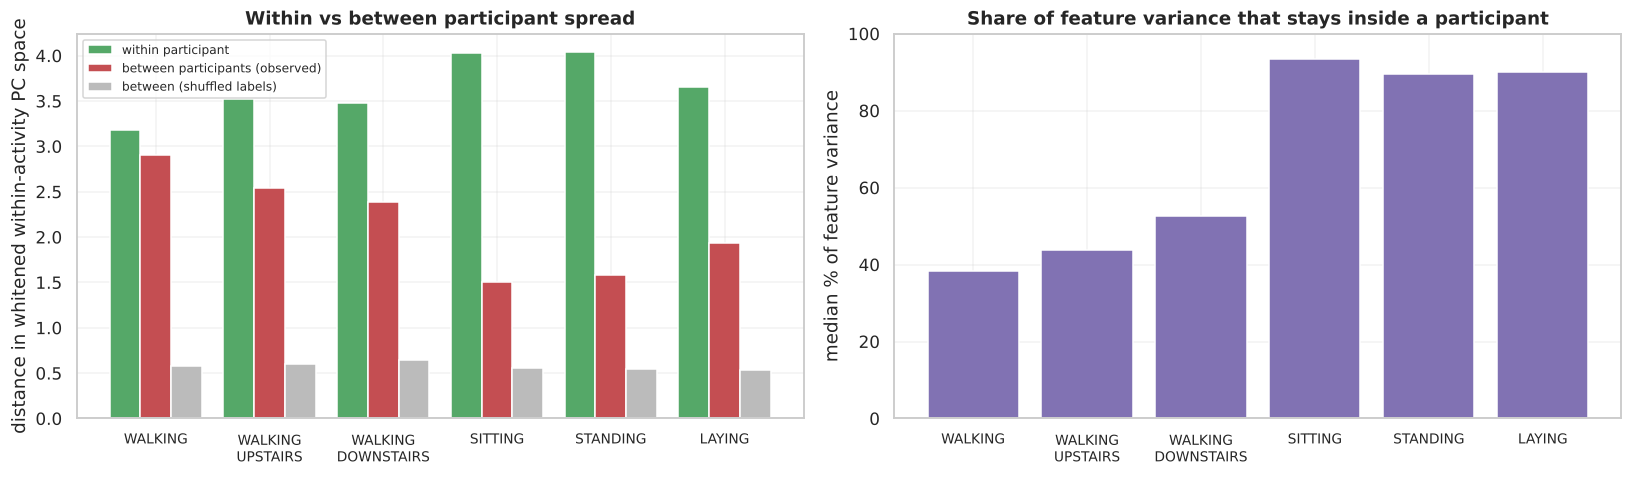

,windows (19),median dist (19),median dist (others),"rank of median (of n, 1 = most distinct)",rank of 95th pct,participants,% windows flagged (chance ≈ 5),flagged windows,longest flagged run
activity,,,,,,,,,
WALKING,52,5.91,4.06,1,1,21,34.62,18,5
WALKING_UPSTAIRS,40,4.93,4.09,5,3,21,15.00,6,2
WALKING_DOWNSTAIRS,39,6.81,3.80,1,1,21,51.28,20,7
SITTING,73,4.33,4.07,5,15,21,1.37,1,1
STANDING,73,4.01,4.17,13,13,21,2.74,2,1
LAYING,83,3.98,3.79,7,11,21,2.41,2,1


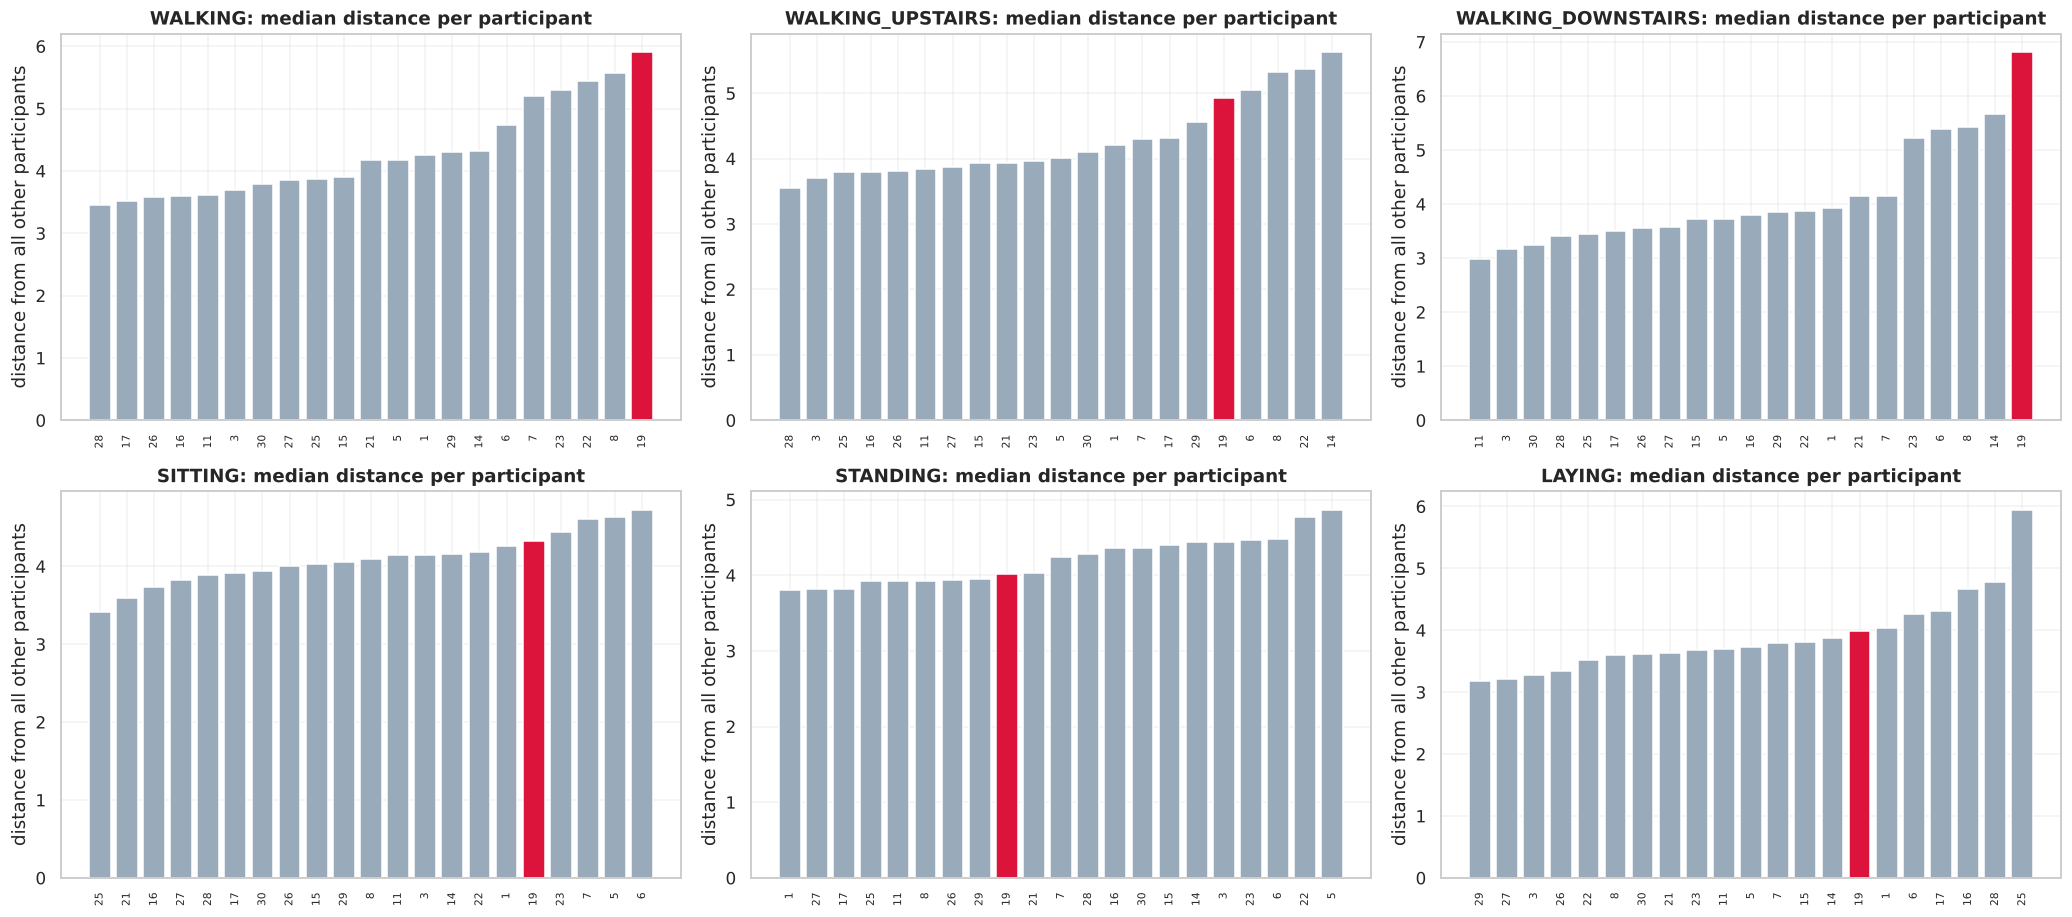

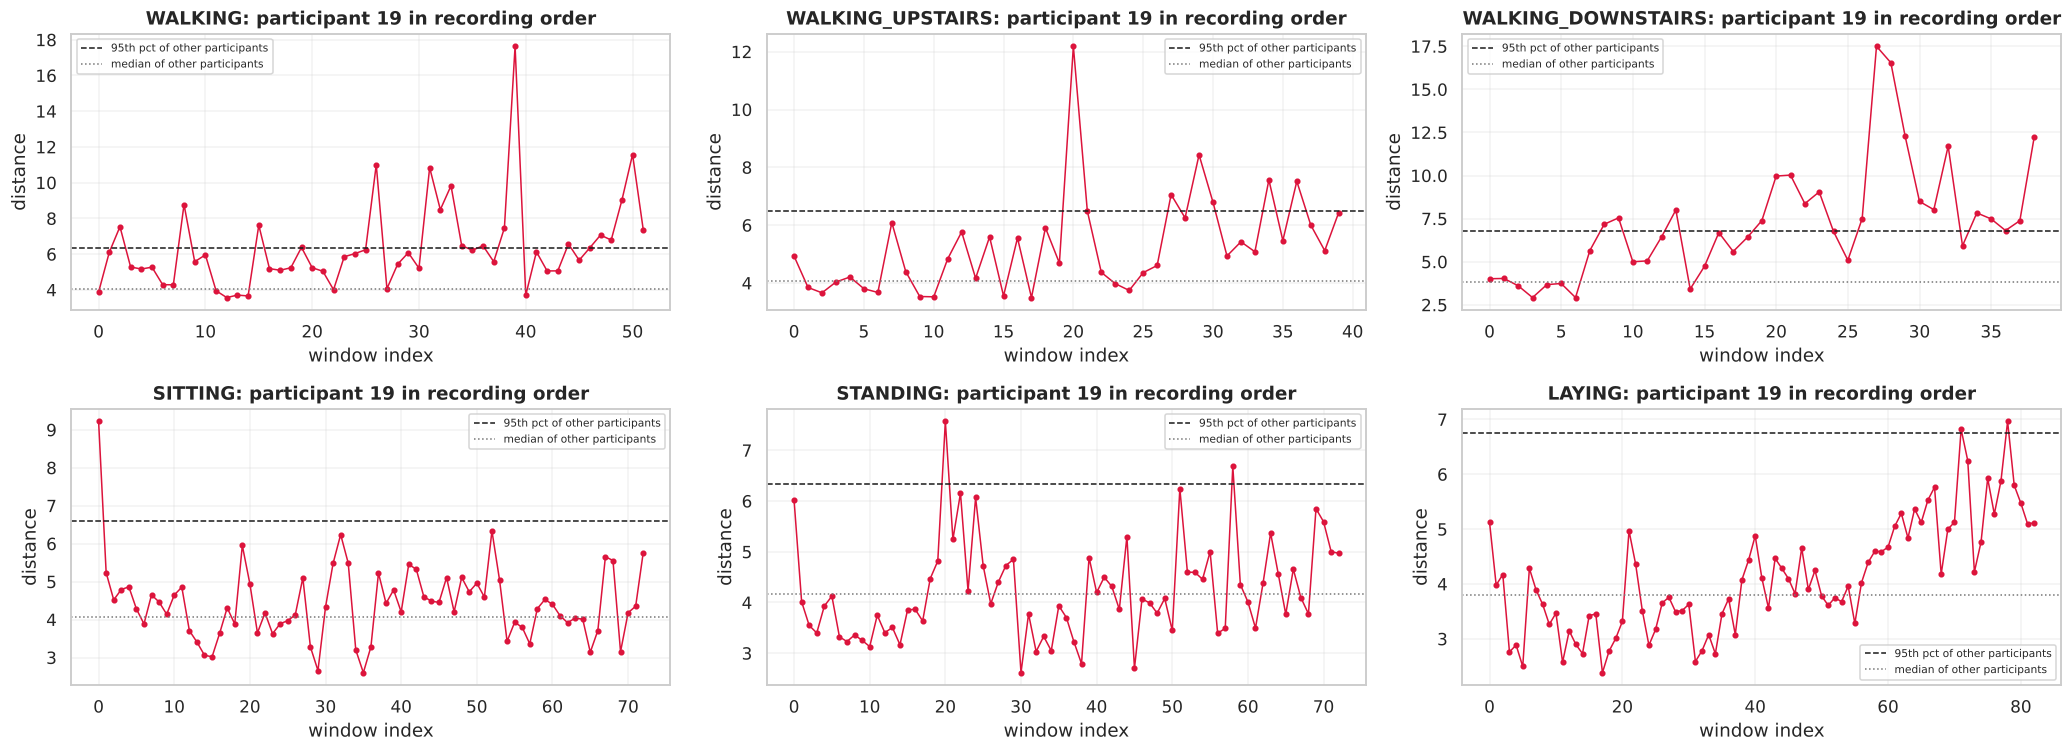

,mean |d| over activities,signed d (WALKING),signed d (SITTING),signed d (LAYING)
tBodyGyroJerk-energy()-X,1.48,3.47,-0.12,-0.10
fBodyGyro-mean()-X,1.46,3.93,-0.10,-0.18
"fBodyAccJerk-bandsEnergy()-1,16-X",1.44,3.24,-0.12,-0.18
fBodyGyro-energy()-X,1.43,4.29,-0.09,-0.14
"fBodyGyro-bandsEnergy()-1,24-X",1.41,4.22,-0.09,-0.14
tBodyGyroJerk-iqr()-X,1.37,2.85,-0.14,-0.10
tBodyGyroJerk-mad()-X,1.37,2.96,-0.10,-0.05
"fBodyGyro-bandsEnergy()-1,16-X",1.35,4.16,-0.09,-0.14
tBodyGyro-energy()-X,1.35,3.89,-0.13,-0.18
tBodyAccJerk-energy()-X,1.35,2.97,-0.16,-0.15


Participant 19: median |d| over all features = 0.56; features with mean |d| > 1: 80 of 561


,"10 PCs, whitened","20 PCs, whitened (used above)","40 PCs, whitened","20 PCs, not whitened"
rank of participant 19's median distance (1 of 21 = most distinct),,,,
WALKING,5,1,2,2
WALKING_UPSTAIRS,6,5,5,5
WALKING_DOWNSTAIRS,1,1,1,1
SITTING,6,5,10,7
STANDING,15,13,14,20
LAYING,10,7,9,14


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", context="notebook")
T5_SEED = 42
T5_ACT = {1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS",
          4: "SITTING", 5: "STANDING", 6: "LAYING"}
T5_ORDER = list(T5_ACT.values())
FOCUS = 19
N_PC = 20

t5_meta = train_df[["subject_id", "activity_id"]].reset_index(drop=True)
t5_meta["activity"] = t5_meta["activity_id"].map(T5_ACT)
t5_meta["win"] = t5_meta.groupby(["subject_id", "activity_id"]).cumcount()
t5_X = X_train_scaled_df.reset_index(drop=True)
assert len(t5_X) == len(t5_meta) and FOCUS in set(t5_meta["subject_id"])

t5_counts = t5_meta.pivot_table(index="subject_id", columns="activity", values="win",
                                aggfunc="count").reindex(columns=T5_ORDER)
print(f"{t5_meta['subject_id'].nunique()} participants, {len(t5_meta):,} windows, {t5_X.shape[1]} features")
print("Windows per participant x activity: min", int(t5_counts.min().min()),
      "| median", int(t5_counts.stack().median()), "| max", int(t5_counts.max().max()))
display(t5_counts.loc[[FOCUS]].rename(index={FOCUS: f"participant {FOCUS}"}))


def eta_squared(Xv, labels):
    codes, uniq = pd.factorize(labels)
    grand = Xv.mean(axis=0)
    ss_total = ((Xv - grand) ** 2).sum(axis=0)
    ss_between = np.zeros(Xv.shape[1])
    for k in range(len(uniq)):
        m = codes == k
        ss_between += m.sum() * (Xv[m].mean(axis=0) - grand) ** 2
    return np.where(ss_total > 0, ss_between / ss_total, np.nan)


rng = np.random.default_rng(T5_SEED)
t5_eta = {}
t5_null = {}

for act in T5_ORDER:
    m = (t5_meta["activity"] == act).to_numpy()
    Xv, s = t5_X.to_numpy()[m], t5_meta.loc[m, "subject_id"].to_numpy()
    t5_eta[act] = eta_squared(Xv, s)
    t5_null[act] = np.median([np.nanmedian(eta_squared(Xv, rng.permutation(s))) for _ in range(20)])

t5_eta_activity = eta_squared(t5_X.to_numpy(), t5_meta["activity"].to_numpy())

t5_item1 = pd.DataFrame({
    "participants": [t5_meta.loc[t5_meta.activity == a, "subject_id"].nunique() for a in T5_ORDER],
    "median eta2 (participant)": [np.nanmedian(t5_eta[a]) for a in T5_ORDER],
    "chance level (shuffled)": [t5_null[a] for a in T5_ORDER],
    "% features eta2 > 0.30": [np.nanmean(t5_eta[a] > 0.30) * 100 for a in T5_ORDER],
}, index=T5_ORDER).round(3)

display(t5_item1)

print(f"For comparison, the activity label explains a median {np.nanmedian(t5_eta_activity):.2f} "
      f"of feature variance across all windows.")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(T5_ORDER))
ax.bar(x - 0.2, t5_item1["median eta2 (participant)"], 0.4, label="observed", color="#4c72b0")
ax.bar(x + 0.2, t5_item1["chance level (shuffled)"], 0.4, label="shuffled participant labels", color="#bbbbbb")
ax.set_xticks(x, [a.replace("_", "\n") for a in T5_ORDER], fontsize=9)
ax.set(ylabel="median eta² across 561 features", title="How much does participant identity explain, within each activity?")
ax.legend()
plt.tight_layout()
plt.show()


t5_eta_df = pd.DataFrame(t5_eta, index=t5_X.columns)
t5_eta_mean = t5_eta_df.mean(axis=1).sort_values(ascending=False)
t5_top = list(t5_eta_mean.index[:12])

display(pd.DataFrame({"mean eta2 (participant)": t5_eta_mean.iloc[:12],
                      "strongest in": t5_eta_df.loc[t5_top].idxmax(axis=1)}).round(3))

t5_z = t5_X[t5_top].copy()

for act in T5_ORDER:
    m = (t5_meta["activity"] == act).to_numpy()
    t5_z.loc[m] = (t5_z.loc[m] - t5_z.loc[m].mean()) / t5_z.loc[m].std()

t5_heat = t5_z.groupby(t5_meta["subject_id"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw={"width_ratios": [1.25, 1]})

sns.heatmap(t5_heat, cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, ax=axes[0],
            cbar_kws={"label": "mean within-activity z-score"}, yticklabels=True)

axes[0].set(title="Participant profiles on the 12 most participant-dependent features", xlabel="", ylabel="participant")
axes[0].tick_params(axis="x", labelsize=7)
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0, fontsize=8)

for lbl in axes[0].get_yticklabels():
    if lbl.get_text() == str(FOCUS):
        lbl.set_color("crimson")
        lbl.set_fontweight("bold")

show_act, show_feat = "WALKING", t5_eta_df["WALKING"].idxmax()
m = (t5_meta["activity"] == show_act).to_numpy()
order = t5_meta.loc[m].groupby("subject_id")[[]].size().index

sns.boxplot(data=pd.DataFrame({"participant": t5_meta.loc[m, "subject_id"].to_numpy(),
                               "value": t5_X.loc[m, show_feat].to_numpy()}),
            x="participant", y="value", order=order, ax=axes[1], fliersize=2, color="#8fb3d9")

axes[1].set(title=f"{show_feat}\n{show_act} windows, one box per participant", xlabel="participant", ylabel="standardised value")
axes[1].tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.show()


t5_pca, t5_pc = {}, {}
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
palette = sns.color_palette("husl", t5_meta["subject_id"].nunique())
sub_ids = sorted(t5_meta["subject_id"].unique())
colour_of = dict(zip(sub_ids, palette))
rows = []

for ax, act in zip(axes.flat, T5_ORDER):
    m = (t5_meta["activity"] == act).to_numpy()
    Xv, meta_a = t5_X.to_numpy()[m], t5_meta.loc[m].reset_index(drop=True)
    pca = PCA(n_components=N_PC, random_state=T5_SEED).fit(Xv)
    sc = pca.transform(Xv)
    t5_pca[act], t5_pc[act] = pca, sc

    for s in sub_ids:
        k = (meta_a["subject_id"] == s).to_numpy()
        if not k.any() or s == FOCUS:
            continue
        ax.scatter(sc[k, 0], sc[k, 1], s=6, alpha=0.45, color=colour_of[s], linewidths=0)

    k = (meta_a["subject_id"] == FOCUS).to_numpy()
    ax.scatter(sc[k, 0], sc[k, 1], s=14, color="crimson", edgecolor="k", linewidths=0.3, label=f"participant {FOCUS}")

    ax.set(title=f"{act}  (PC1 {pca.explained_variance_ratio_[0]*100:.0f} %, PC2 {pca.explained_variance_ratio_[1]*100:.0f} %)",
           xlabel="PC1", ylabel="PC2")
    ax.legend(loc="best", fontsize=8)

    sil = silhouette_score(sc[:, :10], meta_a["subject_id"])

    tr, te = [], []

    for s, g in meta_a.groupby("subject_id"):
        cut = int(0.7 * len(g))
        tr += list(g.index[g["win"] < cut - 1])
        te += list(g.index[g["win"] >= cut])

    pca_tr = PCA(n_components=N_PC, random_state=T5_SEED).fit(Xv[tr])
    knn = KNeighborsClassifier(n_neighbors=5).fit(pca_tr.transform(Xv[tr]), meta_a.loc[tr, "subject_id"])

    acc = (knn.predict(pca_tr.transform(Xv[te])) == meta_a.loc[te, "subject_id"].to_numpy()).mean()
    acc19 = (knn.predict(pca_tr.transform(Xv[te]))[(meta_a.loc[te, "subject_id"] == FOCUS).to_numpy()] == FOCUS).mean()

    rows.append((act, meta_a["subject_id"].nunique(), sil, 1 / meta_a["subject_id"].nunique(), acc, acc19))

plt.tight_layout()
plt.show()

t5_item3 = pd.DataFrame(rows, columns=["activity", "participants", "silhouette (participant)",
                                       "chance accuracy", "held-out kNN accuracy",
                                       f"accuracy for participant {FOCUS}"]).set_index("activity").round(3)

display(t5_item3)


rng4 = np.random.default_rng(T5_SEED)
rows = []

for act in T5_ORDER:
    m = (t5_meta["activity"] == act).to_numpy()
    meta_a = t5_meta.loc[m].reset_index(drop=True)
    Z = t5_pc[act] / np.sqrt(t5_pca[act].explained_variance_)
    subs = meta_a["subject_id"].to_numpy()
    cent = pd.DataFrame(Z).groupby(subs).mean()

    within_by_sub = pd.Series(np.linalg.norm(Z - cent.loc[subs].to_numpy(), axis=1)).groupby(subs).mean()
    between_by_sub = pd.Series(np.linalg.norm(cent.to_numpy() - Z.mean(axis=0), axis=1), index=cent.index)

    base = np.mean([np.linalg.norm(pd.DataFrame(Z).groupby(rng4.permutation(subs)).mean().to_numpy() - Z.mean(axis=0), axis=1).mean()
                    for _ in range(20)])

    rows.append((act, within_by_sub.mean(), between_by_sub.mean(), base, between_by_sub.mean() / base,
                 (1 - np.nanmedian(t5_eta[act])) * 100,
                 within_by_sub.loc[FOCUS], between_by_sub.loc[FOCUS],
                 int(within_by_sub.rank(ascending=False).loc[FOCUS]), int(between_by_sub.rank(ascending=False).loc[FOCUS])))

t5_item4 = pd.DataFrame(rows, columns=["activity", "within", "between", "between (shuffled baseline)", "between / baseline",
                                       "% feature variance within participants",
                                       f"{FOCUS}: within", f"{FOCUS}: between",
                                       f"{FOCUS}: within rank (1 = most variable)",
                                       f"{FOCUS}: between rank (1 = furthest from centre)"]).set_index("activity").round(2)

display(t5_item4)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(T5_ORDER))

axes[0].bar(x - 0.27, t5_item4["within"], 0.27, label="within participant", color="#55a868")
axes[0].bar(x, t5_item4["between"], 0.27, label="between participants (observed)", color="#c44e52")
axes[0].bar(x + 0.27, t5_item4["between (shuffled baseline)"], 0.27, label="between (shuffled labels)", color="#bbbbbb")

axes[0].set_xticks(x, [a.replace("_", "\n") for a in T5_ORDER], fontsize=9)
axes[0].set(ylabel="distance in whitened within-activity PC space", title="Within vs between participant spread")
axes[0].legend(fontsize=8)

axes[1].bar(x, t5_item4["% feature variance within participants"], color="#8172b3")
axes[1].set_xticks(x, [a.replace("_", "\n") for a in T5_ORDER], fontsize=9)
axes[1].set(ylabel="median % of feature variance", ylim=(0, 100), title="Share of feature variance that stays inside a participant")

plt.tight_layout()
plt.show()


def leave_participant_out_distance(n_pc=N_PC, whiten=True):
    out_all = pd.Series(np.nan, index=t5_meta.index)

    for act in T5_ORDER:
        m = (t5_meta["activity"] == act).to_numpy()
        meta_a = t5_meta.loc[m]
        pca = PCA(n_components=n_pc, random_state=T5_SEED).fit(t5_X.to_numpy()[m])
        Z = pca.transform(t5_X.to_numpy()[m])

        if whiten:
            Z = Z / np.sqrt(pca.explained_variance_)

        subs = meta_a["subject_id"].to_numpy()
        sums, cnts = pd.DataFrame(Z).groupby(subs).sum(), pd.Series(subs).value_counts()
        out = np.empty(len(Z))

        for s in np.unique(subs):
            k = subs == s
            mu_others = (sums.drop(index=s).sum() / cnts.drop(index=s).sum()).to_numpy()
            out[k] = np.linalg.norm(Z[k] - mu_others, axis=1)

        out_all.loc[meta_a.index] = out

    return out_all


t5_meta["dist"] = leave_participant_out_distance()

rows = []

for act in T5_ORDER:
    a = t5_meta[t5_meta.activity == act]
    mine, others = a[a.subject_id == FOCUS], a[a.subject_id != FOCUS]
    thr = others["dist"].quantile(0.95)
    med_by_sub = a.groupby("subject_id")["dist"].median()
    p95_by_sub = a.groupby("subject_id")["dist"].quantile(0.95)
    flagged = (mine["dist"] > thr).to_numpy()

    run = best = 0

    for f in flagged[np.argsort(mine["win"].to_numpy())]:
        run = run + 1 if f else 0
        best = max(best, run)

    rows.append((act, len(mine), mine["dist"].median(), others["dist"].median(),
                 int(med_by_sub.rank(ascending=False).loc[FOCUS]), int(p95_by_sub.rank(ascending=False).loc[FOCUS]),
                 flagged.mean() * 100, int(flagged.sum()), best))

t5_item5 = pd.DataFrame(rows, columns=["activity", f"windows ({FOCUS})", f"median dist ({FOCUS})", "median dist (others)",
                                       "rank of median (of n, 1 = most distinct)", "rank of 95th pct",
                                       "% windows flagged (chance ≈ 5)", "flagged windows", "longest flagged run"]).set_index("activity").round(2)

n_sub = t5_meta.groupby("activity")["subject_id"].nunique()
t5_item5.insert(5, "participants", n_sub.reindex(T5_ORDER).to_numpy())

display(t5_item5)

fig, axes = plt.subplots(2, 3, figsize=(19, 8.5))

for ax, act in zip(axes.flat, T5_ORDER):
    a = t5_meta[t5_meta.activity == act]
    med = a.groupby("subject_id")["dist"].median().sort_values()
    colors = ["crimson" if s == FOCUS else "#9ab" for s in med.index]

    ax.bar(range(len(med)), med.values, color=colors)
    ax.set_xticks(range(len(med)), med.index, fontsize=7, rotation=90)
    ax.set(title=f"{act}: median distance per participant", ylabel="distance from all other participants")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(19, 7), sharey=False)

for ax, act in zip(axes.flat, T5_ORDER):
    a = t5_meta[t5_meta.activity == act]
    mine, others = a[a.subject_id == FOCUS].sort_values("win"), a[a.subject_id != FOCUS]
    thr = others["dist"].quantile(0.95)

    ax.plot(mine["win"], mine["dist"], color="crimson", lw=1, marker="o", ms=3)
    ax.axhline(thr, ls="--", color="k", lw=1, label="95th pct of other participants")
    ax.axhline(others["dist"].median(), ls=":", color="#777", lw=1, label="median of other participants")
    ax.set(title=f"{act}: participant {FOCUS} in recording order", xlabel="window index", ylabel="distance")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


d_by_act = {}

for act in T5_ORDER:
    m = (t5_meta["activity"] == act).to_numpy()
    sub = (t5_meta.loc[m, "subject_id"] == FOCUS).to_numpy()
    A, B = t5_X.to_numpy()[m][sub], t5_X.to_numpy()[m][~sub]

    pooled = np.sqrt(((len(A) - 1) * A.var(axis=0, ddof=1) + (len(B) - 1) * B.var(axis=0, ddof=1)) / (len(A) + len(B) - 2))
    d_by_act[act] = (A.mean(axis=0) - B.mean(axis=0)) / np.where(pooled > 0, pooled, np.nan)

t5_d = pd.DataFrame(d_by_act, index=t5_X.columns)
top19 = t5_d.abs().mean(axis=1).sort_values(ascending=False).head(10)

display(pd.DataFrame({"mean |d| over activities": top19,
                      "signed d (WALKING)": t5_d.loc[top19.index, "WALKING"],
                      "signed d (SITTING)": t5_d.loc[top19.index, "SITTING"],
                      "signed d (LAYING)": t5_d.loc[top19.index, "LAYING"]}).round(2))

print(f"Participant {FOCUS}: median |d| over all features = {t5_d.abs().median().mean():.2f}; "
      f"features with mean |d| > 1: {(t5_d.abs().mean(axis=1) > 1).sum()} of {len(t5_d)}")

rob = {}

for label, kw in {"10 PCs, whitened": dict(n_pc=10), "20 PCs, whitened (used above)": dict(n_pc=20),
                  "40 PCs, whitened": dict(n_pc=40), "20 PCs, not whitened": dict(n_pc=20, whiten=False)}.items():

    dd = t5_meta[["subject_id", "activity"]].assign(dist=leave_participant_out_distance(**kw))
    rob[label] = dd.groupby(["activity", "subject_id"])["dist"].median().groupby("activity") \
                   .rank(ascending=False).xs(FOCUS, level="subject_id").reindex(T5_ORDER).astype(int)

display(pd.DataFrame(rob).rename_axis(f"rank of participant {FOCUS}'s median distance (1 of 21 = most distinct)"))

#### Task 5 — Findings (participant-specific movement)

*Train split only: 21 participants, 7,352 windows. All statistics are computed within activity, so activity type cannot explain the differences.*

**1. Controlling for activity.** In the three walking activities, participant identity explains a median **48–62 %** of feature variance (≈ 2 % expected by chance), and 75–81 % of features have η² > 0.30. In sitting, standing and laying it explains only **7–11 %** (chance ≈ 1.5 %), with 4–6 % of features above 0.30.

**2. Participant-specific distributions.** The most participant-dependent features are gravity/orientation features (`tGravityAcc` mean, min, max, energy and the `angle(…,gravityMean)` features, mean η² 0.63–0.71). Within WALKING, band-energy features of the gyroscope separate participants strongly (e.g. participants 1, 14, 29 and 30 sit well above the rest). This is consistent with differences in how each phone sat on the waist, but this analysis cannot separate that from gait style.

**3. Distinct regions.** A classifier trained on the first 70 % of each participant's windows (one-window gap, because windows overlap) recognises the participant in the last 30 % with **96 % accuracy for WALKING**, 80 % upstairs, 63 % downstairs and 50 % laying, against 16–19 % for sitting and standing (chance 4.8 %). Silhouette scores are positive only for the walking activities (0.22, 0.10, 0.04) and negative for the static ones (−0.06 to −0.10): static participants overlap rather than occupy their own regions.

**4. Within vs between.** Between-participant spread is **2.7–5.0× larger than expected by chance** in every activity (highest for WALKING, 5.0×). Even so, a participant's own windows are spread more widely than participants are apart, and 90–93 % of the feature variance in static activities stays within a participant, against 38–53 % in the walking activities.

**5. Participant 19.** Participant 19 is distinctive in the walking activities, and it is not just a few extreme windows. Its median distance from all other participants ranks **1st of 21 in WALKING and WALKING_DOWNSTAIRS** and 5th in WALKING_UPSTAIRS. **35 %, 51 % and 15 %** of its windows exceed the 95th percentile of the other participants (chance is 5 %), with runs of up to 5 and 7 consecutive flagged windows. WALKING_DOWNSTAIRS ranks 1st in all four space configurations tested, WALKING 1st–5th. In the static activities participant 19 is ordinary (1–3 % flagged, median ranks 5–13). The biggest differences are gyroscope X energy/jerk features during walking (Cohen's d ≈ 3–4, essentially 0 when static).

**Conclusion.** Individual differences are systematic rather than isolated, but they live mainly in dynamic movement. When standing or sitting, people are hard to tell apart.

**Caveats.** (i) Each participant was recorded once, so participant effects are confounded with session and phone placement. (ii) The time-ordered hold-out reduces but does not remove overlap leakage. (iii) Only the 21 training participants are covered. (iv) The unusual windows that other tasks flag for walking downstairs should be cross-checked against participant 19; this notebook has not tested that link.

### Task 6 — Preliminary anomaly characteristics and concentration
Objective: Investigate which observations appear unusual and whether they are isolated or associated with recurring patterns.

**Member**: Muhatasim

What needs to be done:
1. Reproduce baseline neighbourhood-distance anomaly scores.
2. Examine score distributions and identify high-scoring observations for inspection.
3. Analyse anomaly concentration across activities and participants, accounting for their different sample sizes.
4. Determine whether high-scoring observations have other similar unusual observations nearby.
5. Inspect selected raw inertial-signal windows to identify distinguishing signal characteristics.
6. Compare preliminary unusualness under global neighbourhoods and restricted neighbourhoods, without treating either as ground truth.
Expected output: A preliminary anomaly profile identifying the observations and patterns that warrant further investigation.

*Code by Muhatasim.*

#### 6.0 Setup
Shared objects for Task 6 and RQ3: activity names, raw inertial windows, and a per-window table with each window's position inside its continuous recording segment. Windows are 2.56 s at 50 Hz with 50% overlap, stored in time order, so a new segment starts when subject/activity changes or the 64-sample overlap breaks.

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

activity_labels = pd.read_csv(data_dir / "activity_labels.txt", sep=r"\s+", header=None,
                              names=["activity_id", "activity_name"])
ACTIVITY_NAMES = dict(zip(activity_labels["activity_id"], activity_labels["activity_name"]))
ACTIVITY_ORDER = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]

K = 15        # neighbourhood size for the baseline k-NN distance score
TOP_PCT = 95  # windows above this percentile form the inspection shortlist (not ground-truth anomalies)
SIGNALS = ["body_acc", "body_gyro", "total_acc"]


def load_inertial(split):
    """Raw 50 Hz inertial windows (n_windows x 128) for each signal and axis."""
    folder = data_dir / split / "Inertial Signals"
    return {f"{s}_{a}": pd.read_csv(folder / f"{s}_{a}_{split}.txt", sep=r"\s+", header=None).to_numpy()
            for s in SIGNALS for a in "xyz"}


def add_window_meta(meta, split, inertial):
    """One row per window: ids, activity name and position inside its continuous recording segment."""
    df = meta.reset_index(drop=True).copy()
    df["split"] = split
    df["row"] = np.arange(len(df))                      # row position in train_df / test_df
    df["activity_name"] = df["activity_id"].map(ACTIVITY_NAMES)
    sig = inertial["body_acc_x"]
    overlaps = np.r_[False, np.isclose(sig[:-1, 64:], sig[1:, :64], atol=1e-6).all(axis=1)]
    same_group = (df["subject_id"].eq(df["subject_id"].shift())
                  & df["activity_id"].eq(df["activity_id"].shift()))
    df["segment_id"] = (~(same_group & overlaps)).cumsum() - 1
    df["pos_in_segment"] = df.groupby("segment_id").cumcount()
    return df


inertial_train = load_inertial("train")
inertial_test = load_inertial("test")
WINDOW_TABLE = {"train": add_window_meta(meta_train, "train", inertial_train),
                "test": add_window_meta(meta_test, "test", inertial_test)}

t6 = WINDOW_TABLE["train"].copy()   # Task 6 uses the training split (21 of the 30 participants)
print(f"Train: {len(t6)} windows, {t6['subject_id'].nunique()} participants, "
      f"{t6['segment_id'].nunique()} continuous recording segments")

Train: 7352 windows, 21 participants, 600 continuous recording segments


#### 6.1 Baseline neighbourhood-distance anomaly score
Score = Euclidean distance to the K-th nearest neighbour in the standardised 561-feature space. High-scoring = above the 95th percentile.

In [62]:
nn_global = NearestNeighbors(n_neighbors=K + 1, metric="euclidean").fit(X_train_scaled)
dist_global, idx_global = nn_global.kneighbors(X_train_scaled)
dist_global, idx_global = dist_global[:, 1:], idx_global[:, 1:]   # drop column 0 (each point itself)

t6["knn_score"] = dist_global[:, -1]
threshold = np.percentile(t6["knn_score"], TOP_PCT)
t6["is_high"] = t6["knn_score"] > threshold
BASE_RATE = t6["is_high"].mean()

print(f"k = {K}; {TOP_PCT}th percentile threshold = {threshold:.2f}")
print(f"High-scoring windows: {t6['is_high'].sum()} / {len(t6)} ({BASE_RATE:.1%})")

k = 15; 95th percentile threshold = 22.92
High-scoring windows: 368 / 7352 (5.0%)


#### 6.2 Score distribution and high-scoring windows

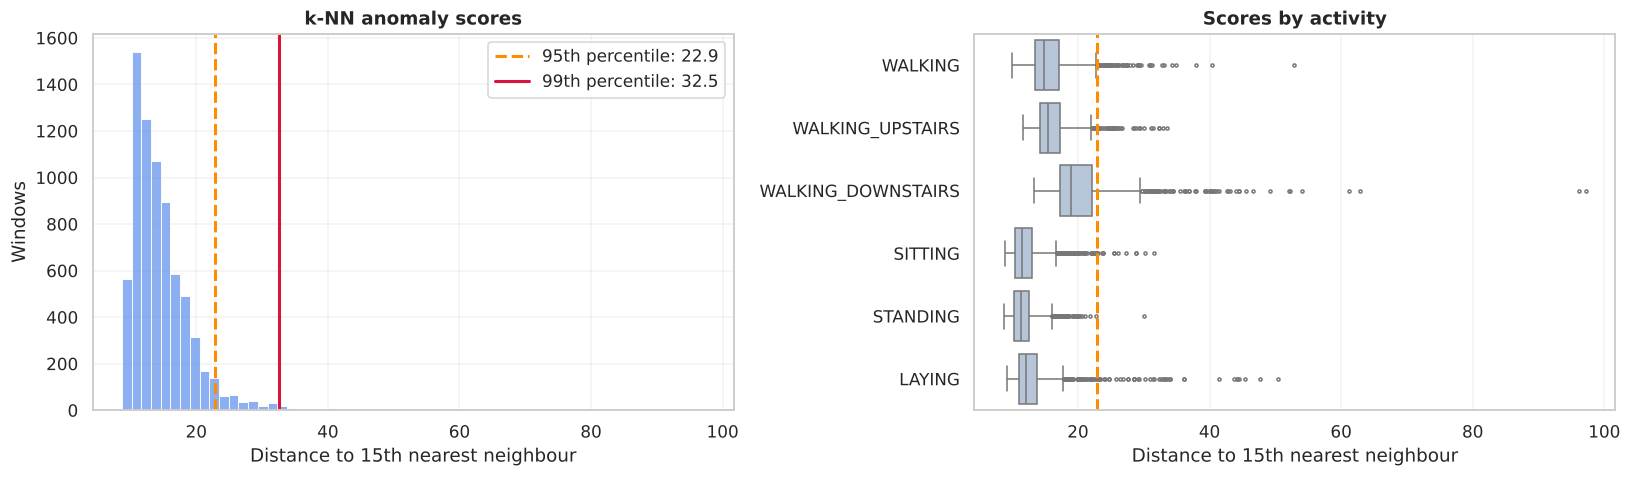

Top 15 windows for inspection:


,row,subject_id,activity_name,segment_id,pos_in_segment,knn_score
3934,3934,19,WALKING_DOWNSTAIRS,340,0,97.2462
3935,3935,19,WALKING_DOWNSTAIRS,340,1,96.1703
3939,3939,19,WALKING_DOWNSTAIRS,340,5,62.8828
3936,3936,19,WALKING_DOWNSTAIRS,340,2,61.2295
3928,3928,19,WALKING_DOWNSTAIRS,339,0,54.0902
3915,3915,19,WALKING,337,12,52.7890
3930,3930,19,WALKING_DOWNSTAIRS,339,2,52.2215
3958,3958,19,WALKING_DOWNSTAIRS,343,5,52.0661
2451,2451,14,LAYING,223,0,50.4733
3929,3929,19,WALKING_DOWNSTAIRS,339,1,49.2275


In [63]:
p99 = np.percentile(t6["knn_score"], 99)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(t6["knn_score"], bins=60, color="cornflowerblue", ax=axes[0])
axes[0].axvline(threshold, color="darkorange", ls="--", lw=2, label=f"{TOP_PCT}th percentile: {threshold:.1f}")
axes[0].axvline(p99, color="crimson", lw=2, label=f"99th percentile: {p99:.1f}")
axes[0].set(title="k-NN anomaly scores", xlabel=f"Distance to {K}th nearest neighbour", ylabel="Windows")
axes[0].legend()
sns.boxplot(data=t6, x="knn_score", y="activity_name", order=ACTIVITY_ORDER, color="lightsteelblue",
            fliersize=2, ax=axes[1])
axes[1].axvline(threshold, color="darkorange", ls="--", lw=2)
axes[1].set(title="Scores by activity", xlabel=f"Distance to {K}th nearest neighbour", ylabel="")
plt.tight_layout()
plt.show()

print("Top 15 windows for inspection:")
display(t6.nlargest(15, "knn_score")[["row", "subject_id", "activity_name", "segment_id",
                                      "pos_in_segment", "knn_score"]])

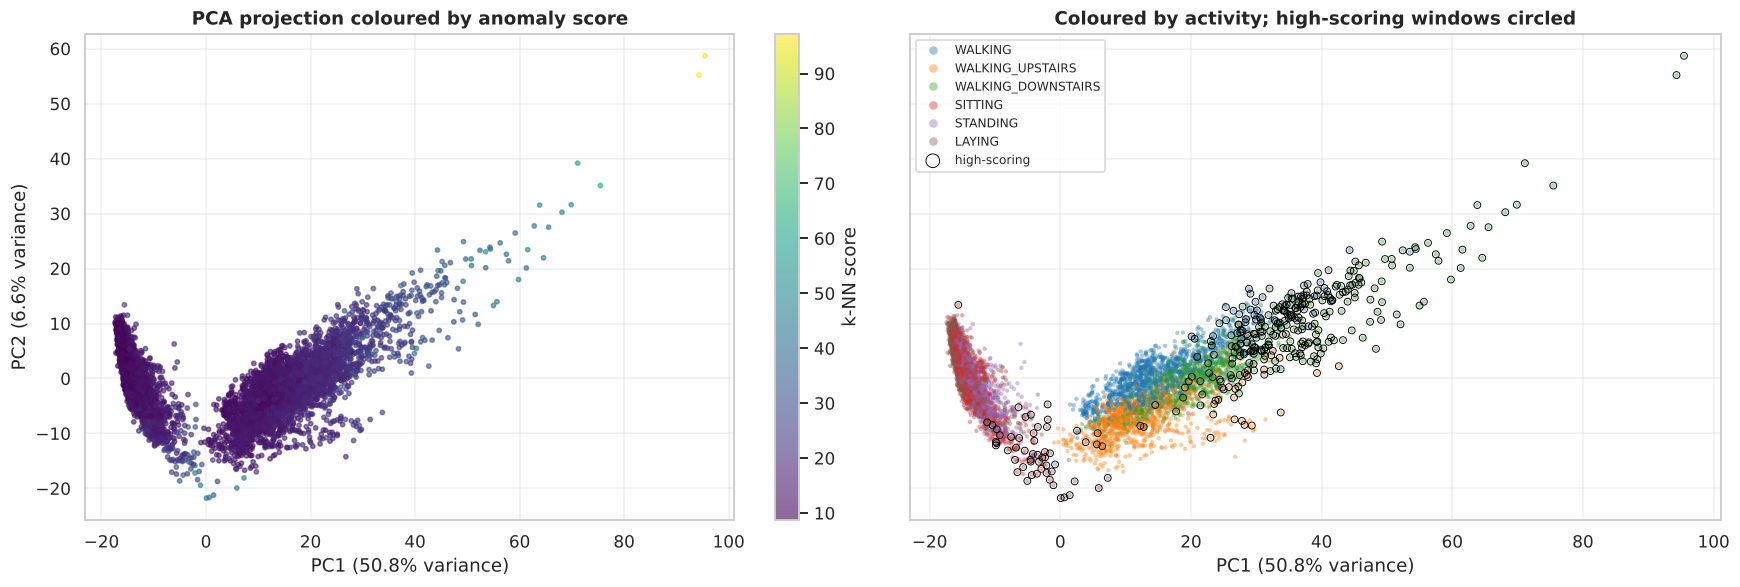

In [64]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_train_scaled)
t6["PC1"], t6["PC2"] = pcs[:, 0], pcs[:, 1]
ev = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True, sharey=True)
sc = axes[0].scatter(t6["PC1"], t6["PC2"], c=t6["knn_score"], cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, ax=axes[0], label="k-NN score")
axes[0].set_title("PCA projection coloured by anomaly score")
sns.scatterplot(data=t6, x="PC1", y="PC2", hue="activity_name", hue_order=ACTIVITY_ORDER, palette="tab10",
                s=8, alpha=0.4, linewidth=0, ax=axes[1])
high = t6[t6["is_high"]]
axes[1].scatter(high["PC1"], high["PC2"], facecolors="none", edgecolors="black", s=20, linewidths=0.6,
                label="high-scoring")
axes[1].legend(markerscale=2, fontsize=8)
axes[1].set_title("Coloured by activity; high-scoring windows circled")
for ax in axes:
    ax.set(xlabel=f"PC1 ({ev[0]:.1f}% variance)", ylabel=f"PC2 ({ev[1]:.1f}% variance)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 6.3 Concentration across activities and participants
Activities and participants have different numbers of windows, so we compare **rates**, not counts. For participants the expected count uses each window's activity rate, so someone with more walking-downstairs windows is not counted as unusual just for that.

In [65]:
from scipy.stats import binomtest


def holm(pvals):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, float)
    adj, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj


act_conc = t6.groupby("activity_name").agg(n=("is_high", "size"), n_high=("is_high", "sum"),
                                           rate=("is_high", "mean"))
act_conc["enrichment"] = act_conc["rate"] / BASE_RATE
act_conc["p_holm"] = holm([binomtest(int(k), int(n), BASE_RATE, alternative="greater").pvalue
                           for k, n in zip(act_conc["n_high"], act_conc["n"])])

t6["activity_rate"] = t6.groupby("activity_id")["is_high"].transform("mean")
subj_conc = t6.groupby("subject_id").agg(n=("is_high", "size"), n_high=("is_high", "sum"),
                                         expected=("activity_rate", "sum"), rate=("is_high", "mean"))
subj_conc["enrichment_adj"] = subj_conc["n_high"] / subj_conc["expected"]
subj_conc["share_of_high"] = subj_conc["n_high"] / subj_conc["n_high"].sum()

display(act_conc.sort_values("enrichment", ascending=False)
        .style.format({"rate": "{:.1%}", "enrichment": "{:.2f}", "p_holm": "{:.2g}"}))
display(subj_conc.sort_values("enrichment_adj", ascending=False).head(8)
        .style.format({"expected": "{:.1f}", "rate": "{:.1%}", "enrichment_adj": "{:.2f}",
                       "share_of_high": "{:.1%}"}))

,n,n_high,rate,enrichment,p_holm
activity_name,,,,,
WALKING_DOWNSTAIRS,986,208,21.1%,4.21,1.3e-68
WALKING,1226,61,5.0%,0.99,1
WALKING_UPSTAIRS,1073,42,3.9%,0.78,1
LAYING,1407,43,3.1%,0.61,1
SITTING,1286,13,1.0%,0.20,1
STANDING,1374,1,0.1%,0.01,1


,n,n_high,expected,rate,enrichment_adj,share_of_high
subject_id,,,,,,
19,360,64,15.7,17.8%,4.07,17.4%
8,281,52,14.2,18.5%,3.67,14.1%
23,372,61,19.3,16.4%,3.17,16.6%
14,323,51,16.7,15.8%,3.06,13.9%
6,325,44,17.3,13.5%,2.54,12.0%
25,409,24,21.4,5.9%,1.12,6.5%
1,347,17,19.2,4.9%,0.89,4.6%
7,308,12,16.9,3.9%,0.71,3.3%


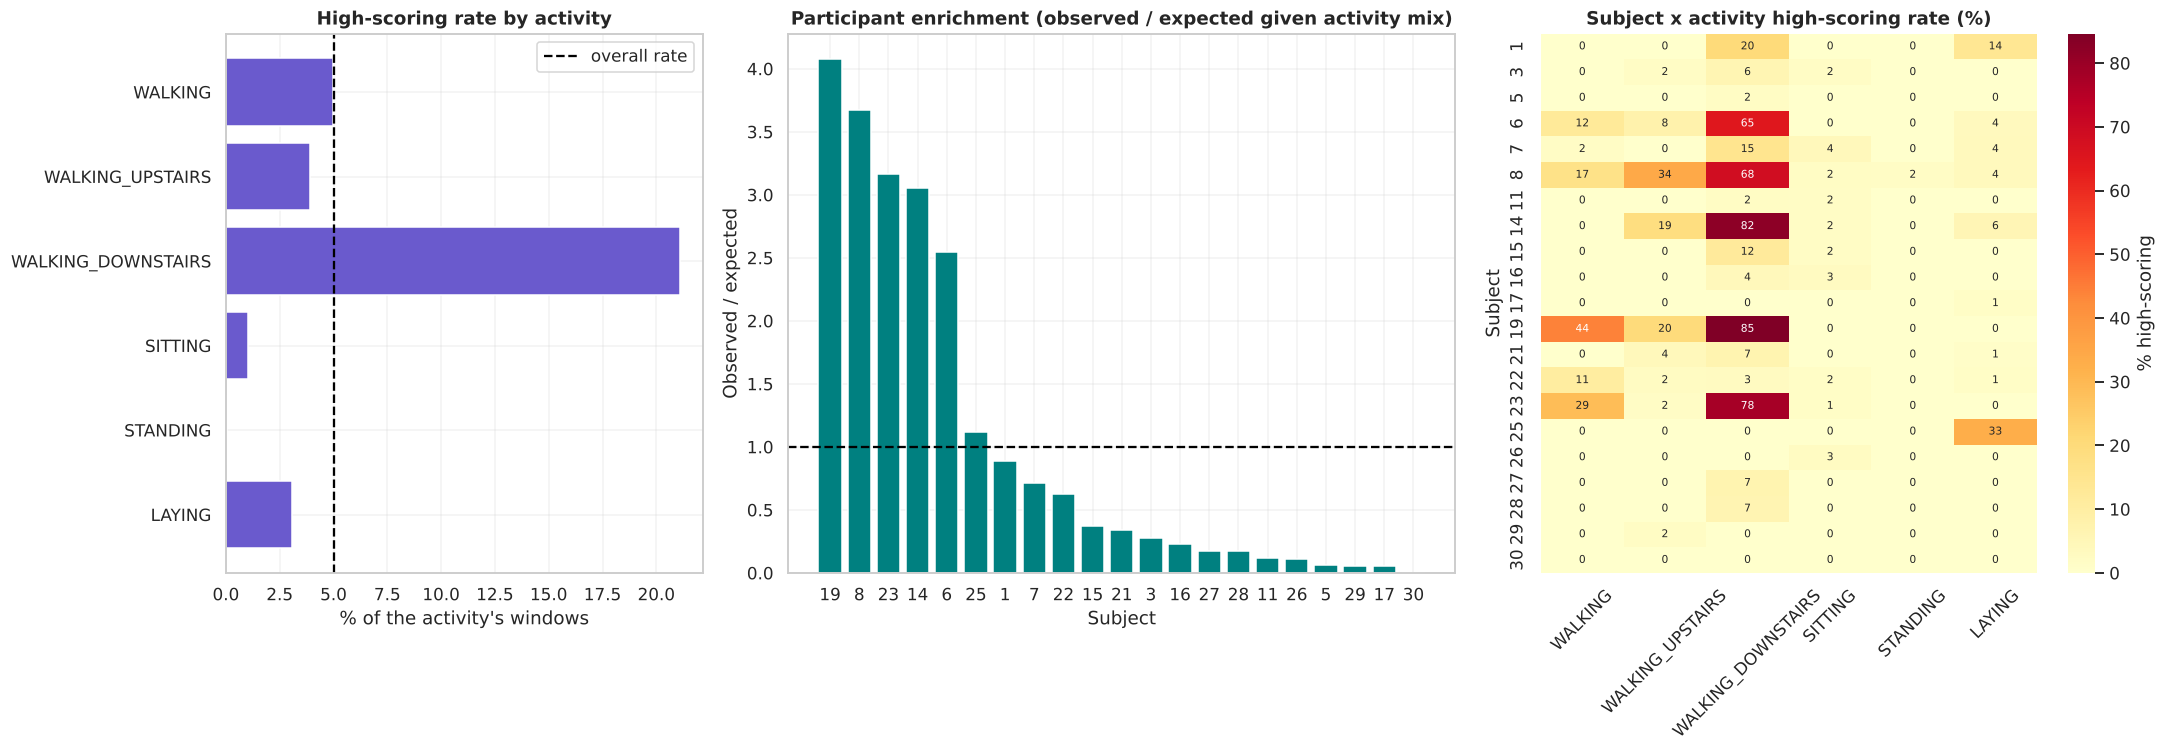

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7), gridspec_kw={"width_ratios": [1, 1.4, 1.3]})

a = act_conc.reindex(ACTIVITY_ORDER)
axes[0].barh(a.index, a["rate"] * 100, color="slateblue")
axes[0].axvline(BASE_RATE * 100, color="black", ls="--", label="overall rate")
axes[0].invert_yaxis()
axes[0].set(title="High-scoring rate by activity", xlabel="% of the activity's windows")
axes[0].legend()

s = subj_conc.sort_values("enrichment_adj", ascending=False)
axes[1].bar(s.index.astype(str), s["enrichment_adj"], color="teal")
axes[1].axhline(1, color="black", ls="--")
axes[1].set(title="Participant enrichment (observed / expected given activity mix)",
            xlabel="Subject", ylabel="Observed / expected")

rate_mat = t6.pivot_table(index="subject_id", columns="activity_name", values="is_high",
                          aggfunc="mean")[ACTIVITY_ORDER] * 100
sns.heatmap(rate_mat, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% high-scoring"}, ax=axes[2])
axes[2].set(title="Subject x activity high-scoring rate (%)", xlabel="", ylabel="Subject")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

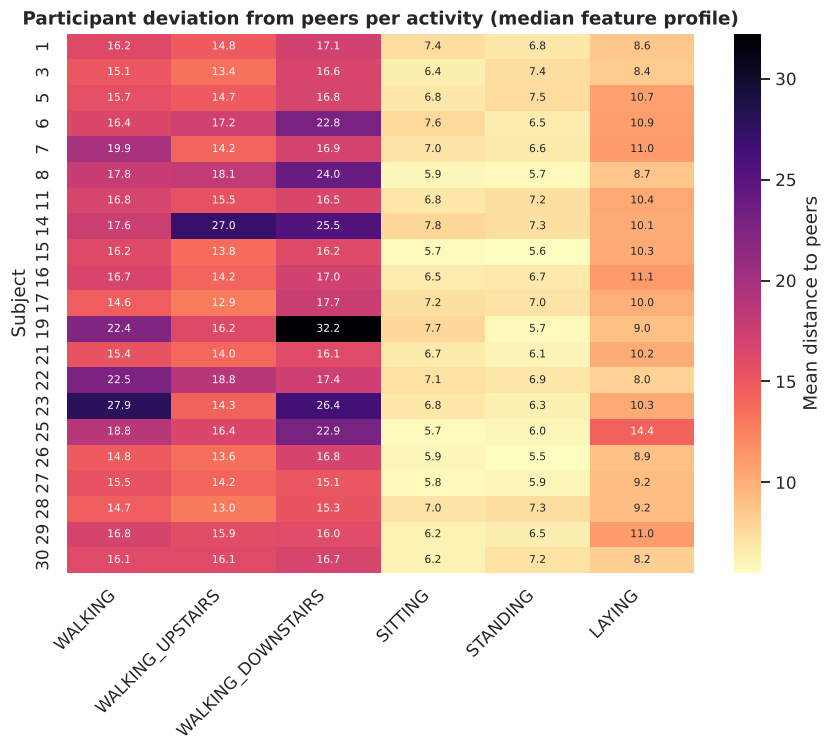

In [67]:
# Participant deviation from peers within each activity (distance between median feature profiles)
from scipy.spatial.distance import cdist

profiles = (pd.DataFrame(X_train_scaled)
            .assign(subject_id=t6["subject_id"].values, activity_name=t6["activity_name"].values)
            .groupby(["activity_name", "subject_id"]).median())
rows = []
for act_name, grp in profiles.groupby(level="activity_name"):
    D = cdist(grp.values, grp.values)
    np.fill_diagonal(D, np.nan)
    rows += [{"activity_name": act_name, "subject_id": s, "mean_distance_to_peers": d}
             for s, d in zip(grp.index.get_level_values("subject_id"), np.nanmean(D, axis=1))]
peer_dev = (pd.DataFrame(rows)
            .pivot(index="subject_id", columns="activity_name", values="mean_distance_to_peers")[ACTIVITY_ORDER])

plt.figure(figsize=(8, 7))
sns.heatmap(peer_dev, cmap="magma_r", annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Mean distance to peers"})
plt.title("Participant deviation from peers per activity (median feature profile)")
plt.xlabel("")
plt.ylabel("Subject")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 6.4 Do high-scoring windows have other unusual windows nearby?
Two kinds of neighbour: the K nearest windows in **feature space** from *other* recording segments (adjacent windows overlap, so same-segment neighbours are trivially similar), and the windows 2 steps before/after in the **same recording** (lag 2, because lag-1 windows share half their samples).

In [68]:
# Adjacent windows of one recording overlap by 50%, so they are each other's nearest neighbours.
# To ask "are there similar unusual windows ELSEWHERE?", take the K nearest windows from OTHER segments.
N_WIDE = 80   # longest segment has 48 windows, so 80 always leaves >= K from other segments
_, idx_wide = nn_global.kneighbors(X_train_scaled, n_neighbors=N_WIDE + 1)
idx_wide = idx_wide[:, 1:]
seg = t6["segment_id"].to_numpy()
other_seg = seg[idx_wide] != seg[:, None]
assert other_seg.sum(axis=1).min() >= K
idx_xseg = np.take_along_axis(idx_wide, np.argsort(~other_seg, axis=1, kind="stable")[:, :K], axis=1)
print(f"Share of the global {K} nearest neighbours that come from the same recording segment: "
      f"{(seg[idx_global] == seg[:, None]).mean():.0%}")

high_flag = t6["is_high"].to_numpy()
subj = t6["subject_id"].to_numpy()
act = t6["activity_id"].to_numpy()
t6["frac_nbrs_high"] = high_flag[idx_xseg].mean(axis=1)
t6["frac_nbrs_same_subject"] = (subj[idx_xseg] == subj[:, None]).mean(axis=1)
t6["frac_nbrs_same_activity"] = (act[idx_xseg] == act[:, None]).mean(axis=1)

seg_len = t6.groupby("segment_id")["row"].transform("size")
t6["at_segment_edge"] = (t6["pos_in_segment"] < 2) | (t6["pos_in_segment"] >= seg_len - 2)

seg_flags = t6.groupby("segment_id")["is_high"]
t6["temporal_nbr_high"] = (seg_flags.shift(2, fill_value=False) | seg_flags.shift(-2, fill_value=False))

t6["nbr_pattern"] = pd.cut(t6["frac_nbrs_high"], [-0.01, 0, 0.2, 1.0],
                           labels=["isolated (0 high nbrs)", "sparse (<=20%)", "grouped (>20%)"])
high = t6[t6["is_high"]]
print(f"High-scoring windows: on average {high['frac_nbrs_high'].mean():.0%} of their {K} nearest windows from other "
      f"segments are also high-scoring (random flags would give {BASE_RATE:.0%}).")
print(f"{high['temporal_nbr_high'].mean():.0%} have a high-scoring window 2 steps away in the same recording "
      f"(vs {t6.loc[~t6['is_high'], 'temporal_nbr_high'].mean():.0%} for other windows).")
print(f"{high['at_segment_edge'].mean():.0%} of high-scoring windows lie within 2 windows of a recording's start/end "
      f"(vs {t6['at_segment_edge'].mean():.0%} of all windows).")

nbr_summary = high.groupby("activity_name").agg(
    n_high=("is_high", "size"),
    isolated=("nbr_pattern", lambda s: (s == "isolated (0 high nbrs)").mean()),
    grouped=("nbr_pattern", lambda s: (s == "grouped (>20%)").mean()),
    nbrs_same_subject=("frac_nbrs_same_subject", "mean"),
    temporal_nbr_high=("temporal_nbr_high", "mean"),
    at_segment_edge=("at_segment_edge", "mean"),
).reindex([a for a in ACTIVITY_ORDER if a in high["activity_name"].unique()])
display(nbr_summary.style.format("{:.0%}", subset=nbr_summary.columns[1:]))

Share of the global 15 nearest neighbours that come from the same recording segment: 22%
High-scoring windows: on average 45% of their 15 nearest windows from other segments are also high-scoring (random flags would give 5%).
61% have a high-scoring window 2 steps away in the same recording (vs 3% for other windows).
52% of high-scoring windows lie within 2 windows of a recording's start/end (vs 33% of all windows).


,n_high,isolated,grouped,nbrs_same_subject,temporal_nbr_high,at_segment_edge
activity_name,,,,,,
WALKING,61,10%,52%,77%,57%,28%
WALKING_UPSTAIRS,42,21%,21%,63%,29%,62%
WALKING_DOWNSTAIRS,208,6%,75%,64%,75%,56%
SITTING,13,31%,54%,3%,0%,85%
STANDING,1,0%,100%,13%,0%,100%
LAYING,43,7%,60%,23%,49%,44%


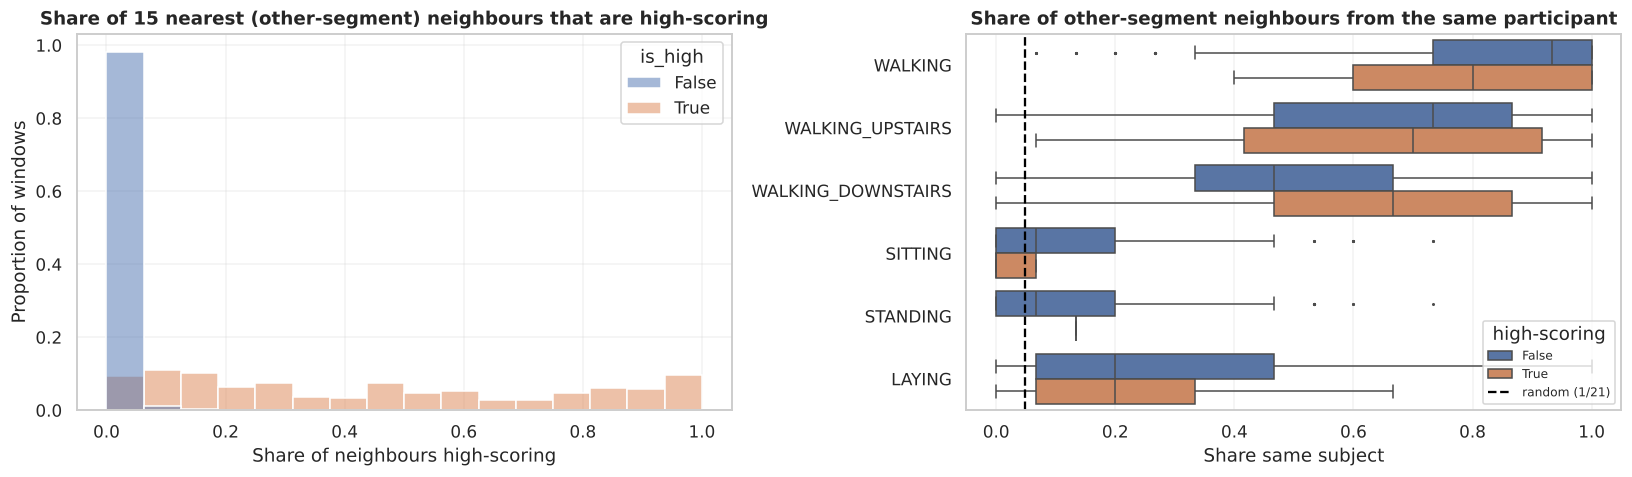

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=t6, x="frac_nbrs_high", hue="is_high", stat="probability", common_norm=False,
             bins=np.linspace(0, 1, K + 2), ax=axes[0])
axes[0].set(title=f"Share of {K} nearest (other-segment) neighbours that are high-scoring",
            xlabel="Share of neighbours high-scoring", ylabel="Proportion of windows")
sns.boxplot(data=t6, x="frac_nbrs_same_subject", y="activity_name", hue="is_high", order=ACTIVITY_ORDER,
            fliersize=1, ax=axes[1])
axes[1].axvline(1 / t6["subject_id"].nunique(), color="black", ls="--", label="random (1/21)")
axes[1].set(title="Share of other-segment neighbours from the same participant", xlabel="Share same subject", ylabel="")
axes[1].legend(title="high-scoring", fontsize=8)
plt.tight_layout()
plt.show()

#### 6.5 Raw inertial-signal characteristics
Simple per-window signal descriptors: intensity (RMS / peak body acceleration, RMS rotation), periodicity (dominant frequency and the share of spectral energy there) and orientation (mean gravity direction). The table shows how far high-scoring windows sit from the other windows of the same activity, in units of that activity's IQR.

In [70]:
FS = 50  # Hz


def magnitude(sig, name):
    return np.sqrt(sig[f"{name}_x"] ** 2 + sig[f"{name}_y"] ** 2 + sig[f"{name}_z"] ** 2)


acc_mag = magnitude(inertial_train, "body_acc")     # g, gravity removed
gyro_mag = magnitude(inertial_train, "body_gyro")   # rad/s
freqs = np.fft.rfftfreq(128, d=1 / FS)
spec = np.abs(np.fft.rfft(acc_mag - acc_mag.mean(axis=1, keepdims=True), axis=1))[:, 1:]

SIG_COLS = ["acc_rms", "acc_peak", "gyro_rms", "dominant_freq_hz", "periodicity",
            "gravity_x", "gravity_y", "gravity_z"]
sig_feats = pd.DataFrame({
    "acc_rms": np.sqrt((acc_mag ** 2).mean(axis=1)),
    "acc_peak": acc_mag.max(axis=1),
    "gyro_rms": np.sqrt((gyro_mag ** 2).mean(axis=1)),
    "dominant_freq_hz": freqs[1:][spec.argmax(axis=1)],
    "periodicity": spec.max(axis=1) / spec.sum(axis=1),
    "gravity_x": inertial_train["total_acc_x"].mean(axis=1),
    "gravity_y": inertial_train["total_acc_y"].mean(axis=1),
    "gravity_z": inertial_train["total_acc_z"].mean(axis=1),
})
t6 = t6.drop(columns=SIG_COLS, errors="ignore").join(sig_feats)


def robust_shift(grp):
    """(median of high-scoring - median of others) / IQR of others, per signal descriptor."""
    hi, lo = grp.loc[grp["is_high"], SIG_COLS], grp.loc[~grp["is_high"], SIG_COLS]
    iqr = (lo.quantile(0.75) - lo.quantile(0.25)).replace(0, np.nan)
    return (hi.median() - lo.median()) / iqr


shift_tbl = (t6.groupby("activity_name")[SIG_COLS + ["is_high"]].apply(robust_shift)
             .reindex(ACTIVITY_ORDER))
shift_tbl["n_high"] = t6.groupby("activity_name")["is_high"].sum().reindex(ACTIVITY_ORDER)
display(shift_tbl.style.format("{:+.2f}", subset=SIG_COLS)
        .background_gradient(cmap="RdBu_r", vmin=-3, vmax=3, subset=SIG_COLS)
        .set_caption("Shift of high-scoring windows vs other windows of the same activity (in IQRs)"))

,acc_rms,acc_peak,gyro_rms,dominant_freq_hz,periodicity,gravity_x,gravity_y,gravity_z,n_high
activity_name,,,,,,,,,
WALKING,+1.59,+1.31,+1.49,+1.00,-0.32,-0.19,+0.18,-0.57,61
WALKING_UPSTAIRS,+1.09,+0.91,+1.57,-0.40,-0.73,-1.07,-0.23,-0.97,42
WALKING_DOWNSTAIRS,+0.75,+1.08,+1.63,-0.60,-0.41,-0.67,-0.39,-0.67,208
SITTING,+20.36,+18.24,+3.64,+0.00,+1.91,-0.11,+0.38,+0.03,13
STANDING,+17.19,+14.90,+5.10,+0.00,+1.88,-1.95,+0.45,-1.27,1
LAYING,+21.88,+19.79,+8.52,-0.50,+1.41,-0.67,-0.55,+0.34,43


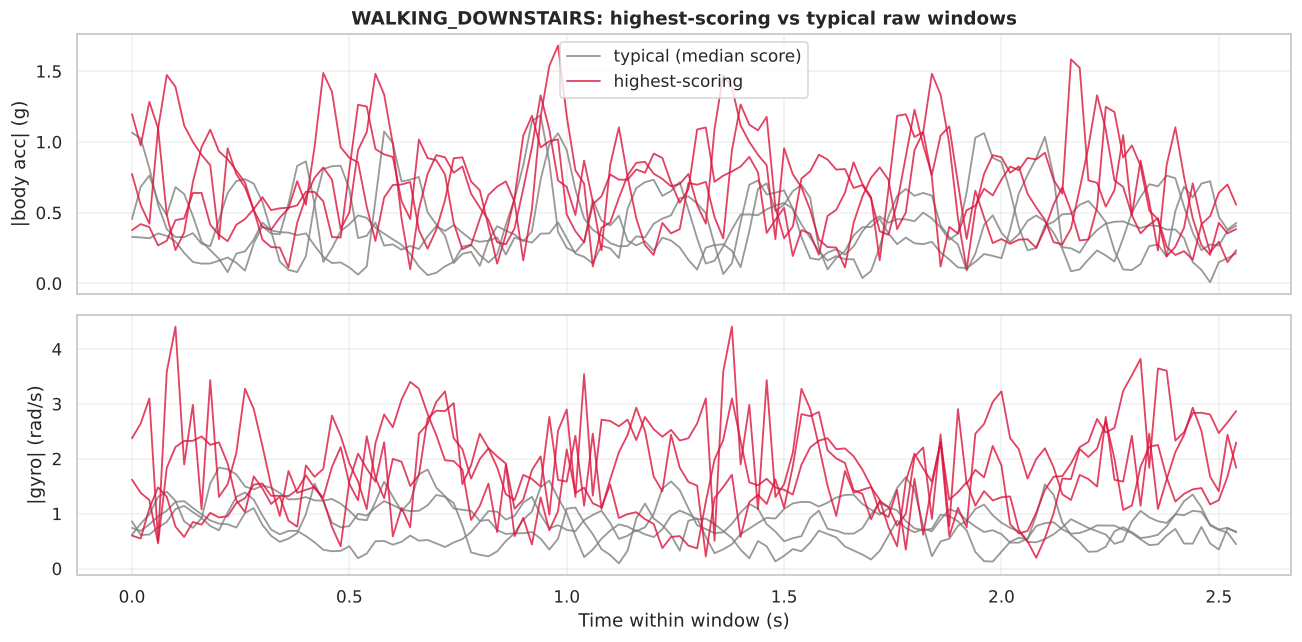

,subject_id,knn_score,acc_rms,acc_peak,gyro_rms,dominant_freq_hz,periodicity
3934,19,97.246,0.739,1.681,2.015,2.344,0.073
3935,19,96.170,0.734,1.482,2.102,2.344,0.099
3939,19,62.883,0.749,1.583,1.708,2.344,0.081
2673,15,19.001,0.512,1.066,0.725,3.906,0.086
6934,29,19.000,0.438,1.073,1.023,3.516,0.161
2338,14,18.988,0.415,1.188,0.895,3.516,0.094


In [71]:
EXAMPLE_ACTIVITY = "WALKING_DOWNSTAIRS"
ex = t6[t6["activity_name"] == EXAMPLE_ACTIVITY]
top_idx = ex.nlargest(3, "knn_score").index
typical_idx = (ex["knn_score"] - ex["knn_score"].median()).abs().nsmallest(3).index
tt = np.arange(128) / FS

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for idxs, color, lab in [(typical_idx, "grey", "typical (median score)"), (top_idx, "crimson", "highest-scoring")]:
    for j, i in enumerate(idxs):
        kw = dict(color=color, alpha=0.8, lw=1.2, label=lab if j == 0 else None)
        axes[0].plot(tt, acc_mag[i], **kw)
        axes[1].plot(tt, gyro_mag[i], **kw)
axes[0].set(ylabel="|body acc| (g)", title=f"{EXAMPLE_ACTIVITY}: highest-scoring vs typical raw windows")
axes[1].set(ylabel="|gyro| (rad/s)", xlabel="Time within window (s)")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(t6.loc[list(top_idx) + list(typical_idx),
               ["subject_id", "knn_score", "acc_rms", "acc_peak", "gyro_rms", "dominant_freq_hz", "periodicity"]]
        .round(3))

#### 6.6 Global vs restricted neighbourhoods
The same k-NN score computed (a) against all windows, (b) only against windows of the same activity, and (c) only against the same participant doing the same activity. None of these is ground truth; the question is how much the shortlist depends on the choice.

In [72]:
def knn_score_within(X, frame, group_cols, k):
    """k-NN distance computed only among windows that share the same group."""
    scores = np.full(len(X), np.nan)
    for _, idx in frame.groupby(group_cols).indices.items():
        kk = min(k, len(idx) - 1)
        d, _ = NearestNeighbors(n_neighbors=kk + 1).fit(X[idx]).kneighbors(X[idx])
        scores[idx] = d[:, kk]
    return scores


K_SUBJECT = 5   # subject-activity groups only hold 36-95 windows, so use a smaller neighbourhood
t6["score_within_activity"] = knn_score_within(X_train_scaled, t6, "activity_id", K)
t6["score_within_subject_activity"] = knn_score_within(X_train_scaled, t6, ["subject_id", "activity_id"], K_SUBJECT)
t6["local_distance"] = t6["score_within_activity"]   # used by the within-person deviation cell below

SCORES = {"global": "knn_score", "within activity": "score_within_activity",
          "within subject+activity": "score_within_subject_activity"}
flags = pd.DataFrame({name: t6[col] > np.percentile(t6[col], TOP_PCT) for name, col in SCORES.items()})


def jaccard(a, b):
    return (a & b).sum() / (a | b).sum()


names = list(SCORES)
print("Spearman rank correlation between scores:")
display(t6[list(SCORES.values())].set_axis(names, axis=1).corr(method="spearman").round(2))
print("Overlap of the top-5% shortlists (Jaccard):")
display(pd.DataFrame([[jaccard(flags[a], flags[b]) for b in names] for a in names],
                     index=names, columns=names).round(2))

Spearman rank correlation between scores:


,global,within activity,within subject+activity
global,1.00,1.00,0.94
within activity,1.00,1.00,0.94
within subject+activity,0.94,0.94,1.00


Overlap of the top-5% shortlists (Jaccard):


,global,within activity,within subject+activity
global,1.00,0.95,0.70
within activity,0.95,1.00,0.72
within subject+activity,0.70,0.72,1.00


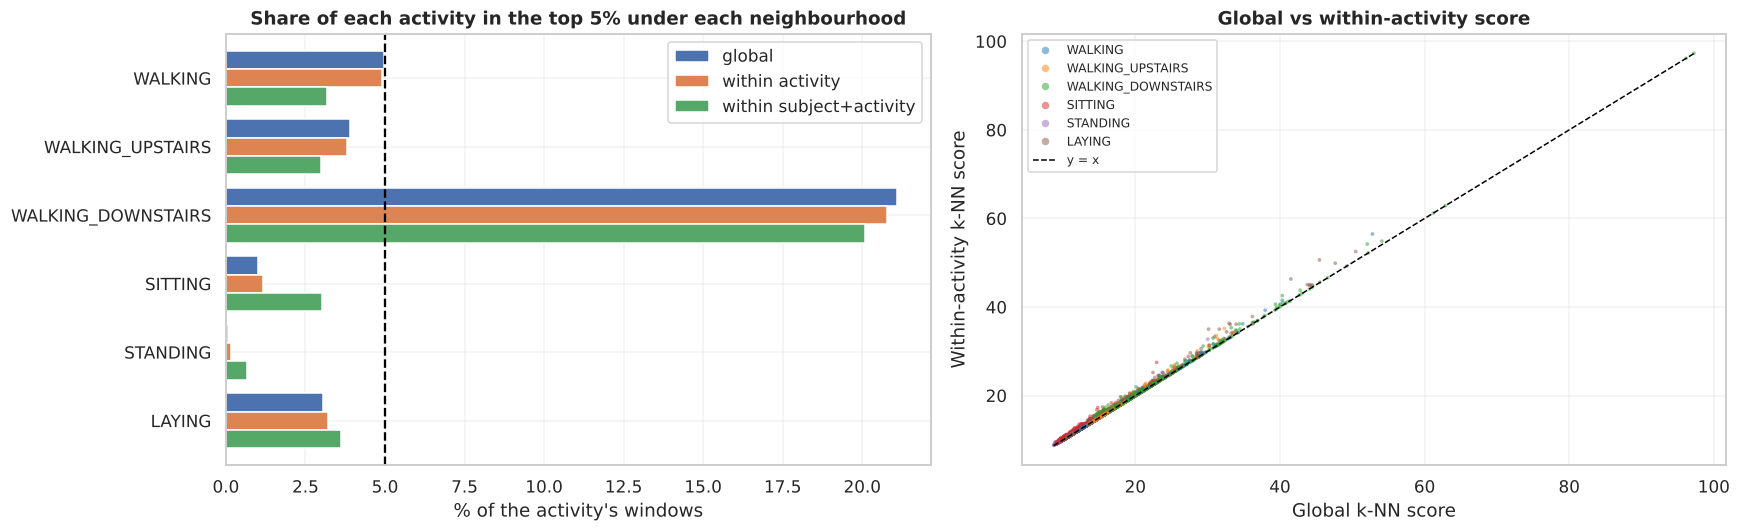

In [73]:
rate_by_act = flags.groupby(t6["activity_name"]).mean().reindex(ACTIVITY_ORDER) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rate_by_act.plot.barh(ax=axes[0], width=0.8)
axes[0].invert_yaxis()
axes[0].axvline(100 - TOP_PCT, color="black", ls="--")
axes[0].set(title="Share of each activity in the top 5% under each neighbourhood",
            xlabel="% of the activity's windows", ylabel="")
sns.scatterplot(data=t6, x="knn_score", y="score_within_activity", hue="activity_name", hue_order=ACTIVITY_ORDER,
                palette="tab10", s=6, alpha=0.5, linewidth=0, ax=axes[1])
lims = [t6["knn_score"].min(), t6["score_within_activity"].max()]
axes[1].plot(lims, lims, color="black", lw=1, ls="--", label="y = x")
axes[1].set(title="Global vs within-activity score", xlabel="Global k-NN score",
            ylabel="Within-activity k-NN score")
axes[1].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

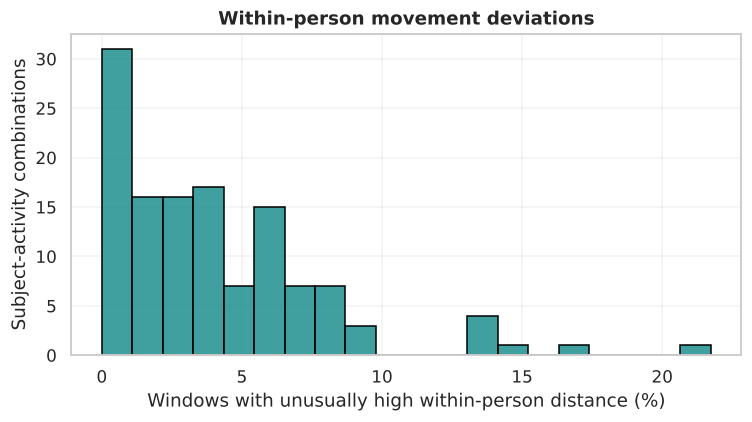

,subject_id,activity_id,n_windows,deviation_rate,activity_name
57,16,4,69,21.7391,SITTING
35,8,6,54,16.6667,LAYING
34,8,5,54,14.8148,STANDING
23,6,6,57,14.0351,LAYING
5,1,6,50,14.0000,LAYING
104,27,3,44,13.6364,WALKING_DOWNSTAIRS
87,23,4,68,13.2353,SITTING
41,11,6,57,8.7719,LAYING
33,8,4,46,8.6957,SITTING
78,22,1,46,8.6957,WALKING


Overlap of within-person deviations with the global shortlist (Jaccard): 0.14


In [74]:
# Within-person deviation: is a window unusual compared with the SAME person's other windows of that activity?
group_cols = ["subject_id", "activity_id"]
group_median = t6.groupby(group_cols)["local_distance"].transform("median")
group_mad = (t6["local_distance"] - group_median).abs().groupby([t6[c] for c in group_cols]).transform("median")
denominator = 1.4826 * group_mad

# near-zero MAD groups are left undefined rather than treating tiny differences as extreme
t6["local_robust_score"] = (t6["local_distance"] - group_median) / denominator.where(denominator > 1e-10)
ROBUST_Z = 3.5   # illustrative threshold, not a ground-truth label
t6["is_within_group_deviation"] = t6["local_robust_score"] > ROBUST_Z

comb_summary = (t6.groupby(group_cols)
                .agg(n_windows=("local_distance", "size"), deviation_rate=("is_within_group_deviation", "mean"))
                .reset_index())
comb_summary["deviation_rate"] *= 100
comb_summary["activity_name"] = comb_summary["activity_id"].map(ACTIVITY_NAMES)

plt.figure(figsize=(7, 4))
sns.histplot(comb_summary["deviation_rate"], bins=20, color="teal", edgecolor="black")
plt.xlabel("Windows with unusually high within-person distance (%)")
plt.ylabel("Subject-activity combinations")
plt.title("Within-person movement deviations")
plt.tight_layout()
plt.show()

display(comb_summary.sort_values("deviation_rate", ascending=False).head(10))
print(f"Overlap of within-person deviations with the global shortlist (Jaccard): "
      f"{jaccard(t6['is_within_group_deviation'], t6['is_high']):.2f}")

#### Task 6 findings (preliminary)
*These come from the baseline k-NN score (k = 15, top 5% = 368 windows). They mark what deserves further investigation; none of it is ground truth.*

1. **Walking downstairs dominates the shortlist.** 21% of its windows are high-scoring, 4.2× the overall rate (Holm p ≈ 1e-68). Standing (0.1%) and sitting (1%) are almost never flagged.
2. **A few participants account for most of it.** Subjects 19, 8, 23, 14 and 6 hold 74% of high-scoring windows. Each has 2.5–4× more than expected given their activity mix, and 65–85% of their downstairs windows are flagged. Subject 19 is distinctive beyond one activity (44% of walking windows also flagged). Subject 25's 33% laying rate is a separate case.
3. **High-scoring windows are not isolated points.** On average 45% of their nearest windows from *other* recordings are also high-scoring (5% expected at random). 61% have another high-scoring window two steps later in the same recording (3% for other windows). The top-ranked windows are consecutive windows from one subject-19 downstairs recording.
4. **Part of it comes from recording boundaries.** 52% of high-scoring windows lie within two windows of a recording's start or end (33% of all windows). For sitting the figure is 85%.
5. **Raw signals.** Dynamic high-scoring windows have higher intensity: body-acceleration RMS is 0.8–1.6 IQRs and rotation 1.5 IQRs above other windows of the same activity. Static high-scoring windows carry about 20 IQRs more body acceleration, meaning they contain real movement such as posture transitions rather than stillness.
6. **The choice of neighbourhood matters only partly.** Restricting neighbours to the same activity barely changes anything (ρ = 1.00, shortlist overlap 0.95), because global neighbours are already same-activity. Restricting to the same person and activity changes the shortlist more (overlap 0.70). Within-person deviations hardly overlap with the global shortlist (Jaccard 0.14), so they capture a different kind of unusualness.

**Open for RQ3:** points 2–3 suggest consistent individual differences in dynamic activities rather than one-off glitches. Point 4 suggests some static "anomalies" are labelling or transition artefacts.


## Research Questions

### Research Question 1
**Members**: Atharva & Abrar

**Main Research Question:** Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised movement patterns?

**Methodology:**
1.	Perform unsupervised clustering (e.g., K-Means, GMM) on the 561-feature space.
2.  Analyze the resulting cluster structures (evaluate whether they form distinct groups or hierarchical sub-clusters)
3.  Compare unsupervized cluster assignment directuly against the hierarchical sub-clusters)
4.  Analyze divergence between machine-discovered structures vs human labeled classes

**Sub-Questions & Focus:**

1. Are the clusters truly 6 distinct groups mirroring the activity labels?
2. Can a geometric hierarchy be discovered within the space (e.g., are walking flat and walking upstairs grouped closer together than sitting and standing)?
3. How clearly do static postures separate from dynamic movements?

In [75]:
# Code for Question 1

### Research Question 2
**Members**: Youssef & Sushanth

**Main Research Question:** Are some forms of human movement inherently more variable than others, and does this diversity explain why they appear disproportionately unusual?

**Methodology:**
1.	Execute anomaly detection models (e.g., Isolation Forest, density-based outlier scoring) across the feature space.
2.	Map anomaly and outlier scores directly back against cluster boundaries and feature variance metrics.
3.	Analyze whether anomaly concentrations are isolated to specific activities or driven by high-variance physical regimes.

**Questions and Focus:**
1. Are high-intensity or dynamic activities (like walking downstairs) inherently more variable, causing them to trigger false anomaly flags?
2. Are anomalies uniformly distributed across all activities, or clustered heavily in specific movement transitions?
3. Do unusual scores reflect true physical irregularities or geometric boundary crowding?


In [76]:
# Code for Question 2

### Research Question 3
**Members**: Muhatasim & Subhashini

**Main Research Question:** Do unusual movement observations represent consistent differences in how individuals move, or isolated departures from otherwise typical movement behaviour?

**Methodology:**
1.	Take the cluster assignments and anomaly shortlists generated in RQ1 and RQ2.
2.	Cross-tabulate these spatial outputs against the known subject ID metadata (the 30 participants).
3.	Evaluate whether outlier concentrations are driven by single individuals or shared across multiple subjects.
4.	Investigate how individual biometric walking styles interact with global unsupervised boundaries (leveraging the sequential nature of data per subject).

**Sub-questions and focus:**
1. Are the top anomalies dominated by a single eccentric participant (e.g., one subject's unique stride), or are they common instances experienced across many people?
2. Does the unsupervised space fracture by participant identity rather than activity class?
3. How does unmanaged inter-subject variance distort global anomaly detection?


In [77]:
# Code for Question 3